In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/crahulnaidu/mobile-net-100/__notebook__.ipynb
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/__output__.json
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/__results__.html
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/custom.css
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/checkpoints/mobilenetv2_cifar100_best.pth
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/checkpoints/mobilenetv2_cifar100_latest.pth
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/config/environment.json
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/config/training_summary.json
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/data/data_split_indices.json
/kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/data/dataset_manifest.json
/kaggle/input/notebooks/crah

In [2]:

# =====================================================================
# JFAMP — INPUT DIRECTORY AUDIT BEFORE STAGE B ANALYSIS
#
# Purpose:
# Verify that the new Kaggle notebook has all required Stage B
# artifacts before beginning the next analysis stage.
#
# Searches:
#   1. /kaggle/input recursively
#   2. CSV/JSON files directly
#   3. ZIP archives and their internal contents
#
# Does not modify or delete any source files.
# =====================================================================

import os
import json
import zipfile
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np

INPUT_ROOT = Path("/kaggle/input")

EXPECTED_LAYERS = 53
EXPECTED_FORMATS = 7
EXPECTED_CLEAN = 371
EXPECTED_TRIALS = 3710
EXPECTED_FAULT_BITS = {1, 8}
EXPECTED_REALIZATIONS = {1, 2, 3, 4, 5}

FORMAT_ORDER = [
    "FP16", "BF16", "E4M11_SN",
    "FP8_E4M3FN", "FP8_E5M2",
    "INT8", "INT4"
]

EXPECTED_FILES = [
    "stageB_clean_layer_format_results.csv",
    "stageB_fault_trial_results.csv",
    "stageB_fault_sensitivity_summary.csv",
    "stageB_layer_summary.csv",
    "stageB_format_summary.csv",
    "stageB_experiment_manifest.json",
    "stageB_fp32_baseline.json",
]

# ----------------------- DISCOVER INPUT FILES -------------------------

if not INPUT_ROOT.exists():
    raise RuntimeError("/kaggle/input does not exist.")

all_files = [
    p for p in INPUT_ROOT.rglob("*")
    if p.is_file()
]

zip_files = [
    p for p in all_files
    if p.suffix.lower() == ".zip"
]

notebook_files = [
    p for p in all_files
    if p.suffix.lower() in [".ipynb", ".py"]
]

print("=" * 80)
print("JFAMP — KAGGLE INPUT DIRECTORY AUDIT")
print("=" * 80)

print("\nInput root:", INPUT_ROOT)
print("Total files discovered:", len(all_files))
print("ZIP archives:", len(zip_files))
print("Notebook/Python sources:", len(notebook_files))

print("\nATTACHED NOTEBOOK / PYTHON SOURCES")
for p in notebook_files:
    print(f"  {p} ({p.stat().st_size / 1024:.1f} KB)")

# ----------------------- INDEX ZIP CONTENTS ---------------------------

zip_index = {}

for zp in zip_files:
    try:
        with zipfile.ZipFile(zp, "r") as zf:
            for member in zf.namelist():
                if member.endswith("/"):
                    continue

                basename = Path(member).name

                zip_index.setdefault(basename, []).append(
                    (zp, member)
                )
    except Exception as exc:
        print(f"WARNING: Could not inspect ZIP {zp}: {exc}")

# ----------------------- FIND ARTIFACTS -------------------------------

direct_index = {}

for p in all_files:
    direct_index.setdefault(p.name, []).append(p)


def find_artifact(filename):
    """Find direct or ZIP-contained artifacts."""

    matches = []

    for p in direct_index.get(filename, []):
        matches.append({
            "kind": "DIRECT",
            "source": str(p),
            "path": p,
            "member": None,
        })

    for zp, member in zip_index.get(filename, []):
        matches.append({
            "kind": "ZIP",
            "source": f"{zp} :: {member}",
            "path": zp,
            "member": member,
        })

    return matches


def read_artifact(match, **kwargs):
    """Read CSV or JSON from either direct file or ZIP."""

    if match["kind"] == "DIRECT":
        if match["path"].suffix.lower() == ".json":
            with open(match["path"], "r") as f:
                return json.load(f)

        return pd.read_csv(match["path"], **kwargs)

    with zipfile.ZipFile(match["path"], "r") as zf:
        with zf.open(match["member"], "r") as f:
            if match["member"].lower().endswith(".json"):
                return json.load(f)

            return pd.read_csv(f, **kwargs)


artifact_matches = {}

print("\n" + "=" * 80)
print("STAGE B ARTIFACT DISCOVERY")
print("=" * 80)

for filename in EXPECTED_FILES:

    matches = find_artifact(filename)
    artifact_matches[filename] = matches

    if matches:
        print(f"\n[FOUND] {filename}")

        for m in matches:
            print(f"  {m['kind']}: {m['source']}")
    else:
        print(f"\n[MISSING] {filename}")

# ----------------------- SELECT BEST MATCH ----------------------------

def choose_match(filename):
    matches = artifact_matches.get(filename, [])

    if not matches:
        return None

    # Prefer directly mounted files.
    direct = [
        m for m in matches
        if m["kind"] == "DIRECT"
    ]

    return direct[0] if direct else matches[0]


# ----------------------- CLEAN RESULTS VALIDATION ---------------------

checks = {}

clean_file = "stageB_clean_layer_format_results.csv"
clean_match = choose_match(clean_file)

clean_df = None

if clean_match:

    try:
        clean_df = read_artifact(clean_match)

        required_clean_columns = {
            "layer_name",
            "format",
            "clean_accuracy_percent",
            "clean_loss",
            "payload_bytes",
        }

        missing_columns = (
            required_clean_columns - set(clean_df.columns)
        )

        unique_pairs = clean_df[
            ["layer_name", "format"]
        ].drop_duplicates()

        checks["clean_rows"] = len(clean_df) == EXPECTED_CLEAN

        checks["clean_unique_pairs"] = (
            len(unique_pairs) == EXPECTED_CLEAN
        )

        checks["clean_layers"] = (
            clean_df["layer_name"].nunique() == EXPECTED_LAYERS
        )

        checks["clean_formats"] = (
            set(clean_df["format"].unique()) == set(FORMAT_ORDER)
        )

        checks["clean_columns"] = len(missing_columns) == 0

        checks["clean_no_duplicates"] = (
            len(clean_df) == len(unique_pairs)
        )

        checks["clean_no_missing_metrics"] = (
            clean_df[
                ["clean_accuracy_percent", "clean_loss", "payload_bytes"]
            ].notna().all().all()
        )

        print("\n" + "=" * 80)
        print("CLEAN RESULTS VALIDATION")
        print("=" * 80)

        print("Rows:", len(clean_df))
        print("Unique layers:", clean_df["layer_name"].nunique())
        print("Unique formats:", clean_df["format"].nunique())
        print("Missing columns:", missing_columns)

        print("\nFormat distribution:")
        print(clean_df["format"].value_counts().to_string())

    except Exception as exc:
        checks["clean_readable"] = False
        print("ERROR reading clean results:", repr(exc))

else:
    checks["clean_readable"] = False

# ----------------------- FAULT TRIAL VALIDATION -----------------------

trial_file = "stageB_fault_trial_results.csv"
trial_match = choose_match(trial_file)

trials_df = None

if trial_match:

    try:
        trials_df = read_artifact(trial_match)

        required_trial_columns = {
            "layer_name",
            "format",
            "fault_bits",
            "realization",
            "seed",
            "clean_accuracy_percent",
            "fault_accuracy_percent",
            "accuracy_degradation_pp",
            "verified_bit_flips",
            "status",
        }

        missing_columns = (
            required_trial_columns - set(trials_df.columns)
        )

        expected_keys = [
            "layer_name",
            "format",
            "fault_bits",
            "realization",
        ]

        unique_trials = trials_df[
            expected_keys
        ].drop_duplicates()

        successful = trials_df[
            trials_df["status"] == "OK"
        ]

        errors = trials_df[
            trials_df["status"] == "ERROR"
        ]

        nonfinite = trials_df[
            trials_df["status"] == "NONFINITE_DECODE"
        ]

        checks["trial_rows"] = (
            len(trials_df) == EXPECTED_TRIALS
        )

        checks["trial_unique_keys"] = (
            len(unique_trials) == EXPECTED_TRIALS
        )

        checks["trial_layers"] = (
            trials_df["layer_name"].nunique() == EXPECTED_LAYERS
        )

        checks["trial_formats"] = (
            set(trials_df["format"].unique()) == set(FORMAT_ORDER)
        )

        checks["trial_fault_scenarios"] = (
            set(trials_df["fault_bits"].unique())
            == EXPECTED_FAULT_BITS
        )

        checks["trial_realizations"] = (
            set(trials_df["realization"].unique())
            == EXPECTED_REALIZATIONS
        )

        checks["trial_columns"] = len(missing_columns) == 0

        checks["trial_all_successful"] = (
            len(successful) == EXPECTED_TRIALS
        )

        checks["trial_no_errors"] = len(errors) == 0

        checks["trial_no_nonfinite"] = len(nonfinite) == 0

        checks["trial_flip_verification"] = (
            (
                successful["verified_bit_flips"]
                == successful["fault_bits"]
            ).all()
            if len(successful) else False
        )

        print("\n" + "=" * 80)
        print("FAULT TRIAL VALIDATION")
        print("=" * 80)

        print("Total trials:", len(trials_df))
        print("Unique trial keys:", len(unique_trials))
        print("Successful:", len(successful))
        print("Errors:", len(errors))
        print("Non-finite:", len(nonfinite))

        print("\nFault scenario distribution:")
        print(trials_df["fault_bits"].value_counts().sort_index().to_string())

        print("\nRealization distribution:")
        print(
            trials_df["realization"]
            .value_counts()
            .sort_index()
            .to_string()
        )

        print("\nStatus distribution:")
        print(trials_df["status"].value_counts().to_string())

        print("\nFormat distribution:")
        print(trials_df["format"].value_counts().to_string())

    except Exception as exc:
        checks["trial_readable"] = False
        print("ERROR reading fault trials:", repr(exc))

else:
    checks["trial_readable"] = False

# ----------------------- SUMMARY FILE VALIDATION ----------------------

summary_names = [
    "stageB_fault_sensitivity_summary.csv",
    "stageB_layer_summary.csv",
    "stageB_format_summary.csv",
]

for filename in summary_names:

    match = choose_match(filename)

    key = filename.replace(".csv", "_readable")

    if match:
        try:
            df = read_artifact(match)
            checks[key] = len(df) > 0
            print(
                f"\n[SUMMARY OK] {filename}: "
                f"{len(df)} rows, {len(df.columns)} columns"
            )
        except Exception as exc:
            checks[key] = False
            print(f"\n[SUMMARY ERROR] {filename}: {exc}")
    else:
        checks[key] = False
        print(f"\n[SUMMARY MISSING] {filename}")

# ----------------------- JSON VALIDATION ------------------------------

for filename in [
    "stageB_experiment_manifest.json",
    "stageB_fp32_baseline.json",
]:

    match = choose_match(filename)

    key = filename.replace(".json", "_readable")

    if match:
        try:
            data = read_artifact(match)
            checks[key] = isinstance(data, dict)

            print(f"\n[JSON OK] {filename}")

            if "accuracy_percent" in data:
                print(
                    "  Accuracy:",
                    data["accuracy_percent"]
                )

            if "canonical_fp32_accuracy_percent" in data:
                print(
                    "  Canonical FP32 accuracy:",
                    data["canonical_fp32_accuracy_percent"]
                )

        except Exception as exc:
            checks[key] = False
            print(f"\n[JSON ERROR] {filename}: {exc}")
    else:
        checks[key] = False
        print(f"\n[JSON MISSING] {filename}")

# ----------------------- OTHER RESEARCH INPUTS ------------------------

print("\n" + "=" * 80)
print("OTHER RESEARCH INPUTS")
print("=" * 80)

important_patterns = {
    "Original model checkpoint": [
        "mobilenetv2_cifar100_best.pth"
    ],
    "Canonical FP32 predictions": [
        "fp32_reference_predictions.npz"
    ],
    "Original codec audit": [
        "stage4b_codec_audit.json"
    ],
    "Original codec payload hashes": [
        "stage4b_payload_hashes.json"
    ],
}

for description, names in important_patterns.items():

    found = []

    for name in names:
        found.extend(find_artifact(name))

    print(f"\n{description}:")

    if found:
        for item in found:
            print("  FOUND:", item["source"])
    else:
        print("  NOT FOUND")

# Dataset directory check.
dataset_candidates = [
    p for p in INPUT_ROOT.rglob("*")
    if p.is_dir()
    and (
        "cifar-100" in p.name.lower()
        or "cifar100" in p.name.lower()
    )
]

print("\nCIFAR-100 directory candidates:")

if dataset_candidates:
    for p in dataset_candidates[:10]:
        print(" ", p)
else:
    print("  No obvious CIFAR-100 directory found.")

# ----------------------- FINAL READINESS REPORT -----------------------

print("\n" + "=" * 80)
print("JFAMP — STAGE B ANALYSIS READINESS")
print("=" * 80)

for name, passed in checks.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

core_checks = [
    "clean_rows",
    "clean_unique_pairs",
    "clean_layers",
    "clean_formats",
    "clean_columns",
    "clean_no_duplicates",
    "trial_rows",
    "trial_unique_keys",
    "trial_layers",
    "trial_formats",
    "trial_fault_scenarios",
    "trial_realizations",
    "trial_columns",
    "trial_all_successful",
    "trial_no_errors",
    "trial_no_nonfinite",
    "trial_flip_verification",
]

analysis_ready = all(
    checks.get(name, False)
    for name in core_checks
)

print("\n" + "=" * 80)

if analysis_ready:
    print("STAGE B ANALYSIS: READY")
    print(
        "All essential clean and fault-trial records are present "
        "and passed structural validation."
    )
    print(
        "We can begin Stage B statistical analysis without "
        "rerunning the 3,710 fault experiments."
    )
else:
    print("STAGE B ANALYSIS: NOT READY")
    print(
        "At least one essential artifact or validation is missing. "
        "Review the FAIL entries above."
    )

print("=" * 80)

# Keep the discovered dataframes available for subsequent analysis cells.
print("\nAvailable variables:")
print("  clean_df")
print("  trials_df")
print("  checks")
print("  analysis_ready")
print("  artifact_matches")


JFAMP — KAGGLE INPUT DIRECTORY AUDIT

Input root: /kaggle/input
Total files discovered: 521
ZIP archives: 0
Notebook/Python sources: 8

ATTACHED NOTEBOOK / PYTHON SOURCES
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100/__notebook__.ipynb (31.5 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-2/__notebook__.ipynb (320.3 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/__notebook__.ipynb (1274.3 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-3/__notebook__.ipynb (885.1 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-3/.virtual_documents/__notebook_source__.ipynb (318.2 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/.virtual_documents/__notebook_source__.ipynb (65.5 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100-2/.virtual_documents/__notebook_source__.ipynb (112.8 KB)
  /kaggle/input/notebooks/crahulnaidu/mobile-net-100/.virtual_documents/__notebook_source__.ipynb (6.3 KB)

STAGE B ARTIFACT DISCOVERY

[FOUND] stageB_clean_la

JFAMP STAGE B1 — STATISTICAL ANALYSIS
Clean records: 371
Fault trial records: 3710

Scenario counts: {1: 1855, 8: 1855}
Maximum degradation consistency error: 7.105427357601002e-15

1. DATASET CHARACTERISTICS


,metric,value
0,Quantizable layers,53
1,Numerical formats,7
2,Clean combinations,371
3,Total fault trials,3710
4,One-bit trials,1855
5,Eight-bit trials,1855
6,Realizations per combination/scenario,5
7,Unique layers,53



2. FORMAT-LEVEL STATISTICS — SEPARATE FAULT SCENARIOS

1-BIT FAULTS


,format,mean_degradation_pp,median_degradation_pp,std_degradation_pp,p95_degradation_pp,worst_observed_degradation_pp,cluster_bootstrap_ci95_low_pp,cluster_bootstrap_ci95_high_pp,fraction_trials_over_1pp,fraction_trials_over_10pp,fraction_trials_over_50pp
0,INT8,0.077585,0.0,1.027207,0.076,16.60,0.001057,0.220981,0.011321,0.003774,0.000000
1,INT4,0.113962,0.0,1.014764,0.260,14.68,0.022717,0.253889,0.011321,0.003774,0.000000
2,E4M11_SN,0.462340,0.0,4.226613,0.060,57.82,0.056677,1.037291,0.015094,0.015094,0.003774
3,FP16,0.495094,0.0,5.103423,0.060,66.70,0.007774,1.181591,0.011321,0.011321,0.003774
4,FP8_E4M3FN,0.879774,0.0,6.853911,0.236,66.46,0.078187,2.145006,0.030189,0.015094,0.011321
5,BF16,1.331396,0.0,9.177355,0.096,67.24,0.375689,2.535623,0.022642,0.022642,0.018868
6,FP8_E5M2,2.459849,0.0,11.830913,1.528,67.48,0.996974,4.235655,0.060377,0.045283,0.033962



8-BIT FAULTS


,format,mean_degradation_pp,median_degradation_pp,std_degradation_pp,p95_degradation_pp,worst_observed_degradation_pp,cluster_bootstrap_ci95_low_pp,cluster_bootstrap_ci95_high_pp,fraction_trials_over_1pp,fraction_trials_over_10pp,fraction_trials_over_50pp
0,INT8,0.334491,0.00,1.537261,0.812,13.00,0.112904,0.609745,0.045283,0.007547,0.000000
1,INT4,0.875623,0.02,3.490773,4.640,32.82,0.267772,1.634370,0.113208,0.022642,0.000000
2,E4M11_SN,4.945132,0.00,15.483320,51.208,67.18,2.692891,7.599057,0.150943,0.101887,0.056604
3,FP8_E4M3FN,6.490717,0.04,16.783791,55.824,67.22,3.926636,9.449328,0.241509,0.143396,0.075472
4,FP16,7.486943,0.00,18.584131,62.328,67.08,5.240574,9.979704,0.192453,0.154717,0.083019
5,BF16,8.703698,0.02,21.416115,67.000,67.34,5.888070,11.669925,0.192453,0.143396,0.116981
6,FP8_E5M2,11.577962,0.02,23.094170,66.740,67.30,8.158862,15.371204,0.275472,0.215094,0.139623


... (13 outputs left out)

,layer_name,mean_1bit_degradation_across_formats_pp,mean_8bit_degradation_across_formats_pp,worst_1bit_format_degradation_pp,worst_8bit_format_degradation_pp,best_1bit_format_degradation_pp,best_8bit_format_degradation_pp,format_sensitivity_range_8bit_pp
0,features.1.conv.1,0.958857,19.609714,3.600,40.484,-2.000000e-02,1.736,38.748
1,features.4.conv.2,2.328000,19.123429,13.480,40.408,0.000000e+00,-0.136,40.544
2,features.6.conv.2,0.011429,18.861143,0.032,53.376,-1.200000e-02,-0.028,53.404
3,features.2.conv.2,2.243429,18.522857,14.108,50.516,-2.000000e-02,1.196,49.320
4,features.5.conv.2,3.816000,16.581143,26.620,40.404,0.000000e+00,-0.028,40.432
5,features.3.conv.2,5.405143,16.393143,13.424,29.760,-6.400000e-02,0.056,29.704
6,features.1.conv.0.0,0.304000,15.615429,1.612,29.012,-8.000000e-03,2.536,26.476
7,features.7.conv.2,7.649714,15.049143,26.572,39.984,-2.842171e-15,-0.024,40.008
8,features.2.conv.1.0,0.093143,14.814286,0.252,27.460,-2.000000e-02,4.760,22.700
9,features.11.conv.2,3.280571,12.053143,13.380,26.540,-4.000000e-03,-0.024,26.564



Layers with largest format-dependent sensitivity range:


,layer_name,mean_1bit_degradation_across_formats_pp,mean_8bit_degradation_across_formats_pp,worst_1bit_format_degradation_pp,worst_8bit_format_degradation_pp,best_1bit_format_degradation_pp,best_8bit_format_degradation_pp,format_sensitivity_range_8bit_pp
0,features.6.conv.2,0.011429,18.861143,0.032,53.376,-1.200000e-02,-0.028,53.404
1,features.2.conv.2,2.243429,18.522857,14.108,50.516,-2.000000e-02,1.196,49.320
2,features.4.conv.2,2.328000,19.123429,13.480,40.408,0.000000e+00,-0.136,40.544
3,features.5.conv.2,3.816000,16.581143,26.620,40.404,0.000000e+00,-0.028,40.432
4,features.7.conv.2,7.649714,15.049143,26.572,39.984,-2.842171e-15,-0.024,40.008
5,features.1.conv.1,0.958857,19.609714,3.600,40.484,-2.000000e-02,1.736,38.748
6,features.3.conv.1.0,0.057714,10.596000,0.268,31.904,-1.200000e-02,0.396,31.508
7,features.3.conv.2,5.405143,16.393143,13.424,29.760,-6.400000e-02,0.056,29.704
8,features.10.conv.2,0.021143,6.181714,0.144,26.896,0.000000e+00,0.008,26.888
9,features.8.conv.2,1.925143,5.684571,13.444,26.796,-2.000000e-02,-0.048,26.844



9. CORRELATION ANALYSIS
clean_accuracy_vs_1bit_degradation: 0.00234
clean_accuracy_vs_8bit_degradation: 0.00909
onebit_vs_eightbit_degradation: 0.34183


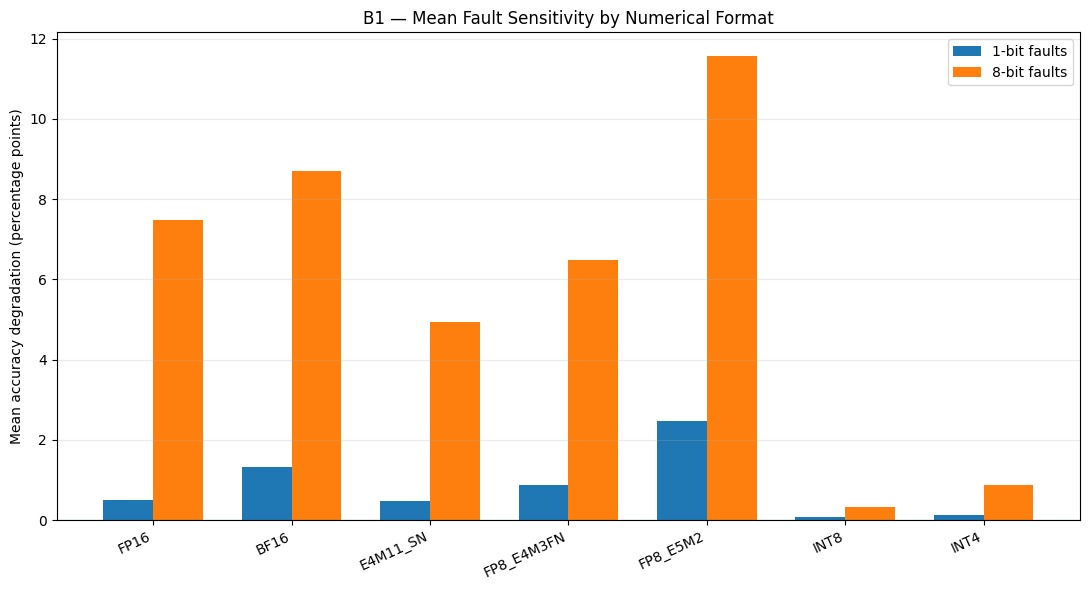

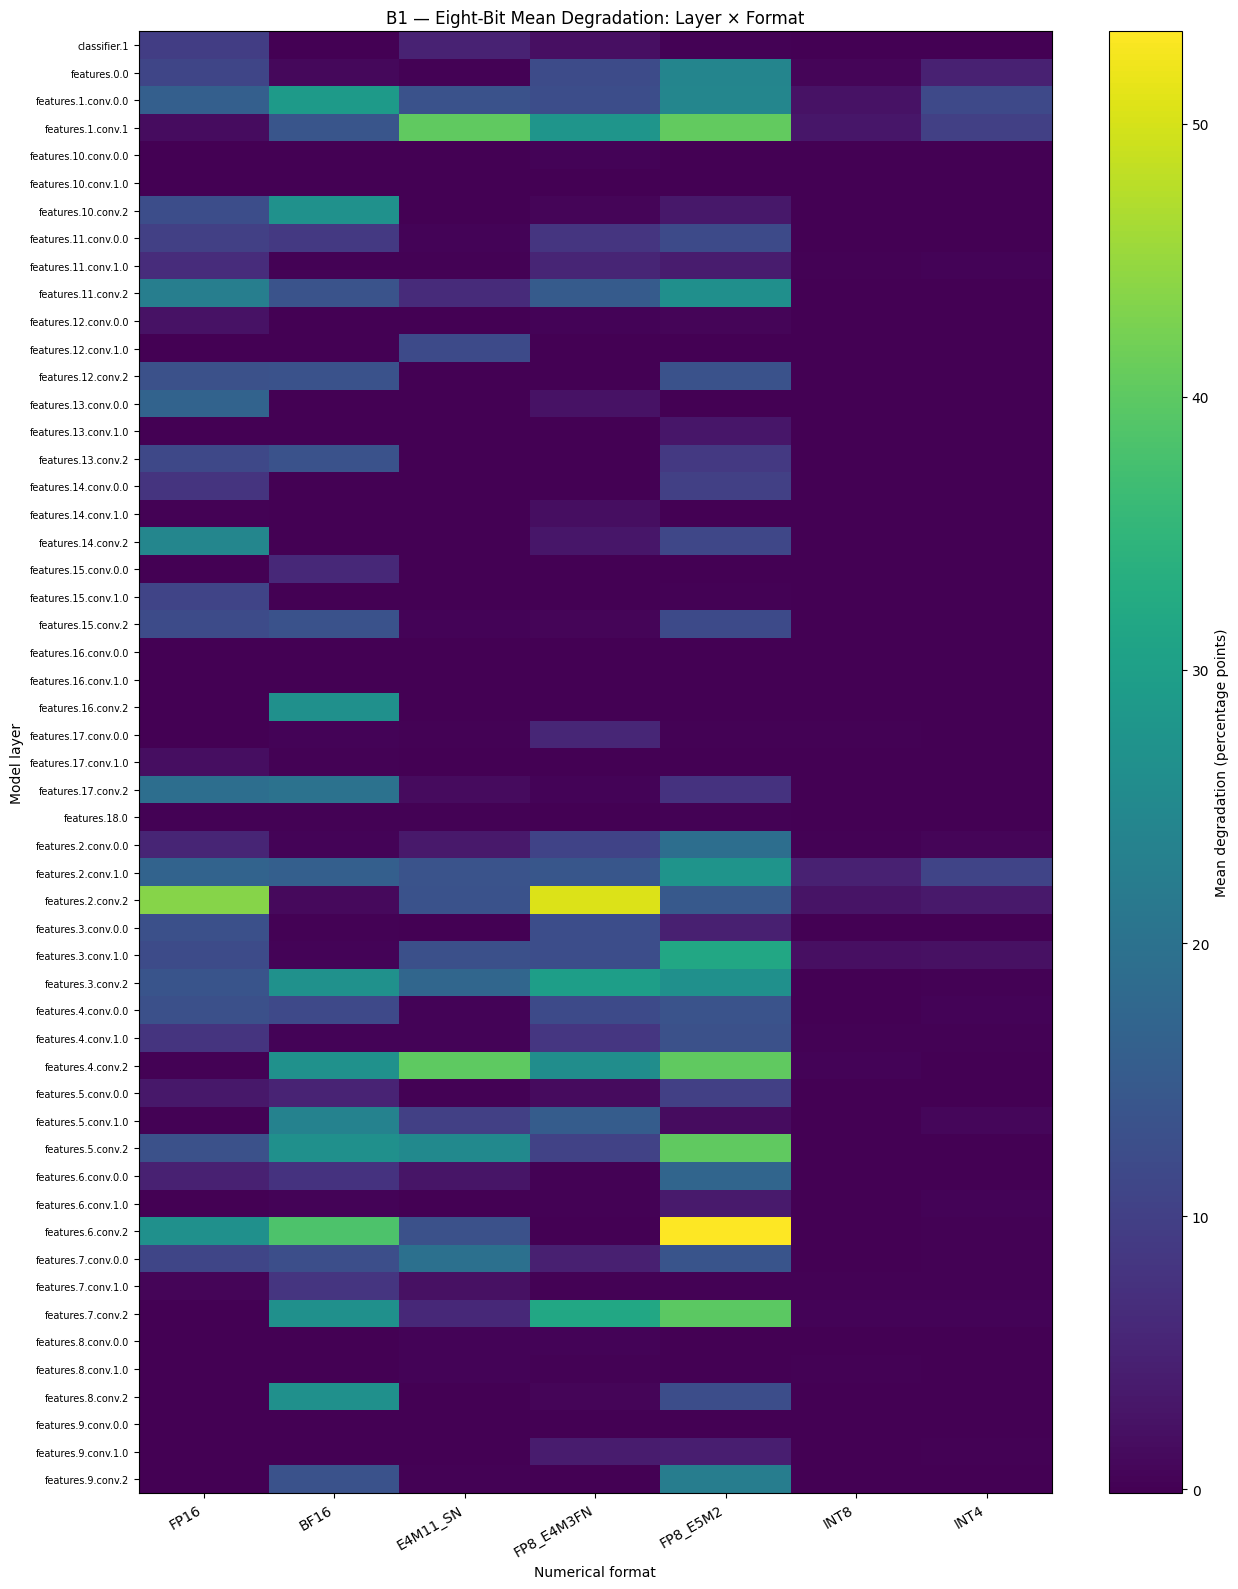

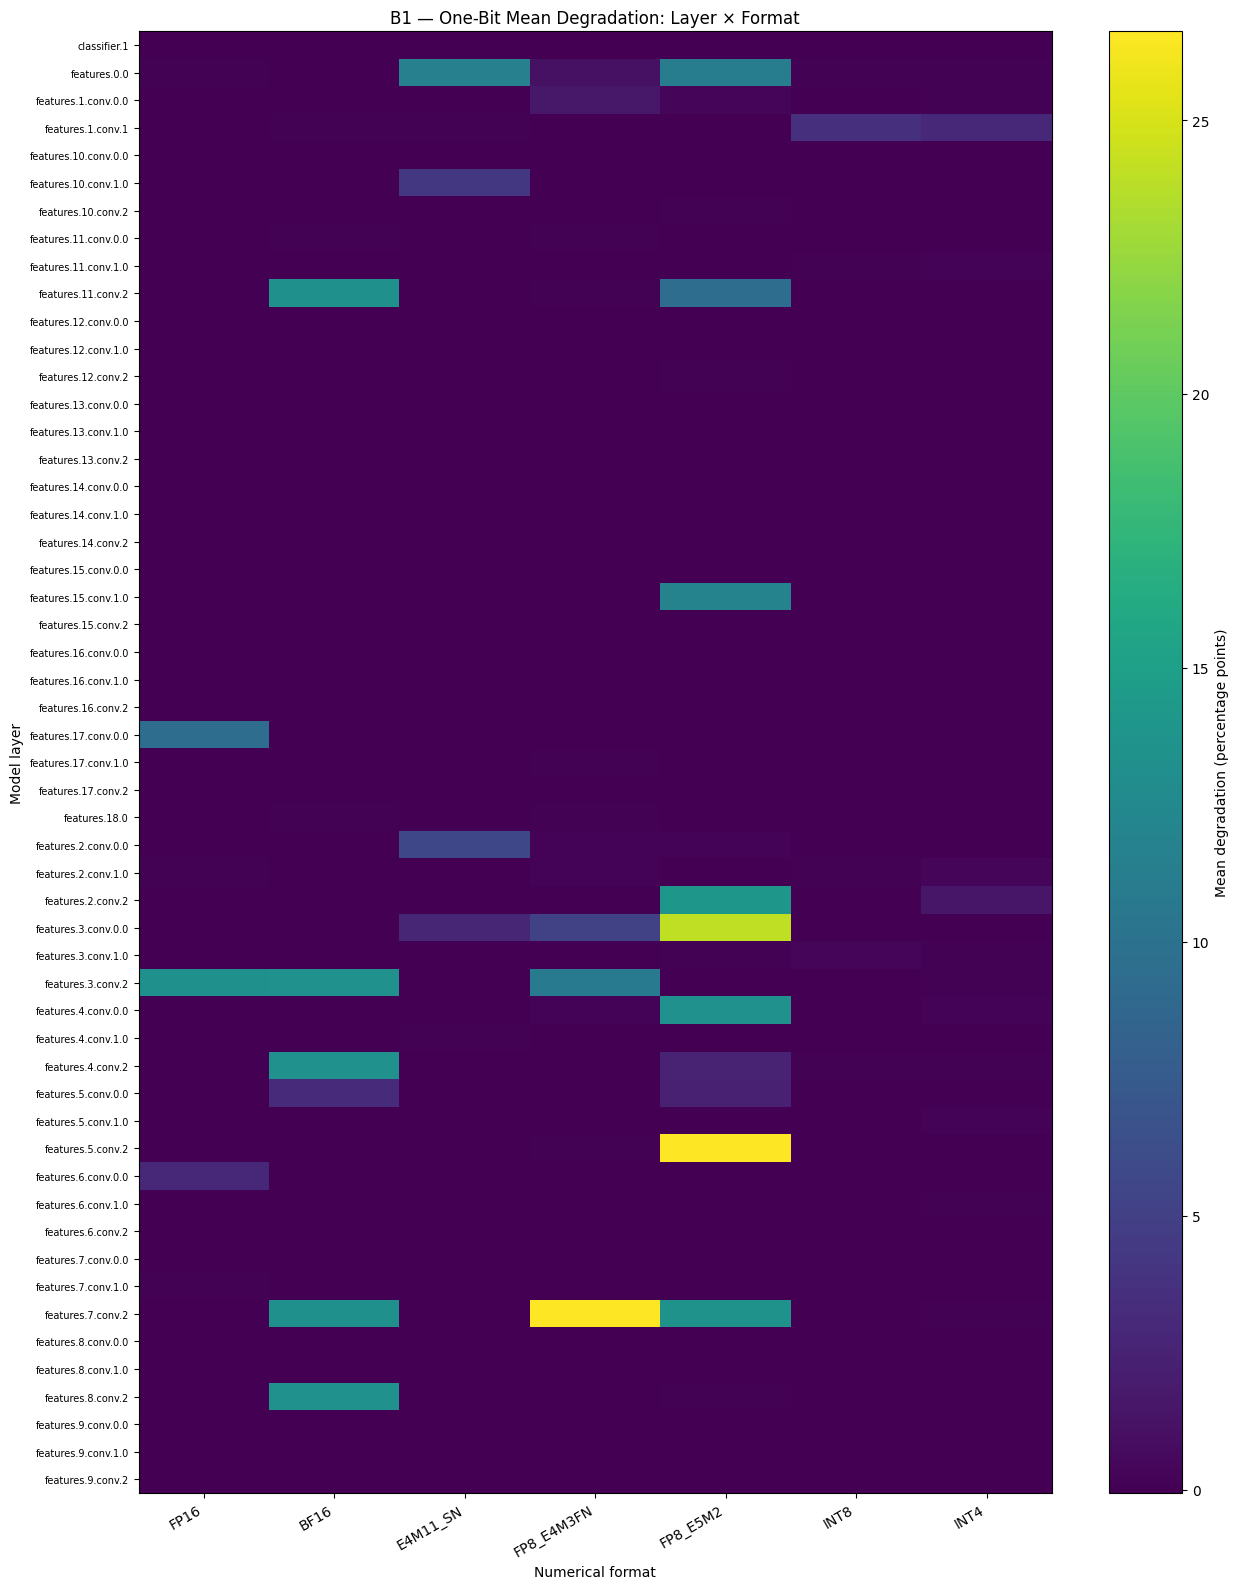


JFAMP STAGE B1 — FINAL SUMMARY
Best average format for one-bit faults: INT8 (0.0776 pp)
Worst average format for one-bit faults: FP8_E5M2 (2.4598 pp)
Best average format for eight-bit faults: INT8 (0.3345 pp)
Worst average format for eight-bit faults: FP8_E5M2 (11.5780 pp)

Saved B1 artifacts:
  B1_clean_accuracy_format_summary.csv (0.8 KB)
  B1_combined_format_comparison.csv (1.2 KB)
  B1_correlations.json (0.2 KB)
  B1_dataset_overview.csv (0.2 KB)
  B1_format_scenario_comparison.csv (0.8 KB)
  B1_format_scenario_statistics.csv (4.8 KB)
  B1_layer_consistency.csv (7.4 KB)
  B1_layer_format_scenario_statistics.csv (103.3 KB)
  B1_one_vs_eight_bit_comparison.csv (26.8 KB)
  B1_severity_analysis.csv (1.2 KB)
  B1_statistical_analysis_report.json (1.6 KB)
  figures/B1_eightbit_layer_format_heatmap.png (282.8 KB)
  figures/B1_mean_degradation_by_format.png (76.7 KB)
  figures/B1_onebit_layer_format_heatmap.png (281.1 KB)

STAGE B1 STATUS: COMPLETE
No new fault simulations were performed.

In [3]:

# =====================================================================
# JFAMP — STAGE B1: STATISTICAL ANALYSIS
#
# Uses existing Stage B outputs only.
# No model inference, quantization or fault injection is performed.
#
# Analyses:
#   1. Separate one-bit and eight-bit fault statistics.
#   2. Format-level expected and observed worst degradation.
#   3. Layer-format-scenario variability.
#   4. Cluster bootstrap confidence intervals (resample layers).
#   5. Catastrophic degradation frequencies.
#   6. One-bit vs eight-bit sensitivity comparison.
#   7. Clean quantization accuracy vs fault sensitivity.
#
# Outputs:
#   /kaggle/working/JFAMP_MobileNetV2/experiments/
#   revised_jfamp_fault_aware/stage_B1_statistical_analysis/
# =====================================================================

import os
import json
import time
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# --------------------------- CONFIGURATION ----------------------------

SEED = 20261115
N_BOOTSTRAP = 10000

FORMATS = [
    "FP16",
    "BF16",
    "E4M11_SN",
    "FP8_E4M3FN",
    "FP8_E5M2",
    "INT8",
    "INT4",
]

FAULT_SCENARIOS = [1, 8]

EXPECTED_LAYERS = 53
EXPECTED_TRIALS = 3710

# Exploratory severity thresholds, in percentage points.
SEVERITY_THRESHOLDS = [1.0, 10.0, 50.0]

OUTPUT_DIR = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B1_statistical_analysis"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

rng = np.random.default_rng(SEED)

# --------------------------- LOAD DATA --------------------------------

# Reuse the dataframes from the input audit cell.
# If they are unavailable, locate the source CSVs again.

if "clean_df" not in globals() or "trials_df" not in globals():

    INPUT_ROOT = Path("/kaggle/input")

    def find_csv(filename):
        matches = list(INPUT_ROOT.rglob(filename))
        if not matches:
            raise FileNotFoundError(
                f"Could not locate {filename} under /kaggle/input"
            )
        return pd.read_csv(matches[0])

    clean_df = find_csv(
        "stageB_clean_layer_format_results.csv"
    )

    trials_df = find_csv(
        "stageB_fault_trial_results.csv"
    )

clean = clean_df.copy()
trials = trials_df.copy()

print("=" * 80)
print("JFAMP STAGE B1 — STATISTICAL ANALYSIS")
print("=" * 80)

print("Clean records:", len(clean))
print("Fault trial records:", len(trials))

# --------------------------- DATA VALIDATION ---------------------------

required_clean = {
    "layer_name",
    "format",
    "clean_accuracy_percent",
    "clean_loss",
    "payload_bytes",
}

required_trials = {
    "layer_name",
    "format",
    "fault_bits",
    "realization",
    "clean_accuracy_percent",
    "fault_accuracy_percent",
    "accuracy_degradation_pp",
    "loss_change",
    "changed_predictions",
    "correct_to_wrong",
    "wrong_to_correct",
    "payload_bits",
    "status",
}

missing_clean = required_clean - set(clean.columns)
missing_trials = required_trials - set(trials.columns)

if missing_clean:
    raise RuntimeError(
        f"Missing clean result columns: {missing_clean}"
    )

if missing_trials:
    raise RuntimeError(
        f"Missing fault result columns: {missing_trials}"
    )

if len(clean) != 371:
    raise RuntimeError(
        f"Expected 371 clean combinations, found {len(clean)}"
    )

if len(trials) != EXPECTED_TRIALS:
    raise RuntimeError(
        f"Expected {EXPECTED_TRIALS} fault trials, found {len(trials)}"
    )

if clean["layer_name"].nunique() != EXPECTED_LAYERS:
    raise RuntimeError("Unexpected number of quantizable layers.")

if set(clean["format"].unique()) != set(FORMATS):
    raise RuntimeError("Unexpected clean-result formats.")

if set(trials["fault_bits"].unique()) != set(FAULT_SCENARIOS):
    raise RuntimeError("Unexpected fault scenarios.")

if not (trials["status"] == "OK").all():
    raise RuntimeError(
        "Some trials are not successful. Resolve those before analysis."
    )

if trials.duplicated(
    ["layer_name", "format", "fault_bits", "realization"]
).any():
    raise RuntimeError("Duplicate fault trial keys detected.")

# Numerical conversion.
numeric_columns = [
    "fault_bits",
    "realization",
    "clean_accuracy_percent",
    "fault_accuracy_percent",
    "accuracy_degradation_pp",
    "loss_change",
    "changed_predictions",
    "correct_to_wrong",
    "wrong_to_correct",
    "payload_bits",
]

for col in numeric_columns:
    trials[col] = pd.to_numeric(
        trials[col],
        errors="raise"
    )

# Verify degradation sign convention.
recomputed_degradation = (
    trials["clean_accuracy_percent"]
    - trials["fault_accuracy_percent"]
)

max_degradation_error = float(
    np.max(
        np.abs(
            recomputed_degradation
            - trials["accuracy_degradation_pp"]
        )
    )
)

if max_degradation_error > 1e-6:
    raise RuntimeError(
        "Accuracy degradation values do not match "
        "clean accuracy minus faulted accuracy."
    )

# Add explicitly positive-is-worse metric.
trials["degradation_pp"] = recomputed_degradation

# Verify exact scenario balance.
scenario_counts = trials["fault_bits"].value_counts().to_dict()

print("\nScenario counts:", scenario_counts)
print("Maximum degradation consistency error:", max_degradation_error)

# --------------------------- 1. BASIC DATASET -------------------------

print("\n" + "=" * 80)
print("1. DATASET CHARACTERISTICS")
print("=" * 80)

dataset_overview = pd.DataFrame([
    {
        "metric": "Quantizable layers",
        "value": clean["layer_name"].nunique()
    },
    {
        "metric": "Numerical formats",
        "value": clean["format"].nunique()
    },
    {
        "metric": "Clean combinations",
        "value": len(clean)
    },
    {
        "metric": "Total fault trials",
        "value": len(trials)
    },
    {
        "metric": "One-bit trials",
        "value": int((trials["fault_bits"] == 1).sum())
    },
    {
        "metric": "Eight-bit trials",
        "value": int((trials["fault_bits"] == 8).sum())
    },
    {
        "metric": "Realizations per combination/scenario",
        "value": int(trials.groupby(
            ["layer_name", "format", "fault_bits"]
        ).size().min())
    },
    {
        "metric": "Unique layers",
        "value": trials["layer_name"].nunique()
    },
])

display(dataset_overview)

dataset_overview.to_csv(
    OUTPUT_DIR / "B1_dataset_overview.csv",
    index=False
)

# --------------------------- 2. BOOTSTRAP CI --------------------------

def cluster_bootstrap_ci(
    dataframe,
    value_column,
    n_bootstrap=N_BOOTSTRAP
):
    """
    Cluster bootstrap:

    First calculate the mean degradation for each layer.
    Then resample layers with replacement.

    This avoids treating the five realizations from one layer
    as five independent layer-level observations.
    """

    layer_means = (
        dataframe.groupby("layer_name")[value_column]
        .mean()
        .dropna()
        .to_numpy()
    )

    if len(layer_means) == 0:
        return np.nan, np.nan

    n = len(layer_means)

    bootstrap_means = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        sample = rng.choice(
            layer_means,
            size=n,
            replace=True
        )
        bootstrap_means[i] = np.mean(sample)

    lower, upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    return float(lower), float(upper)


# --------------------------- 3. FORMAT × SCENARIO ---------------------

format_scenario_rows = []

for fmt in FORMATS:

    for fault_bits in FAULT_SCENARIOS:

        group = trials[
            (trials["format"] == fmt)
            & (trials["fault_bits"] == fault_bits)
        ].copy()

        d = group["degradation_pp"].to_numpy()

        ci_low, ci_high = cluster_bootstrap_ci(
            group,
            "degradation_pp"
        )

        row = {
            "format": fmt,
            "fault_bits": fault_bits,
            "trial_count": len(group),
            "layer_count": group["layer_name"].nunique(),
            "mean_degradation_pp": float(np.mean(d)),
            "median_degradation_pp": float(np.median(d)),
            "std_degradation_pp": float(np.std(d, ddof=1)),
            "p90_degradation_pp": float(np.percentile(d, 90)),
            "p95_degradation_pp": float(np.percentile(d, 95)),
            "worst_observed_degradation_pp": float(np.max(d)),
            "best_observed_degradation_pp": float(np.min(d)),
            "cluster_bootstrap_ci95_low_pp": ci_low,
            "cluster_bootstrap_ci95_high_pp": ci_high,
            "mean_loss_change": float(group["loss_change"].mean()),
            "mean_changed_predictions": float(
                group["changed_predictions"].mean()
            ),
            "mean_correct_to_wrong": float(
                group["correct_to_wrong"].mean()
            ),
            "mean_wrong_to_correct": float(
                group["wrong_to_correct"].mean()
            ),
            "mean_payload_bit_flip_rate": float(
                (
                    group["fault_bits"]
                    / group["payload_bits"]
                ).mean()
            ),
        }

        for threshold in SEVERITY_THRESHOLDS:

            row[
                f"fraction_trials_over_{threshold:g}pp"
            ] = float(
                np.mean(d > threshold)
            )

        format_scenario_rows.append(row)

format_scenario_df = pd.DataFrame(
    format_scenario_rows
)

format_scenario_df.to_csv(
    OUTPUT_DIR / "B1_format_scenario_statistics.csv",
    index=False
)

print("\n" + "=" * 80)
print("2. FORMAT-LEVEL STATISTICS — SEPARATE FAULT SCENARIOS")
print("=" * 80)

for fault_bits in FAULT_SCENARIOS:

    print(f"\n{fault_bits}-BIT FAULTS")

    table = format_scenario_df[
        format_scenario_df["fault_bits"] == fault_bits
    ].sort_values(
        "mean_degradation_pp",
        ascending=True
    )

    display(
        table[
            [
                "format",
                "mean_degradation_pp",
                "median_degradation_pp",
                "std_degradation_pp",
                "p95_degradation_pp",
                "worst_observed_degradation_pp",
                "cluster_bootstrap_ci95_low_pp",
                "cluster_bootstrap_ci95_high_pp",
                "fraction_trials_over_1pp",
                "fraction_trials_over_10pp",
                "fraction_trials_over_50pp",
            ]
        ].reset_index(drop=True)
    )

# --------------------------- 4. LAYER-FORMAT STATISTICS ---------------

layer_format_rows = []

for (layer_name, fmt, fault_bits), group in trials.groupby(
    ["layer_name", "format", "fault_bits"],
    sort=False
):

    d = group["degradation_pp"].to_numpy()

    layer_format_rows.append({

        "layer_name": layer_name,

        "format": fmt,

        "fault_bits": int(fault_bits),

        "n_realizations": int(len(d)),

        "mean_degradation_pp": float(np.mean(d)),

        "median_degradation_pp": float(np.median(d)),

        "std_degradation_pp": float(
            np.std(d, ddof=1)
        ) if len(d) > 1 else 0.0,

        "min_degradation_pp": float(np.min(d)),

        "max_degradation_pp": float(np.max(d)),

        "p95_degradation_pp": float(
            np.percentile(d, 95)
        ),

        "mean_changed_predictions": float(
            group["changed_predictions"].mean()
        ),

        "mean_correct_to_wrong": float(
            group["correct_to_wrong"].mean()
        ),

        "mean_wrong_to_correct": float(
            group["wrong_to_correct"].mean()
        ),

        "mean_loss_change": float(
            group["loss_change"].mean()
        ),
    })

layer_format_df = pd.DataFrame(layer_format_rows)

layer_format_df.to_csv(
    OUTPUT_DIR / "B1_layer_format_scenario_statistics.csv",
    index=False
)

print("\n" + "=" * 80)
print("3. MOST VULNERABLE LAYER-FORMAT COMBINATIONS")
print("=" * 80)

for fault_bits in FAULT_SCENARIOS:

    print(f"\n{fault_bits}-BIT FAULTS")

    top = (
        layer_format_df[
            layer_format_df["fault_bits"] == fault_bits
        ]
        .sort_values(
            "mean_degradation_pp",
            ascending=False
        )
        .head(15)
    )

    display(top.reset_index(drop=True))

# --------------------------- 5. SEVERITY ANALYSIS ---------------------

severity_rows = []

for fmt in FORMATS:

    for fault_bits in FAULT_SCENARIOS:

        group = trials[
            (trials["format"] == fmt)
            & (trials["fault_bits"] == fault_bits)
        ]

        d = group["degradation_pp"].to_numpy()

        row = {
            "format": fmt,
            "fault_bits": fault_bits,
            "total_trials": len(d),
        }

        for threshold in SEVERITY_THRESHOLDS:

            count = int(np.count_nonzero(d > threshold))

            row[f"count_over_{threshold:g}pp"] = count

            row[f"rate_over_{threshold:g}pp"] = (
                count / len(d)
            )

        severity_rows.append(row)

severity_df = pd.DataFrame(severity_rows)

severity_df.to_csv(
    OUTPUT_DIR / "B1_severity_analysis.csv",
    index=False
)

print("\n" + "=" * 80)
print("4. CATASTROPHIC DEGRADATION FREQUENCIES")
print("=" * 80)

display(severity_df)

# --------------------------- 6. ONE VS EIGHT BIT ----------------------

scenario_means = (
    layer_format_df.pivot_table(
        index=["layer_name", "format"],
        columns="fault_bits",
        values="mean_degradation_pp"
    )
    .reset_index()
)

scenario_means.columns.name = None

scenario_means = scenario_means.rename(
    columns={
        1: "mean_degradation_1bit_pp",
        8: "mean_degradation_8bit_pp",
    }
)

scenario_means["eight_minus_one_bit_pp"] = (
    scenario_means["mean_degradation_8bit_pp"]
    - scenario_means["mean_degradation_1bit_pp"]
)

scenario_means.to_csv(
    OUTPUT_DIR / "B1_one_vs_eight_bit_comparison.csv",
    index=False
)

format_comparison_rows = []

for fmt in FORMATS:

    group = scenario_means[
        scenario_means["format"] == fmt
    ]

    delta = group["eight_minus_one_bit_pp"].to_numpy()

    format_comparison_rows.append({

        "format": fmt,

        "mean_1bit_degradation_pp": float(
            group["mean_degradation_1bit_pp"].mean()
        ),

        "mean_8bit_degradation_pp": float(
            group["mean_degradation_8bit_pp"].mean()
        ),

        "mean_increase_8bit_vs_1bit_pp": float(
            np.mean(delta)
        ),

        "median_increase_8bit_vs_1bit_pp": float(
            np.median(delta)
        ),

        "layers_with_increased_degradation": int(
            np.count_nonzero(delta > 0)
        ),

        "layers_with_decreased_degradation": int(
            np.count_nonzero(delta < 0)
        ),

        "layers_with_equal_degradation": int(
            np.count_nonzero(delta == 0)
        ),
    })

comparison_df = pd.DataFrame(format_comparison_rows)

comparison_df.to_csv(
    OUTPUT_DIR / "B1_format_scenario_comparison.csv",
    index=False
)

print("\n" + "=" * 80)
print("5. ONE-BIT VS EIGHT-BIT COMPARISON")
print("=" * 80)

display(
    comparison_df.sort_values(
        "mean_increase_8bit_vs_1bit_pp",
        ascending=False
    ).reset_index(drop=True)
)

# --------------------------- 7. CLEAN ACCURACY ------------------------

clean_format_rows = []

for fmt in FORMATS:

    group = clean[
        clean["format"] == fmt
    ]

    clean_accuracy = group[
        "clean_accuracy_percent"
    ].to_numpy()

    fp32_accuracy = 68.06

    clean_format_rows.append({

        "format": fmt,

        "mean_clean_accuracy_percent": float(
            np.mean(clean_accuracy)
        ),

        "std_clean_accuracy_pp": float(
            np.std(clean_accuracy, ddof=1)
        ),

        "minimum_layer_clean_accuracy_percent": float(
            np.min(clean_accuracy)
        ),

        "maximum_layer_clean_accuracy_percent": float(
            np.max(clean_accuracy)
        ),

        "mean_accuracy_drop_vs_fp32_pp": float(
            np.mean(fp32_accuracy - clean_accuracy)
        ),

        "mean_payload_bytes": float(
            group["payload_bytes"].mean()
        ),

        "total_layer_payload_bytes": int(
            group["payload_bytes"].sum()
        ),
    })

clean_format_df = pd.DataFrame(clean_format_rows)

clean_format_df.to_csv(
    OUTPUT_DIR / "B1_clean_accuracy_format_summary.csv",
    index=False
)

print("\n" + "=" * 80)
print("6. CLEAN QUANTIZATION ACCURACY AND STORAGE")
print("=" * 80)

display(
    clean_format_df.sort_values(
        "mean_accuracy_drop_vs_fp32_pp",
        ascending=True
    ).reset_index(drop=True)
)

# --------------------------- 8. COMBINED FORMAT VIEW ------------------

combined_rows = []

for fmt in FORMATS:

    clean_group = clean[
        clean["format"] == fmt
    ]

    one = format_scenario_df[
        (format_scenario_df["format"] == fmt)
        & (format_scenario_df["fault_bits"] == 1)
    ].iloc[0]

    eight = format_scenario_df[
        (format_scenario_df["format"] == fmt)
        & (format_scenario_df["fault_bits"] == 8)
    ].iloc[0]

    combined_rows.append({

        "format": fmt,

        "mean_clean_accuracy_percent": float(
            clean_group["clean_accuracy_percent"].mean()
        ),

        "mean_clean_accuracy_drop_pp": float(
            (
                68.06
                - clean_group["clean_accuracy_percent"]
            ).mean()
        ),

        "mean_1bit_degradation_pp":
            float(one["mean_degradation_pp"]),

        "mean_8bit_degradation_pp":
            float(eight["mean_degradation_pp"]),

        "worst_1bit_observed_pp":
            float(one["worst_observed_degradation_pp"]),

        "worst_8bit_observed_pp":
            float(eight["worst_observed_degradation_pp"]),

        "p95_1bit_pp":
            float(one["p95_degradation_pp"]),

        "p95_8bit_pp":
            float(eight["p95_degradation_pp"]),

        "mean_payload_bytes":
            float(clean_group["payload_bytes"].mean()),
    })

combined_df = pd.DataFrame(combined_rows)

combined_df.to_csv(
    OUTPUT_DIR / "B1_combined_format_comparison.csv",
    index=False
)

print("\n" + "=" * 80)
print("7. COMBINED CLEAN-ACCURACY AND ROBUSTNESS VIEW")
print("=" * 80)

display(
    combined_df.sort_values(
        "mean_8bit_degradation_pp",
        ascending=True
    ).reset_index(drop=True)
)

# --------------------------- 9. LAYER CONSISTENCY ---------------------

layer_consistency_rows = []

for layer_name, group in scenario_means.groupby(
    "layer_name",
    sort=False
):

    d1 = group["mean_degradation_1bit_pp"].to_numpy()
    d8 = group["mean_degradation_8bit_pp"].to_numpy()

    layer_consistency_rows.append({

        "layer_name": layer_name,

        "mean_1bit_degradation_across_formats_pp": float(
            np.mean(d1)
        ),

        "mean_8bit_degradation_across_formats_pp": float(
            np.mean(d8)
        ),

        "worst_1bit_format_degradation_pp": float(
            np.max(d1)
        ),

        "worst_8bit_format_degradation_pp": float(
            np.max(d8)
        ),

        "best_1bit_format_degradation_pp": float(
            np.min(d1)
        ),

        "best_8bit_format_degradation_pp": float(
            np.min(d8)
        ),

        "format_sensitivity_range_8bit_pp": float(
            np.max(d8) - np.min(d8)
        ),
    })

layer_consistency_df = pd.DataFrame(
    layer_consistency_rows
)

layer_consistency_df.to_csv(
    OUTPUT_DIR / "B1_layer_consistency.csv",
    index=False
)

print("\n" + "=" * 80)
print("8. LAYER-DEPENDENT FORMAT SENSITIVITY")
print("=" * 80)

print("\nLayers with highest average eight-bit sensitivity:")

display(
    layer_consistency_df.sort_values(
        "mean_8bit_degradation_across_formats_pp",
        ascending=False
    ).head(15).reset_index(drop=True)
)

print("\nLayers with largest format-dependent sensitivity range:")

display(
    layer_consistency_df.sort_values(
        "format_sensitivity_range_8bit_pp",
        ascending=False
    ).head(15).reset_index(drop=True)
)

# --------------------------- 10. CORRELATION --------------------------

correlation_data = scenario_means.merge(
    clean[
        ["layer_name", "format", "clean_accuracy_percent"]
    ],
    on=["layer_name", "format"],
    how="left"
)

correlations = {
    "clean_accuracy_vs_1bit_degradation": float(
        correlation_data[
            [
                "clean_accuracy_percent",
                "mean_degradation_1bit_pp"
            ]
        ].corr().iloc[0, 1]
    ),

    "clean_accuracy_vs_8bit_degradation": float(
        correlation_data[
            [
                "clean_accuracy_percent",
                "mean_degradation_8bit_pp"
            ]
        ].corr().iloc[0, 1]
    ),

    "onebit_vs_eightbit_degradation": float(
        scenario_means[
            [
                "mean_degradation_1bit_pp",
                "mean_degradation_8bit_pp"
            ]
        ].corr().iloc[0, 1]
    ),
}

with open(
    OUTPUT_DIR / "B1_correlations.json",
    "w"
) as f:
    json.dump(correlations, f, indent=2)

print("\n" + "=" * 80)
print("9. CORRELATION ANALYSIS")
print("=" * 80)

for key, value in correlations.items():
    print(f"{key}: {value:.5f}")

# --------------------------- 11. VISUALIZATIONS -----------------------

# Plot 1: Mean degradation by format and fault scenario.

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(FORMATS))
width = 0.36

means_1 = [
    float(
        format_scenario_df[
            (format_scenario_df["format"] == fmt)
            & (format_scenario_df["fault_bits"] == 1)
        ]["mean_degradation_pp"].iloc[0]
    )
    for fmt in FORMATS
]

means_8 = [
    float(
        format_scenario_df[
            (format_scenario_df["format"] == fmt)
            & (format_scenario_df["fault_bits"] == 8)
        ]["mean_degradation_pp"].iloc[0]
    )
    for fmt in FORMATS
]

ax.bar(
    x - width / 2,
    means_1,
    width,
    label="1-bit faults"
)

ax.bar(
    x + width / 2,
    means_8,
    width,
    label="8-bit faults"
)

ax.set_xticks(x)
ax.set_xticklabels(FORMATS, rotation=25, ha="right")
ax.set_ylabel("Mean accuracy degradation (percentage points)")
ax.set_title("B1 — Mean Fault Sensitivity by Numerical Format")
ax.axhline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "B1_mean_degradation_by_format.png",
    dpi=180
)

plt.show()
plt.close(fig)

# Plot 2: Layer-format heatmap for eight-bit faults.

heatmap_df = scenario_means.pivot(
    index="layer_name",
    columns="format",
    values="mean_degradation_8bit_pp"
)

heatmap_df = heatmap_df.reindex(columns=FORMATS)

fig, ax = plt.subplots(figsize=(13, 16))

im = ax.imshow(
    heatmap_df.to_numpy(),
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(FORMATS)))
ax.set_xticklabels(FORMATS, rotation=30, ha="right")

ax.set_yticks(np.arange(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index, fontsize=7)

ax.set_title(
    "B1 — Eight-Bit Mean Degradation: Layer × Format"
)

ax.set_xlabel("Numerical format")
ax.set_ylabel("Model layer")

fig.colorbar(
    im,
    ax=ax,
    label="Mean degradation (percentage points)"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "B1_eightbit_layer_format_heatmap.png",
    dpi=180
)

plt.show()
plt.close(fig)

# Plot 3: Layer-format heatmap for one-bit faults.

heatmap_1 = scenario_means.pivot(
    index="layer_name",
    columns="format",
    values="mean_degradation_1bit_pp"
).reindex(columns=FORMATS)

fig, ax = plt.subplots(figsize=(13, 16))

im = ax.imshow(
    heatmap_1.to_numpy(),
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(FORMATS)))
ax.set_xticklabels(FORMATS, rotation=30, ha="right")

ax.set_yticks(np.arange(len(heatmap_1.index)))
ax.set_yticklabels(heatmap_1.index, fontsize=7)

ax.set_title(
    "B1 — One-Bit Mean Degradation: Layer × Format"
)

ax.set_xlabel("Numerical format")
ax.set_ylabel("Model layer")

fig.colorbar(
    im,
    ax=ax,
    label="Mean degradation (percentage points)"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "B1_onebit_layer_format_heatmap.png",
    dpi=180
)

plt.show()
plt.close(fig)

# --------------------------- 12. RESEARCH REPORT ---------------------

best_8bit_format = (
    format_scenario_df[
        format_scenario_df["fault_bits"] == 8
    ]
    .sort_values("mean_degradation_pp")
    .iloc[0]
)

worst_8bit_format = (
    format_scenario_df[
        format_scenario_df["fault_bits"] == 8
    ]
    .sort_values("mean_degradation_pp", ascending=False)
    .iloc[0]
)

best_1bit_format = (
    format_scenario_df[
        format_scenario_df["fault_bits"] == 1
    ]
    .sort_values("mean_degradation_pp")
    .iloc[0]
)

worst_1bit_format = (
    format_scenario_df[
        format_scenario_df["fault_bits"] == 1
    ]
    .sort_values("mean_degradation_pp", ascending=False)
    .iloc[0]
)

report = {

    "stage": "B1 — Statistical analysis",

    "created_utc": datetime.now(timezone.utc).isoformat(),

    "source_trial_count": int(len(trials)),

    "source_clean_combinations": int(len(clean)),

    "bootstrap": {
        "method": "Layer-cluster bootstrap",
        "resampling_unit": "layer",
        "bootstrap_iterations": N_BOOTSTRAP,
        "confidence_level": 0.95,
        "random_seed": SEED,
    },

    "best_mean_1bit_format": {
        "format": str(best_1bit_format["format"]),
        "mean_degradation_pp": float(
            best_1bit_format["mean_degradation_pp"]
        ),
    },

    "worst_mean_1bit_format": {
        "format": str(worst_1bit_format["format"]),
        "mean_degradation_pp": float(
            worst_1bit_format["mean_degradation_pp"]
        ),
    },

    "best_mean_8bit_format": {
        "format": str(best_8bit_format["format"]),
        "mean_degradation_pp": float(
            best_8bit_format["mean_degradation_pp"]
        ),
    },

    "worst_mean_8bit_format": {
        "format": str(worst_8bit_format["format"]),
        "mean_degradation_pp": float(
            worst_8bit_format["mean_degradation_pp"]
        ),
    },

    "correlations": correlations,

    "interpretation_caveats": [
        "Five realizations per layer-format-scenario are exploratory.",
        "Observed maximum is not a guaranteed worst-case bound.",
        "P95 with five observations per individual layer-format-scenario "
        "is highly resolution-limited.",
        "Format-level confidence intervals use layer-cluster bootstrap.",
        "One-bit and eight-bit experiments use different absolute fault counts.",
        "The one-layer perturbation results are screening measurements, "
        "not additive full-model allocation guarantees.",
    ],

    "output_directory": str(OUTPUT_DIR),
}

with open(
    OUTPUT_DIR / "B1_statistical_analysis_report.json",
    "w"
) as f:
    json.dump(report, f, indent=2)

# --------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 80)
print("JFAMP STAGE B1 — FINAL SUMMARY")
print("=" * 80)

print(
    "Best average format for one-bit faults:",
    best_1bit_format["format"],
    f"({best_1bit_format['mean_degradation_pp']:.4f} pp)"
)

print(
    "Worst average format for one-bit faults:",
    worst_1bit_format["format"],
    f"({worst_1bit_format['mean_degradation_pp']:.4f} pp)"
)

print(
    "Best average format for eight-bit faults:",
    best_8bit_format["format"],
    f"({best_8bit_format['mean_degradation_pp']:.4f} pp)"
)

print(
    "Worst average format for eight-bit faults:",
    worst_8bit_format["format"],
    f"({worst_8bit_format['mean_degradation_pp']:.4f} pp)"
)

print("\nSaved B1 artifacts:")

for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(
            f"  {path.relative_to(OUTPUT_DIR)} "
            f"({path.stat().st_size / 1024:.1f} KB)"
        )

print("\nSTAGE B1 STATUS: COMPLETE")
print("No new fault simulations were performed.")
print("Original Stage B artifacts were not modified.")
print("=" * 80)

# Keep principal outputs available for subsequent notebook cells.
b1_format_scenario_df = format_scenario_df
b1_layer_format_df = layer_format_df
b1_severity_df = severity_df
b1_comparison_df = comparison_df
b1_clean_format_df = clean_format_df
b1_combined_df = combined_df
b1_layer_consistency_df = layer_consistency_df
b1_heatmap_1bit = heatmap_1
b1_heatmap_8bit = heatmap_df
b1_report = report


In [7]:

# ================================================================
# JFAMP — STAGE B2
# Layer-wise sensitivity matrices and preliminary format shortlisting
#
# Input: Stage B raw CSVs + Stage B manifest/baseline
# Output: 53 x 7 matrices, rankings, heatmaps, report JSON
# No inference, training, or fault injection.
# ================================================================

import os, json, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------- CONFIG -------------------------------

ROOT = Path("/kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware")

STAGE_B = ROOT / "stage_B_layerwise_fault_sensitivity"
OUT = Path("/kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices")
OUT.mkdir(parents=True, exist_ok=True)

FORMATS = [
    "FP16", "BF16", "E4M11_SN",
    "FP8_E4M3FN", "FP8_E5M2", "INT8", "INT4"
]

SCENARIOS = [1, 8]
EXPECTED_LAYERS = 53
EXPECTED_CLEAN_ROWS = EXPECTED_LAYERS * len(FORMATS)
EXPECTED_TRIAL_ROWS = EXPECTED_LAYERS * len(FORMATS) * 2 * 5

print("=" * 80)
print("JFAMP STAGE B2 — SENSITIVITY MATRICES")
print("=" * 80)
print("Input:", STAGE_B)
print("Output:", OUT)

# ------------------------- LOAD ---------------------------------

required_files = [
    "stageB_clean_layer_format_results.csv",
    "stageB_fault_trial_results.csv",
    "stageB_fault_sensitivity_summary.csv",
    "stageB_experiment_manifest.json",
    "stageB_fp32_baseline.json"
]

missing = [f for f in required_files if not (STAGE_B / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing Stage B files: {missing}")

clean_df = pd.read_csv(STAGE_B / required_files[0])
trials_df = pd.read_csv(STAGE_B / required_files[1])
summary_df = pd.read_csv(STAGE_B / required_files[2])

with open(STAGE_B / "stageB_experiment_manifest.json") as f:
    manifest = json.load(f)

with open(STAGE_B / "stageB_fp32_baseline.json") as f:
    baseline = json.load(f)

print("\nLoaded:")
print("  Clean rows:", len(clean_df))
print("  Fault trials:", len(trials_df))
print("  Summary rows:", len(summary_df))

# ------------------------- COLUMN DISCOVERY ----------------------

def find_col(df, candidates, description):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(
        f"Could not find {description}. "
        f"Available columns: {list(df.columns)}"
    )

clean_layer_col = find_col(
    clean_df, ["layer_name", "layer", "module_name"], "clean layer column"
)
clean_format_col = find_col(
    clean_df, ["format", "dtype", "data_format"], "clean format column"
)
clean_acc_col = find_col(
    clean_df,
    [
        "clean_accuracy_percent",
        "clean_accuracy_pct",
        "accuracy_pct",
        "accuracy",
        "clean_acc"
    ],
    "clean accuracy column"
)
clean_bytes_col = find_col(
    clean_df,
    ["payload_bytes", "storage_bytes", "encoded_bytes", "nbytes"],
    "payload bytes column"
)

trial_layer_col = find_col(
    trials_df, ["layer_name", "layer", "module_name"], "trial layer column"
)
trial_format_col = find_col(
    trials_df, ["format", "dtype", "data_format"], "trial format column"
)
trial_bits_col = find_col(
    trials_df,
    ["fault_bits", "fault_bit_count", "bits_flipped", "num_fault_bits",
     "fault_size_bits"],
    "fault bit-count column"
)
trial_deg_col = find_col(
    trials_df,
    ["accuracy_degradation_pp", "accuracy_drop_pp",
     "degradation_pp", "accuracy_degradation"],
    "accuracy degradation column"
)

# Optional metrics, included when present.
optional_trial_cols = {
    "changed_predictions": [
        "changed_predictions", "num_changed_predictions",
        "prediction_changes"
    ],
    "correct_to_wrong": [
        "correct_to_wrong", "correct_to_incorrect",
        "num_correct_to_wrong"
    ],
    "wrong_to_correct": [
        "wrong_to_correct", "incorrect_to_correct",
        "num_wrong_to_correct"
    ],
    "realization": [
        "realization", "trial", "trial_id", "realization_id"
    ],
}

optional_found = {}
for metric, candidates in optional_trial_cols.items():
    optional_found[metric] = next(
        (c for c in candidates if c in trials_df.columns), None
    )

# ------------------------- NORMALIZE -----------------------------

clean_df[clean_format_col] = clean_df[clean_format_col].astype(str)
trials_df[trial_format_col] = trials_df[trial_format_col].astype(str)

clean_df[clean_acc_col] = pd.to_numeric(
    clean_df[clean_acc_col], errors="coerce"
)
clean_df[clean_bytes_col] = pd.to_numeric(
    clean_df[clean_bytes_col], errors="coerce"
)
trials_df[trial_bits_col] = pd.to_numeric(
    trials_df[trial_bits_col], errors="coerce"
)
trials_df[trial_deg_col] = pd.to_numeric(
    trials_df[trial_deg_col], errors="coerce"
)

if clean_df[[clean_layer_col, clean_format_col, clean_acc_col,
             clean_bytes_col]].isna().any().any():
    raise ValueError("Missing values found in required clean-result fields.")

if trials_df[[trial_layer_col, trial_format_col, trial_bits_col,
              trial_deg_col]].isna().any().any():
    raise ValueError("Missing values found in required fault-trial fields.")

layers = list(dict.fromkeys(clean_df[clean_layer_col].astype(str).tolist()))

# Prefer manifest order when it is explicitly available.
manifest_layer_order = manifest.get("layer_order")
if isinstance(manifest_layer_order, list):
    manifest_layer_order = [str(x) for x in manifest_layer_order]
    if set(manifest_layer_order) == set(layers):
        layers = manifest_layer_order

if len(layers) != EXPECTED_LAYERS:
    raise ValueError(f"Expected 53 layers; found {len(layers)}.")

if set(clean_df[clean_format_col]) != set(FORMATS):
    raise ValueError(
        f"Unexpected clean formats: {sorted(clean_df[clean_format_col].unique())}"
    )

if set(trials_df[trial_format_col]) != set(FORMATS):
    raise ValueError(
        f"Unexpected trial formats: {sorted(trials_df[trial_format_col].unique())}"
    )

if set(trials_df[trial_bits_col].astype(int).unique()) != {1, 8}:
    raise ValueError("Expected exactly one-bit and eight-bit fault scenarios.")

# Verify unique clean layer-format pairs.
if clean_df.duplicated([clean_layer_col, clean_format_col]).any():
    raise ValueError("Duplicate layer-format entries in clean results.")

if len(clean_df) != EXPECTED_CLEAN_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_CLEAN_ROWS} clean rows; got {len(clean_df)}."
    )

# Verify complete fault-trial coverage.
key_cols = [trial_layer_col, trial_format_col, trial_bits_col]
if trials_df.duplicated(key_cols + ([optional_found["realization"]]
                                     if optional_found["realization"] else [])).any():
    raise ValueError("Duplicate fault-trial keys detected.")

if len(trials_df) != EXPECTED_TRIAL_ROWS:
    raise ValueError(
        f"Expected {EXPECTED_TRIAL_ROWS} trials; got {len(trials_df)}."
    )

expected_groups = EXPECTED_LAYERS * len(FORMATS) * len(SCENARIOS)
group_counts = trials_df.groupby(key_cols).size()

if len(group_counts) != expected_groups:
    raise ValueError(
        f"Expected {expected_groups} layer-format-scenario groups; "
        f"found {len(group_counts)}."
    )

if not (group_counts == 5).all():
    raise ValueError(
        "Expected exactly five realizations per layer-format-scenario group."
    )

if not set(trials_df[trial_layer_col].astype(str)).issubset(set(layers)):
    raise ValueError("Trial data contains unknown layers.")

# ------------------------- MATRIX HELPERS ------------------------

def pivot_clean(value_col):
    p = clean_df.pivot(
        index=clean_layer_col,
        columns=clean_format_col,
        values=value_col
    )
    return p.reindex(index=layers, columns=FORMATS)

def pivot_trial(stat, bits):
    subset = trials_df[trials_df[trial_bits_col] == bits]
    grouped = subset.groupby(
        [trial_layer_col, trial_format_col]
    )[trial_deg_col].agg(stat)
    p = grouped.unstack(trial_format_col)
    return p.reindex(index=layers, columns=FORMATS)

# Four primary matrices.
mean_1 = pivot_trial("mean", 1)
mean_8 = pivot_trial("mean", 8)
worst_1 = pivot_trial("max", 1)
worst_8 = pivot_trial("max", 8)

# Supporting matrices.
median_1 = pivot_trial("median", 1)
median_8 = pivot_trial("median", 8)
std_1 = pivot_trial("std", 1)
std_8 = pivot_trial("std", 8)

clean_acc = pivot_clean(clean_acc_col)
payload_bytes = pivot_clean(clean_bytes_col)

# FP32 baseline accuracy is read from the canonical Stage B artifact.
def recursively_find_number(obj, names):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k.lower() in names and isinstance(v, (int, float)):
                return float(v)
        for v in obj.values():
            found = recursively_find_number(v, names)
            if found is not None:
                return found
    return None

baseline_acc = recursively_find_number(
    baseline,
    {
        "accuracy_percent",
        "accuracy_pct",
        "test_accuracy_pct",
        "fp32_accuracy_pct",
        "baseline_accuracy_pct",
        "accuracy"
    }
)

if baseline_acc is None:
    raise KeyError(
        "Could not identify FP32 baseline accuracy. "
        f"Keys: {list(baseline.keys())}"
    )

print(f"FP32 baseline accuracy: {baseline_acc:.4f}%")

clean_drop = baseline_acc - clean_acc

matrices = {
    "mean_degradation_1bit_pp": mean_1,
    "mean_degradation_8bit_pp": mean_8,
    "worst_observed_1bit_pp": worst_1,
    "worst_observed_8bit_pp": worst_8,
    "median_degradation_1bit_pp": median_1,
    "median_degradation_8bit_pp": median_8,
    "std_degradation_1bit_pp": std_1,
    "std_degradation_8bit_pp": std_8,
    "clean_accuracy_pct": clean_acc,
    "clean_accuracy_drop_vs_fp32_pp": clean_drop,
    "payload_bytes": payload_bytes
}

for name, matrix in matrices.items():
    if matrix.shape != (EXPECTED_LAYERS, len(FORMATS)):
        raise ValueError(f"{name} has unexpected shape {matrix.shape}.")
    if matrix.isna().any().any():
        raise ValueError(f"{name} contains missing matrix entries.")

# ------------------------- EXPORT MATRICES -----------------------

for name, matrix in matrices.items():
    matrix.to_csv(OUT / f"B2_{name}.csv", index_label="layer_name")

print("\nAll matrices created and exported.")
print("FP32 baseline accuracy:", baseline_acc, "%")

# ------------------------- RANKINGS -------------------------------

def make_rankings(mean_matrix, worst_matrix, bits):
    records = []
    for layer in layers:
        for fmt in FORMATS:
            records.append({
                "layer_name": layer,
                "format": fmt,
                "fault_bits": bits,
                "mean_degradation_pp": float(mean_matrix.loc[layer, fmt]),
                "worst_observed_degradation_pp": float(worst_matrix.loc[layer, fmt]),
                "clean_accuracy_pct": float(clean_acc.loc[layer, fmt]),
                "clean_accuracy_drop_vs_fp32_pp": float(clean_drop.loc[layer, fmt]),
                "payload_bytes": int(round(payload_bytes.loc[layer, fmt]))
            })

    df = pd.DataFrame(records)
    df["mean_rank"] = df.groupby("layer_name")[
        "mean_degradation_pp"
    ].rank(method="min", ascending=True).astype(int)

    df["worst_rank"] = df.groupby("layer_name")[
        "worst_observed_degradation_pp"
    ].rank(method="min", ascending=True).astype(int)

    df["joint_rank_sum"] = df["mean_rank"] + df["worst_rank"]
    df["joint_rank"] = df.groupby("layer_name")[
        "joint_rank_sum"
    ].rank(method="min", ascending=True).astype(int)

    df = df.sort_values(["layer_name", "joint_rank", "format"])
    return df

rank_1 = make_rankings(mean_1, worst_1, 1)
rank_8 = make_rankings(mean_8, worst_8, 8)

rank_1.to_csv(OUT / "B2_layer_format_rankings_1bit.csv", index=False)
rank_8.to_csv(OUT / "B2_layer_format_rankings_8bit.csv", index=False)

# Per-layer top candidates, with mean and worst-case evidence.
shortlist_records = []
for bits, ranked, mean_matrix, worst_matrix in [
    (1, rank_1, mean_1, worst_1),
    (8, rank_8, mean_8, worst_8)
]:
    for layer in layers:
        part = ranked[ranked["layer_name"] == layer].sort_values(
            ["joint_rank", "mean_degradation_pp",
             "worst_observed_degradation_pp"]
        )
        for position, (_, row) in enumerate(part.head(3).iterrows(), start=1):
            shortlist_records.append({
                "fault_bits": bits,
                "layer_name": layer,
                "shortlist_position": position,
                "format": row["format"],
                "mean_degradation_pp": row["mean_degradation_pp"],
                "worst_observed_degradation_pp":
                    row["worst_observed_degradation_pp"],
                "clean_accuracy_drop_pp":
                    row["clean_accuracy_drop_vs_fp32_pp"],
                "payload_bytes": row["payload_bytes"],
                "mean_rank": row["mean_rank"],
                "worst_rank": row["worst_rank"],
                "joint_rank": row["joint_rank"]
            })

shortlist_df = pd.DataFrame(shortlist_records)
shortlist_df.to_csv(OUT / "B2_layerwise_top3_shortlist.csv", index=False)

# Best format by mean and worst observed degradation.
best_records = []
for bits, mean_matrix, worst_matrix in [
    (1, mean_1, worst_1),
    (8, mean_8, worst_8)
]:
    for layer in layers:
        best_mean_fmt = mean_matrix.loc[layer].idxmin()
        best_worst_fmt = worst_matrix.loc[layer].idxmin()
        best_records.append({
            "fault_bits": bits,
            "layer_name": layer,
            "best_mean_format": best_mean_fmt,
            "best_mean_degradation_pp":
                float(mean_matrix.loc[layer, best_mean_fmt]),
            "best_mean_format_worst_observed_pp":
                float(worst_matrix.loc[layer, best_mean_fmt]),
            "best_worst_format": best_worst_fmt,
            "best_worst_observed_pp":
                float(worst_matrix.loc[layer, best_worst_fmt]),
            "best_worst_format_mean_degradation_pp":
                float(mean_matrix.loc[layer, best_worst_fmt])
        })

best_df = pd.DataFrame(best_records)
best_df.to_csv(OUT / "B2_best_format_per_layer.csv", index=False)

# ------------------------- LAYER SENSITIVITY ----------------------

sensitivity_records = []
for bits, mean_matrix, worst_matrix in [
    (1, mean_1, worst_1),
    (8, mean_8, worst_8)
]:
    for layer in layers:
        vals = mean_matrix.loc[layer]
        worst_vals = worst_matrix.loc[layer]
        sensitivity_records.append({
            "fault_bits": bits,
            "layer_name": layer,
            "mean_sensitivity_min_pp": float(vals.min()),
            "mean_sensitivity_max_pp": float(vals.max()),
            "mean_sensitivity_range_pp": float(vals.max() - vals.min()),
            "mean_sensitivity_std_across_formats_pp": float(vals.std()),
            "worst_observed_min_pp": float(worst_vals.min()),
            "worst_observed_max_pp": float(worst_vals.max()),
            "worst_observed_range_pp": float(
                worst_vals.max() - worst_vals.min()
            ),
            "best_mean_format": vals.idxmin(),
            "worst_mean_format": vals.idxmax()
        })

sensitivity_df = pd.DataFrame(sensitivity_records)
sensitivity_df.to_csv(
    OUT / "B2_layer_sensitivity_across_formats.csv", index=False
)

# Summarize which formats are best most often.
format_wins = []
for bits in SCENARIOS:
    part = best_df[best_df["fault_bits"] == bits]
    for metric, col in [
        ("mean", "best_mean_format"),
        ("worst_observed", "best_worst_format")
    ]:
        counts = part[col].value_counts()
        for fmt in FORMATS:
            format_wins.append({
                "fault_bits": bits,
                "criterion": metric,
                "format": fmt,
                "number_of_layer_wins": int(counts.get(fmt, 0)),
                "fraction_of_layers": float(
                    counts.get(fmt, 0) / EXPECTED_LAYERS
                )
            })

wins_df = pd.DataFrame(format_wins)
wins_df.to_csv(OUT / "B2_format_layer_win_counts.csv", index=False)

# ------------------------- PAIRED SCENARIO CHANGE -----------------

paired = []
for layer in layers:
    for fmt in FORMATS:
        paired.append({
            "layer_name": layer,
            "format": fmt,
            "mean_1bit_pp": float(mean_1.loc[layer, fmt]),
            "mean_8bit_pp": float(mean_8.loc[layer, fmt]),
            "mean_increase_8bit_minus_1bit_pp":
                float(mean_8.loc[layer, fmt] - mean_1.loc[layer, fmt]),
            "worst_1bit_pp": float(worst_1.loc[layer, fmt]),
            "worst_8bit_pp": float(worst_8.loc[layer, fmt]),
            "worst_increase_8bit_minus_1bit_pp":
                float(worst_8.loc[layer, fmt] - worst_1.loc[layer, fmt])
        })

paired_df = pd.DataFrame(paired)
paired_df.to_csv(OUT / "B2_one_vs_eight_bit_layer_format_change.csv",
                 index=False)

# ------------------------- OPTIONAL PREDICTION METRICS ------------

optional_outputs = {}
for metric, col in optional_found.items():
    if col is None:
        continue

    trials_df[col] = pd.to_numeric(trials_df[col], errors="coerce")
    grouped = trials_df.groupby(
        [trial_layer_col, trial_format_col, trial_bits_col]
    )[col].mean().unstack(trial_bits_col)

    grouped = grouped.reindex(index=layers, columns=FORMATS)
    optional_outputs[metric] = grouped

    for bits in SCENARIOS:
        if bits in grouped.columns:
            grouped[bits].to_csv(
                OUT / f"B2_{metric}_mean_{bits}bit.csv",
                index_label="layer_name"
            )

# ------------------------- HEATMAPS -------------------------------

def save_heatmap(matrix, title, filename, cmap="viridis",
                 center_zero=False, fmt=".2f"):
    data = matrix.to_numpy(dtype=float)
    height = max(10, len(layers) * 0.22)
    fig, ax = plt.subplots(figsize=(12, height))

    if center_zero:
        lim = np.nanmax(np.abs(data))
        lim = max(lim, 1e-9)
        im = ax.imshow(
            data, aspect="auto", cmap="RdBu_r",
            vmin=-lim, vmax=lim
        )
    else:
        im = ax.imshow(data, aspect="auto", cmap=cmap)

    ax.set_xticks(np.arange(len(FORMATS)))
    ax.set_xticklabels(FORMATS, rotation=35, ha="right")
    ax.set_yticks(np.arange(len(layers)))
    ax.set_yticklabels(layers, fontsize=7)
    ax.set_title(title)
    ax.set_xlabel("Numerical format")
    ax.set_ylabel("Layer")
    fig.colorbar(im, ax=ax, label="Percentage points / value")
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.close(fig)

save_heatmap(mean_1, "Mean accuracy degradation — one-bit faults (pp)",
             "B2_heatmap_mean_1bit.png", center_zero=True)
save_heatmap(mean_8, "Mean accuracy degradation — eight-bit faults (pp)",
             "B2_heatmap_mean_8bit.png", center_zero=True)
save_heatmap(worst_1, "Worst observed accuracy degradation — one-bit (pp)",
             "B2_heatmap_worst_1bit.png", center_zero=True)
save_heatmap(worst_8, "Worst observed accuracy degradation — eight-bit (pp)",
             "B2_heatmap_worst_8bit.png", center_zero=True)
save_heatmap(clean_drop, "Clean accuracy drop versus FP32 (pp)",
             "B2_heatmap_clean_accuracy_drop.png", center_zero=True)
save_heatmap(payload_bytes, "Layer payload storage (bytes)",
             "B2_heatmap_payload_bytes.png", cmap="viridis")

# ------------------------- GLOBAL SUMMARY -------------------------

def describe_matrix(matrix):
    arr = matrix.to_numpy(dtype=float)
    return {
        "mean_pp": float(np.mean(arr)),
        "median_pp": float(np.median(arr)),
        "std_pp": float(np.std(arr)),
        "min_pp": float(np.min(arr)),
        "max_pp": float(np.max(arr))
    }

summary = {
    "stage": "B2",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "input_stage": str(STAGE_B),
    "layers": len(layers),
    "formats": FORMATS,
    "fault_scenarios_bits": SCENARIOS,
    "clean_rows": len(clean_df),
    "fault_trial_rows": len(trials_df),
    "realizations_per_layer_format_scenario": 5,
    "fp32_baseline_accuracy_pct": baseline_acc,
    "matrix_shape": [EXPECTED_LAYERS, len(FORMATS)],
    "matrices": {
        "mean_1bit": describe_matrix(mean_1),
        "mean_8bit": describe_matrix(mean_8),
        "worst_1bit": describe_matrix(worst_1),
        "worst_8bit": describe_matrix(worst_8),
        "clean_accuracy_drop": describe_matrix(clean_drop)
    },
    "format_layer_win_counts": wins_df.to_dict(orient="records"),
    "interpretation_caveats": [
        "Worst observed values are maxima over five realizations only.",
        "These layer-wise measurements quantize one layer at a time while other layers remain FP32.",
        "Single-layer sensitivity is a screening proxy, not a guarantee of full-model mixed-format performance.",
        "Clean accuracy values are one-layer-only results, not globally quantized model accuracy.",
        "Final allocation requires end-to-end evaluation of the complete mixed-format model."
    ],
    "optional_prediction_metrics_found": {
        k: v for k, v in optional_found.items()
    }
}

with open(OUT / "B2_sensitivity_matrix_report.json", "w") as f:
    json.dump(summary, f, indent=2)

# ------------------------- VALIDATION -----------------------------

expected_outputs = [
    "B2_mean_degradation_1bit_pp.csv",
    "B2_mean_degradation_8bit_pp.csv",
    "B2_worst_observed_1bit_pp.csv",
    "B2_worst_observed_8bit_pp.csv",
    "B2_clean_accuracy_pct.csv",
    "B2_clean_accuracy_drop_vs_fp32_pp.csv",
    "B2_payload_bytes.csv",
    "B2_layer_format_rankings_1bit.csv",
    "B2_layer_format_rankings_8bit.csv",
    "B2_layerwise_top3_shortlist.csv",
    "B2_best_format_per_layer.csv",
    "B2_layer_sensitivity_across_formats.csv",
    "B2_format_layer_win_counts.csv",
    "B2_one_vs_eight_bit_layer_format_change.csv",
    "B2_sensitivity_matrix_report.json"
]

missing_outputs = [f for f in expected_outputs if not (OUT / f).exists()]
if missing_outputs:
    raise RuntimeError(f"B2 output validation failed: {missing_outputs}")

for f in expected_outputs:
    if (OUT / f).stat().st_size == 0:
        raise RuntimeError(f"Empty output file: {f}")

print("\n" + "=" * 80)
print("STAGE B2 COMPLETED SUCCESSFULLY")
print("=" * 80)
print("Layers:", len(layers))
print("Formats:", len(FORMATS))
print("Primary matrices: 4")
print("Total CSV/JSON outputs:", len(list(OUT.glob("*"))))
print("Output directory:", OUT)

print("\n--- FORMAT WIN COUNTS ---")
print(wins_df.pivot_table(
    index="format", columns=["fault_bits", "criterion"],
    values="number_of_layer_wins", fill_value=0
).to_string())

print("\n--- MOST FORMAT-SENSITIVE LAYERS (MEAN RANGE) ---")
print(
    sensitivity_df.sort_values(
        "mean_sensitivity_range_pp", ascending=False
    ).groupby("fault_bits").head(10)[
        ["fault_bits", "layer_name", "mean_sensitivity_range_pp",
         "best_mean_format", "worst_mean_format"]
    ].to_string(index=False)
)

print("\n--- TOP THREE SHORTLIST EXAMPLE: FIRST FIVE LAYERS ---")
print(
    shortlist_df.groupby(["fault_bits", "layer_name"], sort=False)
    .head(3).groupby("fault_bits", sort=False).head(15)[
        ["fault_bits", "layer_name", "shortlist_position", "format",
         "mean_degradation_pp", "worst_observed_degradation_pp",
         "clean_accuracy_drop_pp", "payload_bytes"]
    ].to_string(index=False)
)

print("\nAll outputs saved to:", OUT)
print("Next: share the complete cell output so we can interpret B2.")


JFAMP STAGE B2 — SENSITIVITY MATRICES
Input: /kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B_layerwise_fault_sensitivity
Output: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices

Loaded:
  Clean rows: 371
  Fault trials: 3710
  Summary rows: 742
FP32 baseline accuracy: 68.0600%

All matrices created and exported.
FP32 baseline accuracy: 68.06 %

STAGE B2 COMPLETED SUCCESSFULLY
Layers: 53
Formats: 7
Primary matrices: 4
Total CSV/JSON outputs: 25
Output directory: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices

--- FORMAT WIN COUNTS ---
fault_bits     1                    8               
criterion   mean worst_observed  mean worst_observed
format                                              
BF16         5.0           10.0   7.0            7.0
E4M11_SN     4.0            6.0   3.0            7.0
FP16        15.0 

In [12]:

# =====================================================================
# JFAMP — STAGE B3
# FULL-MODEL MIXED-FORMAT ALLOCATION AND FAULT VALIDATION
#
# Model: MobileNetV2 / CIFAR-100
# Validation: canonical 5,000 samples
# Quantizable layers: 53
# Formats: 7
# Storage budget: 60% of FP32 quantizable-weight storage
# Fault scenarios: 1-bit and 8-bit
# Realizations: 5 per allocation/scenario
#
# 7 uniform-format allocations + 3 hybrid allocations
# Global bit injection across the complete serialized model payload.
#
# Resume-safe CSV checkpoints.
# =====================================================================

import os, json, time, copy, hashlib, random, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torchvision.models import mobilenet_v2
from torch.utils.data import DataLoader, random_split

warnings.filterwarnings("ignore")

# -------------------------- CONFIGURATION ----------------------------

MASTER_SEED = 20261115
N_REALIZATIONS = 5
FAULT_SCENARIOS = [1, 8]
STORAGE_BUDGET_FRACTION = 0.60
EXPECTED_LAYERS = 53
EXPECTED_SAMPLES = 5000
EXPECTED_FP32_ACCURACY = 68.06

FORMATS = [
    "FP16", "BF16", "E4M11_SN",
    "FP8_E4M3FN", "FP8_E5M2", "INT8", "INT4"
]

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_full_model_validation"
)
OUT.mkdir(parents=True, exist_ok=True)

STAGE_B = Path(
    "/kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/"
    "JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/"
    "stage_B_layerwise_fault_sensitivity"
)

STAGE_B2 = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B2_sensitivity_matrices"
)

CLEAN_CSV = OUT / "B3_clean_model_results.csv"
TRIAL_CSV = OUT / "B3_global_fault_trials.csv"
SUMMARY_CSV = OUT / "B3_allocation_summary.csv"
ALLOCATION_CSV = OUT / "B3_layer_allocations.csv"
MANIFEST_JSON = OUT / "B3_experiment_manifest.json"

print("=" * 78)
print("JFAMP STAGE B3 — FULL-MODEL ALLOCATION VALIDATION")
print("=" * 78)

# -------------------------- REPRODUCIBILITY --------------------------

random.seed(MASTER_SEED)
np.random.seed(MASTER_SEED)
torch.manual_seed(MASTER_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MASTER_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# -------------------------- LOCATE INPUTS ----------------------------

def find_unique_file(root, filename):
    matches = list(Path(root).rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not locate {filename} under {root}")
    # Prefer the first matching file; report all candidates.
    matches = sorted(matches, key=lambda p: (len(str(p)), str(p)))
    print(f"[INPUT] {filename}: {matches[0]}")
    if len(matches) > 1:
        print(f"        Additional copies found: {len(matches)-1}")
    return matches[0]

CHECKPOINT_PATH = find_unique_file(
    "/kaggle/input", "mobilenetv2_cifar100_best.pth"
)

DATASET_DIRS = [
    p for p in Path("/kaggle/input").rglob("cifar-100-python")
    if (p / "train").is_file() and (p / "test").is_file()
]
if not DATASET_DIRS:
    raise FileNotFoundError(
        "Could not find extracted CIFAR-100 data containing "
        "cifar-100-python/train and test."
    )

DATA_ROOT = DATASET_DIRS[0].parent
print("[INPUT] CIFAR-100:", DATA_ROOT)

for p in [
    STAGE_B / "stageB_clean_layer_format_results.csv",
    STAGE_B / "stageB_fault_trial_results.csv",
    STAGE_B2 / "B2_mean_degradation_1bit_pp.csv",
    STAGE_B2 / "B2_mean_degradation_8bit_pp.csv",
    STAGE_B2 / "B2_worst_observed_1bit_pp.csv",
    STAGE_B2 / "B2_worst_observed_8bit_pp.csv",
    STAGE_B2 / "B2_clean_accuracy_drop_vs_fp32_pp.csv",
    STAGE_B2 / "B2_payload_bytes.csv"
]:
    if not p.is_file():
        raise FileNotFoundError(f"Required Stage B/B2 artifact missing: {p}")

# -------------------------- VALIDATION DATA --------------------------

# ============================================================
# B3 — CANONICAL VALIDATION LOADER
# ============================================================

REFERENCE_FILE = (
    "/kaggle/input/notebooks/crahulnaidu/mobile-net-100-3/"
    "JFAMP_MobileNetV2/experiments/stage_02_baseline/"
    "fp32_reference_predictions.npz"
)

reference = np.load(REFERENCE_FILE, allow_pickle=False)
validation_indices = reference["validation_indices"].astype(np.int64)

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5071, 0.4867, 0.4408),
        std=(0.2675, 0.2565, 0.2761)
    )
])

full_train_dataset = datasets.CIFAR100(
    root=DATA_ROOT,
    train=True,
    download=False,
    transform=eval_transform
)

val_dataset = Subset(
    full_train_dataset,
    validation_indices.tolist()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Canonical reference predictions
reference_predictions = reference["predictions"]
reference_labels = reference["labels"]

assert len(val_dataset) == 5000
assert np.array_equal(
    np.asarray(val_dataset.dataset.targets)[validation_indices],
    reference_labels
)

print("Canonical validation loader reconstructed:", len(val_dataset))




# -------------------------- MODEL RECONSTRUCTION ----------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = mobilenet_v2(weights=None, num_classes=100)
model.features[0][0].stride = (1, 1)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device).eval()

modules = dict(model.named_modules())

layer_names = [
    name for name, module in modules.items()
    if isinstance(module, (nn.Conv2d, nn.Linear))
    and module.weight is not None
]

if len(layer_names) != EXPECTED_LAYERS:
    raise RuntimeError(
        f"Expected 53 quantizable layers, found {len(layer_names)}"
    )

weight_count = sum(
    modules[name].weight.numel() for name in layer_names
)

if weight_count != 2_317_760:
    raise RuntimeError(f"Unexpected quantizable parameter count: {weight_count}")

FP32_STORAGE_BYTES = weight_count * 4
STORAGE_BUDGET_BYTES = int(
    FP32_STORAGE_BYTES * STORAGE_BUDGET_FRACTION
)

print("\nModel reconstructed.")
print("Quantizable layers:", len(layer_names))
print("Quantizable weights:", f"{weight_count:,}")
print("FP32 weight storage:", f"{FP32_STORAGE_BYTES:,}", "bytes")
print("60% storage budget:", f"{STORAGE_BUDGET_BYTES:,}", "bytes")

# -------------------------- EXACT VALIDATED CODECS -------------------
# Implementations follow the uploaded Stage 4B source.

FRAC_BITS = 11
BIAS = 7
MIN_NORMAL = 2.0 ** (1 - BIAS)
MIN_SUBNORMAL = 2.0 ** (1 - BIAS - FRAC_BITS)

def encode_e4m11(values):
    x = np.asarray(values, dtype=np.float64)
    flat = x.reshape(-1)
    encoded = np.zeros(flat.shape, dtype=np.uint16)

    for i, value in enumerate(flat):
        sign = 1 if np.signbit(value) else 0
        sign_bits = sign << 15
        magnitude = abs(value)

        if np.isnan(value):
            encoded[i] = sign_bits | (15 << FRAC_BITS) | 1
        elif np.isinf(value):
            encoded[i] = sign_bits | (15 << FRAC_BITS)
        elif magnitude == 0:
            encoded[i] = sign_bits
        elif magnitude < MIN_NORMAL:
            fraction = int(np.rint(magnitude / MIN_SUBNORMAL))
            if fraction == 0:
                encoded[i] = sign_bits
            elif fraction >= (1 << FRAC_BITS):
                encoded[i] = sign_bits | (1 << FRAC_BITS)
            else:
                encoded[i] = sign_bits | fraction
        else:
            exponent = int(np.floor(np.log2(magnitude)))
            exponent_field = exponent + BIAS
            significand = magnitude / (2.0 ** exponent)
            fraction = int(np.rint(
                (significand - 1.0) * (1 << FRAC_BITS)
            ))

            if fraction >= (1 << FRAC_BITS):
                fraction = 0
                exponent_field += 1

            if exponent_field >= 15:
                encoded[i] = sign_bits | (15 << FRAC_BITS)
            else:
                encoded[i] = (
                    sign_bits
                    | (exponent_field << FRAC_BITS)
                    | fraction
                )

    return encoded.reshape(x.shape)


def decode_e4m11(encoded):
    bits = np.asarray(encoded, dtype=np.uint16)
    flat = bits.reshape(-1)
    decoded = np.zeros(flat.shape, dtype=np.float64)

    for i, word in enumerate(flat):
        sign = -1.0 if (int(word) >> 15) & 1 else 1.0
        exponent_field = (int(word) >> FRAC_BITS) & 0xF
        fraction = int(word) & 0x7FF

        if exponent_field == 15:
            decoded[i] = (
                sign * np.inf if fraction == 0 else np.nan
            )
        elif exponent_field == 0:
            decoded[i] = fraction * MIN_SUBNORMAL * sign
        else:
            exponent = exponent_field - BIAS
            significand = 1.0 + fraction / (1 << FRAC_BITS)
            decoded[i] = sign * significand * (2.0 ** exponent)

    return decoded.reshape(bits.shape)


def pack_int4(values):
    values = np.asarray(values, dtype=np.int8)
    original_length = len(values)

    if not np.all((values >= -7) & (values <= 7)):
        raise ValueError("INT4 values outside supported range.")

    padded = values.copy()
    if len(padded) % 2:
        padded = np.append(padded, np.int8(0))

    unsigned = (padded.astype(np.int16) & 0x0F).astype(np.uint8)
    packed = (
        unsigned[0::2] | (unsigned[1::2] << 4)
    ).astype(np.uint8)

    return packed, original_length


def unpack_int4(packed, original_length):
    packed = np.asarray(packed, dtype=np.uint8)
    low = packed & 0x0F
    high = (packed >> 4) & 0x0F

    values = np.empty(len(packed) * 2, dtype=np.int8)
    values[0::2] = np.where(
        low >= 8, low.astype(np.int16) - 16, low
    )
    values[1::2] = np.where(
        high >= 8, high.astype(np.int16) - 16, high
    )

    return values[:original_length]


def encode_weights(weights, fmt):
    original_shape = tuple(weights.shape)
    x = np.asarray(weights, dtype=np.float32).reshape(-1)

    if fmt == "FP16":
        t = torch.from_numpy(x.copy()).to(torch.float16)
        payload = t.view(torch.uint8).numpy().copy()
        metadata = {"shape": list(original_shape)}

    elif fmt == "BF16":
        t = torch.from_numpy(x.copy()).to(torch.bfloat16)
        payload = t.view(torch.uint8).numpy().copy()
        metadata = {"shape": list(original_shape)}

    elif fmt == "FP8_E4M3FN":
        t = torch.from_numpy(x.copy()).to(torch.float8_e4m3fn)
        payload = t.view(torch.uint8).numpy().copy()
        metadata = {"shape": list(original_shape)}

    elif fmt == "FP8_E5M2":
        t = torch.from_numpy(x.copy()).to(torch.float8_e5m2)
        payload = t.view(torch.uint8).numpy().copy()
        metadata = {"shape": list(original_shape)}

    elif fmt == "E4M11_SN":
        encoded = encode_e4m11(x)
        payload = encoded.view(np.uint8).copy()
        metadata = {
            "shape": list(original_shape),
            "element_count": len(x)
        }

    elif fmt in ("INT8", "INT4"):
        bits = 8 if fmt == "INT8" else 4
        qmax = 127 if bits == 8 else 7

        max_abs = float(np.max(np.abs(x)))
        scale = max_abs / qmax if max_abs > 0 else 1.0

        q = np.rint(x / scale)
        q = np.clip(q, -qmax, qmax).astype(np.int8)

        if fmt == "INT8":
            payload = q.view(np.uint8).copy()
        else:
            payload, _ = pack_int4(q)

        metadata = {
            "shape": list(original_shape),
            "element_count": len(x),
            "scale": float(scale),
            "qmin": -qmax,
            "qmax": qmax,
            "packing": "low_nibble_first" if bits == 4 else None
        }

    else:
        raise ValueError(f"Unsupported format: {fmt}")

    return payload, metadata


def decode_weights(payload, metadata, fmt):
    shape = tuple(metadata["shape"])
    count = metadata.get("element_count", int(np.prod(shape)))

    if fmt == "FP16":
        decoded = torch.from_numpy(
            payload.copy()
        ).view(torch.float16).float().numpy()

    elif fmt == "BF16":
        decoded = torch.from_numpy(
            payload.copy()
        ).view(torch.bfloat16).float().numpy()

    elif fmt == "FP8_E4M3FN":
        decoded = torch.from_numpy(
            payload.copy()
        ).view(torch.float8_e4m3fn).float().numpy()

    elif fmt == "FP8_E5M2":
        decoded = torch.from_numpy(
            payload.copy()
        ).view(torch.float8_e5m2).float().numpy()

    elif fmt == "E4M11_SN":
        encoded = payload.view(np.uint16)
        decoded = decode_e4m11(encoded).astype(np.float32)

    elif fmt == "INT8":
        q = payload.view(np.int8)
        decoded = q.astype(np.float32) * metadata["scale"]

    elif fmt == "INT4":
        q = unpack_int4(payload, count)
        decoded = q.astype(np.float32) * metadata["scale"]

    else:
        raise ValueError(f"Unsupported format: {fmt}")

    return decoded[:count].reshape(shape)


# Adapters matching the Stage B codec interface.
def encode_format(weights, fmt):
    arr = (
        weights.detach().cpu().float().numpy()
        if isinstance(weights, torch.Tensor)
        else np.asarray(weights, dtype=np.float32)
    )
    payload, metadata = encode_weights(arr, fmt)
    return np.ascontiguousarray(payload, dtype=np.uint8), metadata


def decode_format(payload, metadata, fmt):
    payload = np.ascontiguousarray(payload, dtype=np.uint8)
    return decode_weights(payload, metadata, fmt)


# -------------------------- SERIALIZED PAYLOAD HELPERS --------------

def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def evaluate_model(eval_model):
    eval_model.eval()
    predictions, targets = [], []
    total_loss, total_samples = 0.0, 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = eval_model(images)
            loss_sum = F.cross_entropy(
                logits, labels, reduction="sum"
            )

            total_loss += float(loss_sum.item())
            total_samples += labels.size(0)

            predictions.append(logits.argmax(1).cpu().numpy())
            targets.append(labels.cpu().numpy())

    predictions = np.concatenate(predictions).astype(np.int64)
    targets = np.concatenate(targets).astype(np.int64)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError(
            f"Expected {EXPECTED_SAMPLES} evaluated samples; got {len(targets)}"
        )

    correct = predictions == targets
    return {
        "accuracy_percent": 100.0 * float(correct.sum()) / len(targets),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
        "sample_count": len(targets)
    }


def replace_weight(target_model, layer_name, decoded):
    target_module = dict(target_model.named_modules())[layer_name]
    tensor = torch.as_tensor(
        decoded, dtype=torch.float32, device=device
    )

    if tuple(tensor.shape) != tuple(target_module.weight.shape):
        raise RuntimeError(f"Shape mismatch for {layer_name}")

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(f"Non-finite weights in {layer_name}")

    with torch.no_grad():
        target_module.weight.copy_(tensor)


def append_record(path, record):
    pd.DataFrame([record]).to_csv(
        path,
        mode="a",
        header=not path.exists(),
        index=False
    )


# -------------------------- BASELINE -------------------------------

print("\nEvaluating FP32 reference model...")
baseline = evaluate_model(model)

if abs(
    baseline["accuracy_percent"] - EXPECTED_FP32_ACCURACY
) > 0.03:
    raise RuntimeError(
        f"FP32 accuracy mismatch: {baseline['accuracy_percent']:.4f}%. "
        "Do not proceed until checkpoint/data preprocessing is verified."
    )

print("FP32 accuracy:", baseline["accuracy_percent"])
print("FP32 loss:", baseline["loss"])

# -------------------------- LOAD B2 MATRICES -----------------------

def read_matrix(name):
    df = pd.read_csv(STAGE_B2 / name, index_col=0)
    df.index = df.index.astype(str)
    return df.reindex(index=layer_names, columns=FORMATS).astype(float)


mean_1 = read_matrix("B2_mean_degradation_1bit_pp.csv")
mean_8 = read_matrix("B2_mean_degradation_8bit_pp.csv")
worst_1 = read_matrix("B2_worst_observed_1bit_pp.csv")
worst_8 = read_matrix("B2_worst_observed_8bit_pp.csv")
clean_drop = read_matrix("B2_clean_accuracy_drop_vs_fp32_pp.csv")
b2_bytes = read_matrix("B2_payload_bytes.csv")

for name, matrix in [
    ("mean_1", mean_1), ("mean_8", mean_8),
    ("worst_1", worst_1), ("worst_8", worst_8),
    ("clean_drop", clean_drop), ("payload_bytes", b2_bytes)
]:
    if matrix.isna().any().any():
        raise RuntimeError(f"Missing entries in B2 matrix: {name}")

# -------------------------- ENCODE ALL LAYERS/FORMATS --------------

print("\nEncoding and verifying all layer-format payloads...")

payload_cache = {}
metadata_cache = {}
storage = {}

for layer_name in layer_names:
    original = (
        dict(model.named_modules())[layer_name]
        .weight.detach().cpu().float()
    )

    for fmt in FORMATS:
        payload, metadata = encode_format(original, fmt)
        decoded = decode_format(payload.copy(), metadata, fmt)

        if tuple(decoded.shape) != tuple(original.shape):
            raise RuntimeError(f"Codec shape mismatch: {layer_name}/{fmt}")

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite clean decode: {layer_name}/{fmt}"
            )

        payload_cache[(layer_name, fmt)] = payload.copy()
        metadata_cache[(layer_name, fmt)] = metadata
        storage[(layer_name, fmt)] = int(payload.nbytes)

# Verify storage against Stage B clean CSV.
stage_b_clean = pd.read_csv(
    STAGE_B / "stageB_clean_layer_format_results.csv"
)

for layer_name in layer_names:
    for fmt in FORMATS:
        row = stage_b_clean[
            (stage_b_clean["layer_name"] == layer_name)
            & (stage_b_clean["format"] == fmt)
        ]
        if len(row) != 1:
            raise RuntimeError(f"Missing Stage B payload record: {layer_name}/{fmt}")

        recorded = int(row.iloc[0]["payload_bytes"])
        actual = storage[(layer_name, fmt)]

        if recorded != actual:
            raise RuntimeError(
                f"Payload size mismatch for {layer_name}/{fmt}: "
                f"{actual} vs {recorded}"
            )

print("[OK] All 371 layer-format payloads match Stage B byte counts.")

# -------------------------- BUILD ALLOCATION STRATEGIES ------------

def uniform_allocation(fmt):
    return {layer: fmt for layer in layer_names}


def allocation_storage(allocation):
    return sum(
        storage[(layer, allocation[layer])]
        for layer in layer_names
    )


# Screening objectives use B2 single-layer measurements.
# These are heuristics only; full-model B3 results are authoritative.

def layer_objective(layer, fmt, objective):
    m1 = float(mean_1.loc[layer, fmt])
    m8 = float(mean_8.loc[layer, fmt])
    w1 = float(worst_1.loc[layer, fmt])
    w8 = float(worst_8.loc[layer, fmt])
    clean_penalty = max(0.0, float(clean_drop.loc[layer, fmt]))

    if objective == "mean":
        fault_score = 0.5 * (m1 + m8)
    elif objective == "robust":
        fault_score = max(w1, w8)
    elif objective == "balanced":
        fault_score = 0.5 * (m1 + m8) + 0.25 * max(w1, w8)
    else:
        raise ValueError(objective)

    return fault_score + clean_penalty


def greedy_storage_allocation(objective):
    # Start with the minimum-storage format.
    allocation = uniform_allocation("INT4")
    current_storage = allocation_storage(allocation)

    if current_storage > STORAGE_BUDGET_BYTES:
        raise RuntimeError("INT4 starting allocation exceeds storage budget.")

    max_steps = EXPECTED_LAYERS * len(FORMATS)
    steps = 0

    while steps < max_steps:
        best_move = None
        best_ratio = -np.inf

        for layer in layer_names:
            current_fmt = allocation[layer]
            current_score = layer_objective(layer, current_fmt, objective)
            current_bytes = storage[(layer, current_fmt)]

            for candidate_fmt in FORMATS:
                candidate_bytes = storage[(layer, candidate_fmt)]

                # Only move to equal or larger storage formats.
                if candidate_bytes < current_bytes:
                    continue

                delta_bytes = candidate_bytes - current_bytes
                new_total = current_storage + delta_bytes

                if new_total > STORAGE_BUDGET_BYTES:
                    continue

                candidate_score = layer_objective(
                    layer, candidate_fmt, objective
                )
                benefit = current_score - candidate_score

                if benefit <= 1e-12:
                    continue

                ratio = benefit / max(delta_bytes, 1)

                if ratio > best_ratio:
                    best_ratio = ratio
                    best_move = (
                        layer, candidate_fmt, delta_bytes
                    )

        if best_move is None:
            break

        layer, fmt, delta_bytes = best_move
        allocation[layer] = fmt
        current_storage += delta_bytes
        steps += 1

    return allocation


allocations = {
    f"UNIFORM_{fmt}": uniform_allocation(fmt)
    for fmt in FORMATS
}

allocations["HYBRID_MEAN"] = greedy_storage_allocation("mean")
allocations["HYBRID_ROBUST"] = greedy_storage_allocation("robust")
allocations["HYBRID_BALANCED"] = greedy_storage_allocation("balanced")

allocation_records = []

for strategy, allocation in allocations.items():
    used = allocation_storage(allocation)
    ratio = used / FP32_STORAGE_BYTES

    if used > STORAGE_BUDGET_BYTES:
        raise RuntimeError(
            f"{strategy} exceeds storage budget: {used} bytes"
        )

    for layer in layer_names:
        allocation_records.append({
            "strategy": strategy,
            "layer_name": layer,
            "format": allocation[layer],
            "layer_payload_bytes": storage[(layer, allocation[layer])],
            "storage_fraction_of_fp32":
                used / FP32_STORAGE_BYTES
        })

allocation_df = pd.DataFrame(allocation_records)
allocation_df.to_csv(ALLOCATION_CSV, index=False)

strategy_names = list(allocations.keys())

print("\nAllocation strategies:")
for strategy, allocation in allocations.items():
    used = allocation_storage(allocation)
    counts = pd.Series(list(allocation.values())).value_counts().to_dict()
    print(
        f"{strategy:20s} | {used:,} bytes | "
        f"{100*used/FP32_STORAGE_BYTES:.2f}% FP32 | {counts}"
    )

# -------------------------- BUILD COMPLETE MODEL PAYLOADS ----------

strategy_payloads = {}

for strategy, allocation in allocations.items():
    chunks = []
    segments = []

    offset = 0
    for layer in layer_names:
        fmt = allocation[layer]
        payload = payload_cache[(layer, fmt)].reshape(-1).copy()

        chunks.append(payload)
        segments.append({
            "layer_name": layer,
            "format": fmt,
            "start": offset,
            "end": offset + len(payload),
            "metadata": metadata_cache[(layer, fmt)]
        })
        offset += len(payload)

    stream = np.concatenate(chunks).astype(np.uint8, copy=False)

    strategy_payloads[strategy] = {
        "clean_stream": stream,
        "segments": segments,
        "payload_bytes": int(stream.nbytes),
        "payload_bits": int(stream.nbytes * 8),
        "sha256": sha256_bytes(stream)
    }

# -------------------------- CLEAN FULL-MODEL EVALUATION ------------

clean_done = set()
if CLEAN_CSV.exists():
    existing = pd.read_csv(CLEAN_CSV)
    clean_done = set(existing["strategy"].astype(str))

clean_results = {}

print("\nEvaluating complete clean allocated models...")

for strategy, allocation in allocations.items():
    if strategy in clean_done:
        old = pd.read_csv(CLEAN_CSV)
        row = old[old["strategy"] == strategy].iloc[-1]
        clean_results[strategy] = {
            "accuracy_percent": float(row["accuracy_percent"]),
            "loss": float(row["loss"]),
            "predictions": None,
            "targets": None,
            "correct": None
        }
        # Predictions are required for fault comparison; recompute clean
        # predictions for resumed strategies.
        need_predictions = True
    else:
        need_predictions = True

    eval_model = copy.deepcopy(model).to(device).eval()

    for layer in layer_names:
        fmt = allocation[layer]
        decoded = decode_format(
            payload_cache[(layer, fmt)].copy(),
            metadata_cache[(layer, fmt)],
            fmt
        )
        replace_weight(eval_model, layer, decoded)

    result = evaluate_model(eval_model)

    clean_results[strategy] = result

    if strategy not in clean_done:
        append_record(CLEAN_CSV, {
            "strategy": strategy,
            "accuracy_percent": result["accuracy_percent"],
            "accuracy_drop_vs_fp32_pp":
                baseline["accuracy_percent"] - result["accuracy_percent"],
            "loss": result["loss"],
            "payload_bytes": strategy_payloads[strategy]["payload_bytes"],
            "storage_fraction_of_fp32":
                strategy_payloads[strategy]["payload_bytes"] / FP32_STORAGE_BYTES,
            "payload_sha256": strategy_payloads[strategy]["sha256"],
            "sample_count": result["sample_count"],
            "status": "OK"
        })

    del eval_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(
        f"{strategy:20s} | accuracy={result['accuracy_percent']:.4f}% "
        f"| loss={result['loss']:.6f}"
    )

# -------------------------- GLOBAL FAULT INJECTION ------------------

completed = set()

if TRIAL_CSV.exists():
    old_trials = pd.read_csv(TRIAL_CSV)
    completed = {
        (str(r.strategy), int(r.fault_bits), int(r.realization))
        for r in old_trials.itertuples()
        if str(r.status) in ["OK", "NONFINITE_DECODE"]
    }

print("\nStarting global serialized-payload fault experiments.")
print("Planned fault trials:", len(strategy_names) * 2 * N_REALIZATIONS)
print("Already completed:", len(completed))

start_time = time.time()

for strategy_idx, strategy in enumerate(strategy_names):
    allocation = allocations[strategy]
    package = strategy_payloads[strategy]

    clean_stream = package["clean_stream"]
    segments = package["segments"]
    total_bits = package["payload_bits"]

    clean_result = clean_results[strategy]
    clean_pred = clean_result["predictions"]
    clean_target = clean_result["targets"]
    clean_correct = clean_result["correct"]

    print("\n" + "=" * 70)
    print("STRATEGY:", strategy)
    print("Payload bytes:", package["payload_bytes"])
    print("Payload bits:", total_bits)
    print("=" * 70)

    for fault_bits in FAULT_SCENARIOS:
        for realization in range(1, N_REALIZATIONS + 1):

            key = (strategy, fault_bits, realization)
            if key in completed:
                print("Skipping completed:", key)
                continue

            seed = (
                MASTER_SEED
                + strategy_idx * 1_000_000
                + fault_bits * 100
                + realization
            )

            rng = np.random.default_rng(seed)
            selected_bits = rng.choice(
                total_bits,
                size=fault_bits,
                replace=False
            )

            corrupted = clean_stream.copy()

            for bit_position in selected_bits:
                byte_index = int(bit_position // 8)
                bit_index = int(bit_position % 8)
                corrupted[byte_index] ^= np.uint8(1 << bit_index)

            verified_flips = int(
                np.unpackbits(
                    np.bitwise_xor(clean_stream, corrupted)
                ).sum()
            )

            record = {
                "strategy": strategy,
                "fault_bits": fault_bits,
                "realization": realization,
                "seed": seed,
                "payload_bytes": len(clean_stream),
                "payload_bits": total_bits,
                "bit_flip_rate": fault_bits / total_bits,
                "clean_payload_sha256": package["sha256"],
                "corrupted_payload_sha256": sha256_bytes(corrupted),
                "selected_bit_positions": json.dumps(
                    [int(x) for x in selected_bits]
                ),
                "verified_bit_flips": verified_flips,
                "clean_accuracy_percent": clean_result["accuracy_percent"],
                "fault_accuracy_percent": np.nan,
                "accuracy_degradation_pp": np.nan,
                "fault_loss": np.nan,
                "loss_change": np.nan,
                "changed_predictions": np.nan,
                "correct_to_wrong": np.nan,
                "wrong_to_correct": np.nan,
                "nonfinite_weights": False,
                "status": "ERROR",
                "error_message": ""
            }

            try:
                if verified_flips != fault_bits:
                    raise RuntimeError(
                        f"Expected {fault_bits} flips; got {verified_flips}"
                    )

                fault_model = copy.deepcopy(model).to(device).eval()

                for segment in segments:
                    start = segment["start"]
                    end = segment["end"]
                    layer = segment["layer_name"]
                    fmt = segment["format"]

                    corrupted_layer_payload = corrupted[start:end].copy()

                    decoded = decode_format(
                        corrupted_layer_payload,
                        segment["metadata"],
                        fmt
                    )

                    decoded = np.asarray(decoded, dtype=np.float32)

                    if not np.isfinite(decoded).all():
                        record["nonfinite_weights"] = True
                        raise FloatingPointError(
                            f"Non-finite decoded weights: {layer}/{fmt}"
                        )

                    replace_weight(fault_model, layer, decoded)

                fault_result = evaluate_model(fault_model)
                fault_pred = fault_result["predictions"]
                fault_correct = fault_result["correct"]

                record.update({
                    "fault_accuracy_percent":
                        fault_result["accuracy_percent"],
                    "accuracy_degradation_pp":
                        clean_result["accuracy_percent"]
                        - fault_result["accuracy_percent"],
                    "fault_loss": fault_result["loss"],
                    "loss_change":
                        fault_result["loss"] - clean_result["loss"],
                    "changed_predictions": int(
                        np.count_nonzero(fault_pred != clean_pred)
                    ),
                    "correct_to_wrong": int(
                        np.count_nonzero(clean_correct & ~fault_correct)
                    ),
                    "wrong_to_correct": int(
                        np.count_nonzero(~clean_correct & fault_correct)
                    ),
                    "status": "OK"
                })

                del fault_model, fault_result

            except FloatingPointError as exc:
                record["nonfinite_weights"] = True
                record["status"] = "NONFINITE_DECODE"
                record["error_message"] = str(exc)

            except Exception as exc:
                record["status"] = "ERROR"
                record["error_message"] = (
                    f"{type(exc).__name__}: {str(exc)}"
                )

            append_record(TRIAL_CSV, record)

            if record["status"] in ["OK", "NONFINITE_DECODE"]:
                completed.add(key)

            print(
                f"{fault_bits}-bit | realization {realization}/"
                f"{N_REALIZATIONS} | {record['status']} | "
                f"degradation={record['accuracy_degradation_pp']}"
            )

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

# -------------------------- AGGREGATION -----------------------------

print("\nAggregating B3 results...")

if not TRIAL_CSV.exists():
    raise RuntimeError("No B3 fault trials were written.")

trials = pd.read_csv(TRIAL_CSV)
successful = trials[trials["status"] == "OK"].copy()

summary_rows = []

for (strategy, bits), group in successful.groupby(
    ["strategy", "fault_bits"], sort=False
):
    d = group["accuracy_degradation_pp"].dropna().to_numpy()

    if len(d) == 0:
        continue

    summary_rows.append({
        "strategy": strategy,
        "fault_bits": int(bits),
        "successful_realizations": len(d),
        "mean_degradation_pp": float(np.mean(d)),
        "median_degradation_pp": float(np.median(d)),
        "p95_degradation_pp": float(np.percentile(d, 95)),
        "worst_observed_degradation_pp": float(np.max(d)),
        "best_observed_degradation_pp": float(np.min(d)),
        "degradation_std_pp": float(np.std(d, ddof=1)) if len(d) > 1 else 0.0,
        "mean_changed_predictions": float(group["changed_predictions"].mean()),
        "mean_correct_to_wrong": float(group["correct_to_wrong"].mean()),
        "mean_wrong_to_correct": float(group["wrong_to_correct"].mean()),
        "mean_loss_change": float(group["loss_change"].mean())
    })

summary_df = pd.DataFrame(summary_rows)

clean_df = pd.read_csv(CLEAN_CSV)
allocation_sizes = {
    name: strategy_payloads[name]["payload_bytes"]
    for name in strategy_names
}

summary_df["clean_accuracy_percent"] = summary_df["strategy"].map(
    clean_df.set_index("strategy")["accuracy_percent"]
)
summary_df["clean_accuracy_drop_vs_fp32_pp"] = (
    baseline["accuracy_percent"] - summary_df["clean_accuracy_percent"]
)
summary_df["payload_bytes"] = summary_df["strategy"].map(allocation_sizes)
summary_df["storage_fraction_of_fp32"] = (
    summary_df["payload_bytes"] / FP32_STORAGE_BYTES
)

summary_df.to_csv(SUMMARY_CSV, index=False)

# -------------------------- VALIDATION AND REPORT -------------------

expected_trials = len(strategy_names) * len(FAULT_SCENARIOS) * N_REALIZATIONS
ok_count = int((trials["status"] == "OK").sum())
nonfinite_count = int((trials["status"] == "NONFINITE_DECODE").sum())
error_count = int((trials["status"] == "ERROR").sum())

clean_complete = set(clean_df["strategy"]) == set(strategy_names)
trial_complete = len(completed) == expected_trials
storage_valid = all(
    allocation_storage(a) <= STORAGE_BUDGET_BYTES
    for a in allocations.values()
)

report = {
    "experiment": "JFAMP Stage B3 full-model allocation validation",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "master_seed": MASTER_SEED,
    "model": "MobileNetV2 CIFAR-100",
    "fp32_accuracy_percent": baseline["accuracy_percent"],
    "validation_samples": EXPECTED_SAMPLES,
    "quantizable_layers": EXPECTED_LAYERS,
    "quantizable_weights": weight_count,
    "formats": FORMATS,
    "storage_budget_fraction": STORAGE_BUDGET_FRACTION,
    "fp32_quantizable_weight_storage_bytes": FP32_STORAGE_BYTES,
    "storage_budget_bytes": STORAGE_BUDGET_BYTES,
    "fault_scenarios_bits": FAULT_SCENARIOS,
    "realizations_per_scenario": N_REALIZATIONS,
    "fault_injection_scope":
        "Uniform random distinct bit positions over complete concatenated model payload",
    "allocation_strategies": strategy_names,
    "planned_fault_trials": expected_trials,
    "recorded_fault_trials": len(trials),
    "successful_fault_trials": ok_count,
    "nonfinite_trials": nonfinite_count,
    "error_trials": error_count,
    "clean_complete": clean_complete,
    "trial_complete": trial_complete,
    "storage_valid": storage_valid,
    "all_trials_successful":
        clean_complete and trial_complete and storage_valid
        and error_count == 0 and nonfinite_count == 0,
    "caveats": [
        "B2 single-layer measurements guide the hybrid allocation heuristic.",
        "Greedy allocation is not guaranteed to be globally optimal.",
        "Five realizations provide exploratory rather than definitive tail estimates.",
        "Global bit injection is weighted by each layer's serialized storage size.",
        "The full-model B3 measurements, not additive B2 estimates, determine final performance.",
        "Only quantizable convolutional and linear weights are counted in the storage budget; biases and other model state remain FP32."
    ],
    "artifacts": {
        "clean_results": str(CLEAN_CSV),
        "fault_trials": str(TRIAL_CSV),
        "allocation_summary": str(SUMMARY_CSV),
        "layer_allocations": str(ALLOCATION_CSV)
    }
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(report, f, indent=2)

# -------------------------- FINAL OUTPUT ----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE B3 — FINAL REPORT")
print("=" * 78)

print("Allocation strategies:", len(strategy_names))
print("Planned trials:", expected_trials)
print("Recorded trials:", len(trials))
print("Successful trials:", ok_count)
print("Non-finite trials:", nonfinite_count)
print("Errors:", error_count)
print("Clean evaluations complete:", clean_complete)
print("Fault trials complete:", trial_complete)
print("All allocations within storage budget:", storage_valid)

print("\n--- CLEAN MODEL RESULTS ---")
print(
    clean_df[
        ["strategy", "accuracy_percent",
         "accuracy_drop_vs_fp32_pp", "payload_bytes",
         "storage_fraction_of_fp32"]
    ].to_string(index=False)
)

print("\n--- FAULT ROBUSTNESS RESULTS ---")
if not summary_df.empty:
    print(
        summary_df[
            ["strategy", "fault_bits", "mean_degradation_pp",
             "p95_degradation_pp", "worst_observed_degradation_pp",
             "clean_accuracy_percent", "payload_bytes"]
        ].sort_values(["fault_bits", "mean_degradation_pp"])
        .to_string(index=False)
    )

print("\nSaved outputs:")
for path in [
    CLEAN_CSV, TRIAL_CSV, SUMMARY_CSV,
    ALLOCATION_CSV, MANIFEST_JSON
]:
    print(path, "| exists:", path.exists())

print("\nOutput directory:", OUT)

if report["all_trials_successful"]:
    print("\nSTAGE B3 COMPLETE — all planned evaluations succeeded.")
else:
    print("\nSTAGE B3 PARTIAL / REQUIRES REVIEW.")
    print("The CSV checkpoints preserve completed evaluations.")
    print("Resolve errors and rerun this same cell to resume.")

print("=" * 78)


JFAMP STAGE B3 — FULL-MODEL ALLOCATION VALIDATION
Device: cuda
[INPUT] mobilenetv2_cifar100_best.pth: /kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/checkpoints/mobilenetv2_cifar100_best.pth
        Additional copies found: 2
[INPUT] CIFAR-100: /kaggle/input/notebooks/crahulnaidu/mobile-net-100/JFAMP_MobileNetV2/data/torchvision
Canonical validation loader reconstructed: 5000

Model reconstructed.
Quantizable layers: 53
Quantizable weights: 2,317,760
FP32 weight storage: 9,271,040 bytes
60% storage budget: 5,562,624 bytes

Evaluating FP32 reference model...
FP32 accuracy: 68.06
FP32 loss: 1.1611059326171875

Encoding and verifying all layer-format payloads...
[OK] All 371 layer-format payloads match Stage B byte counts.

Allocation strategies:
UNIFORM_FP16         | 4,635,520 bytes | 50.00% FP32 | {'FP16': 53}
UNIFORM_BF16         | 4,635,520 bytes | 50.00% FP32 | {'BF16': 53}
UNIFORM_E4M11_SN     | 4,635,520 bytes | 50.00% FP32 | {'E4M11_SN': 53}
UNIFORM_FP8_E4M3

In [13]:

# ================================================================
# JFAMP STAGE B3-DIAGNOSTIC
# Exact fault attribution for the three worst 8-bit trials
#
# Requires the B3 notebook kernel state:
# model, device, layer_names, strategy_payloads, allocations,
# decode_format, replace_weight, evaluate_model, clean_results
# ================================================================

import json
import hashlib
import numpy as np
import pandas as pd
import torch
import copy
from pathlib import Path

print("=" * 76)
print("JFAMP B3 — EXACT FAULT ATTRIBUTION")
print("=" * 76)

# ----------------------- VALIDATE NOTEBOOK STATE -----------------------

required_objects = [
    "model", "device", "layer_names", "strategy_payloads",
    "decode_format", "replace_weight", "evaluate_model",
    "clean_results", "metadata_cache", "payload_cache"
]

missing = [x for x in required_objects if x not in globals()]
if missing:
    raise RuntimeError(
        "Required B3 notebook variables are missing: "
        + ", ".join(missing)
        + ". Run the original B3 cell first in this kernel."
    )

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_full_model_validation"
)

TRIAL_CSV = OUT / "B3_global_fault_trials.csv"
ALLOCATION_CSV = OUT / "B3_layer_allocations.csv"

assert TRIAL_CSV.exists(), f"Missing {TRIAL_CSV}"
assert ALLOCATION_CSV.exists(), f"Missing {ALLOCATION_CSV}"

trials = pd.read_csv(TRIAL_CSV)
allocation_df = pd.read_csv(ALLOCATION_CSV)

def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()

# Verify layer ordering and allocation consistency.
target_trials = [
    ("HYBRID_BALANCED", 8, 1),
    ("UNIFORM_FP8_E5M2", 8, 5),
    ("HYBRID_MEAN", 8, 3),
]

diagnostic_rows = []
bit_rows = []

# ----------------------- MODEL RECONSTRUCTION --------------------------

def build_allocated_model(strategy, stream):
    package = strategy_payloads[strategy]
    fault_model = copy.deepcopy(model).to(device).eval()

    for segment in package["segments"]:
        start = int(segment["start"])
        end = int(segment["end"])
        layer = segment["layer_name"]
        fmt = segment["format"]

        decoded = decode_format(
            stream[start:end].copy(),
            segment["metadata"],
            fmt
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decoded weights: {layer}/{fmt}"
            )

        replace_weight(fault_model, layer, decoded)

    return fault_model

def apply_bit_flips(clean_stream, positions):
    corrupted = clean_stream.copy()

    for position in positions:
        byte_index = int(position // 8)
        bit_index = int(position % 8)
        corrupted[byte_index] ^= np.uint8(1 << bit_index)

    return corrupted

def locate_bit(package, position):
    byte_index = int(position // 8)
    bit_index = int(position % 8)

    segments = package["segments"]

    segment = next(
        s for s in segments
        if s["start"] <= byte_index < s["end"]
    )

    local_byte = byte_index - segment["start"]
    fmt = segment["format"]

    if fmt in ("FP16", "BF16", "E4M11_SN"):
        element_index = local_byte // 2
        byte_in_element = local_byte % 2
        element_bit = bit_index + 8 * byte_in_element
        interpretation = "16-bit word"

    elif fmt in ("FP8_E4M3FN", "FP8_E5M2", "INT8"):
        element_index = local_byte
        element_bit = bit_index
        interpretation = "8-bit element"

    elif fmt == "INT4":
        element_index = local_byte * 2 + (bit_index // 4)
        element_bit = bit_index % 4
        interpretation = (
            "INT4 low nibble" if bit_index < 4
            else "INT4 high nibble"
        )

    else:
        raise ValueError(fmt)

    return {
        "global_bit_position": int(position),
        "global_byte_position": byte_index,
        "bit_within_byte_LSB": bit_index,
        "layer_name": segment["layer_name"],
        "format": fmt,
        "local_byte_position": local_byte,
        "element_index": int(element_index),
        "bit_within_element": int(element_bit),
        "interpretation": interpretation
    }

# ----------------------- RUN DIAGNOSTICS -------------------------------

for strategy, fault_bits, realization in target_trials:

    matching = trials[
        (trials["strategy"] == strategy)
        & (trials["fault_bits"] == fault_bits)
        & (trials["realization"] == realization)
    ]

    if len(matching) != 1:
        raise RuntimeError(
            f"Expected one trial record for {strategy}/{fault_bits}/"
            f"{realization}; found {len(matching)}"
        )

    record = matching.iloc[0]

    if record["status"] != "OK":
        raise RuntimeError(
            f"Trial is not successful: {strategy}, {record['status']}"
        )

    package = strategy_payloads[strategy]
    clean_stream = package["clean_stream"]

    if sha256_bytes(clean_stream) != record["clean_payload_sha256"]:
        raise RuntimeError(
            f"Clean payload SHA256 mismatch for {strategy}"
        )

    positions = [
        int(x) for x in json.loads(record["selected_bit_positions"])
    ]

    expected_seed = int(record["seed"])
    regenerated_seed = np.random.default_rng(expected_seed).choice(
        package["payload_bits"],
        size=fault_bits,
        replace=False
    )

    if set(positions) != set(regenerated_seed.tolist()):
        raise RuntimeError(
            f"Seed/position reproducibility mismatch: {strategy}"
        )

    combined_stream = apply_bit_flips(clean_stream, positions)

    if sha256_bytes(combined_stream) != record["corrupted_payload_sha256"]:
        raise RuntimeError(
            f"Corrupted payload SHA256 mismatch: {strategy}"
        )

    if np.unpackbits(
        np.bitwise_xor(clean_stream, combined_stream)
    ).sum() != fault_bits:
        raise RuntimeError(
            f"Bit-flip count mismatch: {strategy}"
        )

    print("\n" + "=" * 76)
    print(
        f"{strategy} | realization={realization} | "
        f"recorded degradation={record['accuracy_degradation_pp']:.4f} pp"
    )
    print("=" * 76)

    clean_result = clean_results[strategy]

    # Evaluate the original clean allocation for reference.
    clean_model = build_allocated_model(strategy, clean_stream)
    verified_clean = evaluate_model(clean_model)

    if not np.array_equal(
        verified_clean["predictions"],
        clean_result["predictions"]
    ):
        raise RuntimeError(
            f"Clean prediction mismatch for {strategy}"
        )

    print(
        f"Verified clean accuracy: "
        f"{verified_clean['accuracy_percent']:.4f}%"
    )

    # Map every bit to its exact payload location.
    print("\n--- INDIVIDUAL FLIP LOCATIONS ---")

    locations = []

    for position in positions:
        loc = locate_bit(package, position)
        locations.append(loc)
        print(
            f"bit={loc['global_bit_position']:>10} | "
            f"{loc['layer_name']:<27} | "
            f"{loc['format']:<12} | "
            f"element={loc['element_index']:<9} | "
            f"element_bit={loc['bit_within_element']}"
        )

    # Test each bit independently, starting from the clean stream.
    print("\n--- SINGLE-BIT EFFECTS ---")

    individual_results = []

    for bit_number, position in enumerate(positions, start=1):

        single_stream = apply_bit_flips(
            clean_stream,
            [position]
        )

        single_model = build_allocated_model(
            strategy,
            single_stream
        )

        single_result = evaluate_model(single_model)

        degradation = (
            verified_clean["accuracy_percent"]
            - single_result["accuracy_percent"]
        )

        changed = int(np.count_nonzero(
            single_result["predictions"]
            != verified_clean["predictions"]
        ))

        row = {
            "strategy": strategy,
            "realization": realization,
            "bit_number": bit_number,
            **locations[bit_number - 1],
            "single_bit_accuracy": single_result["accuracy_percent"],
            "single_bit_degradation_pp": degradation,
            "changed_predictions": changed
        }

        individual_results.append(row)
        bit_rows.append(row)

        print(
            f"Flip {bit_number}: "
            f"{locations[bit_number-1]['layer_name']:<27} "
            f"{locations[bit_number-1]['format']:<12} "
            f"degradation={degradation:>8.4f} pp | "
            f"changed={changed}"
        )

        del single_model, single_result

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Evaluate all selected flips together.
    print("\n--- COMBINED FAULT REPRODUCTION ---")

    combined_model = build_allocated_model(
        strategy,
        combined_stream
    )

    combined_result = evaluate_model(combined_model)

    reproduced_degradation = (
        verified_clean["accuracy_percent"]
        - combined_result["accuracy_percent"]
    )

    reproduced_changed = int(np.count_nonzero(
        combined_result["predictions"]
        != verified_clean["predictions"]
    ))

    reproduced_ctw = int(np.count_nonzero(
        verified_clean["correct"]
        & ~combined_result["correct"]
    ))

    reproduced_wtc = int(np.count_nonzero(
        ~verified_clean["correct"]
        & combined_result["correct"]
    ))

    print(
        f"Recorded degradation:   "
        f"{record['accuracy_degradation_pp']:.4f} pp"
    )
    print(
        f"Reproduced degradation: "
        f"{reproduced_degradation:.4f} pp"
    )
    print(
        f"Recorded changed predictions: "
        f"{int(record['changed_predictions'])}"
    )
    print(
        f"Reproduced changed predictions: {reproduced_changed}"
    )
    print(
        f"Correct -> wrong: {reproduced_ctw}"
    )
    print(
        f"Wrong -> correct: {reproduced_wtc}"
    )

    if abs(
        reproduced_degradation
        - float(record["accuracy_degradation_pp"])
    ) > 1e-6:
        raise RuntimeError(
            f"Combined degradation does not reproduce for {strategy}"
        )

    if reproduced_changed != int(record["changed_predictions"]):
        raise RuntimeError(
            f"Prediction-change count mismatch for {strategy}"
        )

    diagnostic_rows.append({
        "strategy": strategy,
        "realization": realization,
        "seed": expected_seed,
        "recorded_degradation_pp": float(
            record["accuracy_degradation_pp"]
        ),
        "reproduced_degradation_pp": reproduced_degradation,
        "reproduced_changed_predictions": reproduced_changed,
        "correct_to_wrong": reproduced_ctw,
        "wrong_to_correct": reproduced_wtc,
        "largest_single_bit_degradation_pp": max(
            x["single_bit_degradation_pp"]
            for x in individual_results
        ),
        "largest_single_bit_changed_predictions": max(
            x["changed_predictions"]
            for x in individual_results
        ),
        "status": "REPRODUCED"
    })

    del clean_model, combined_model, combined_result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ----------------------- SAVE RESULTS ---------------------------------

diagnostic_df = pd.DataFrame(diagnostic_rows)
bit_df = pd.DataFrame(bit_rows)

diagnostic_path = OUT / "B3_fault_attribution_summary.csv"
bit_path = OUT / "B3_fault_attribution_bit_details.csv"

diagnostic_df.to_csv(diagnostic_path, index=False)
bit_df.to_csv(bit_path, index=False)

print("\n" + "=" * 76)
print("B3 FAULT ATTRIBUTION — FINAL SUMMARY")
print("=" * 76)

print(diagnostic_df.to_string(index=False))

print("\nIndividual bit effects:")
print(
    bit_df[
        [
            "strategy", "bit_number", "layer_name", "format",
            "element_index", "bit_within_element",
            "single_bit_degradation_pp", "changed_predictions"
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(diagnostic_path)
print(bit_path)

print("\nDIAGNOSTIC COMPLETE — all combined trials reproduced.")


JFAMP B3 — EXACT FAULT ATTRIBUTION

HYBRID_BALANCED | realization=1 | recorded degradation=53.1800 pp
Verified clean accuracy: 68.0600%

--- INDIVIDUAL FLIP LOCATIONS ---
bit=   7155084 | features.14.conv.0.0        | BF16         | element=21616     | element_bit=12
bit=  14819263 | features.17.conv.0.0        | INT4         | element=138959    | element_bit=3
bit=   7046612 | features.14.conv.0.0        | BF16         | element=14837     | element_bit=4
bit=   7874196 | features.14.conv.2          | E4M11_SN     | element=8673      | element_bit=4
bit=  10492771 | features.15.conv.0.0        | FP16         | element=80174     | element_bit=3
bit=    307550 | features.5.conv.1.0         | FP16         | element=1357      | element_bit=14
bit=   5977877 | features.13.conv.0.0        | BF16         | element=22345     | element_bit=5
bit=   3330458 | features.11.conv.0.0        | INT8         | element=13667     | element_bit=2

--- SINGLE-BIT EFFECTS ---
Flip 1: features.14.conv.0.0   

In [14]:

# ================================================================
# JFAMP STAGE B3.1
# BIT-LEVEL NUMERICAL SENSITIVITY ANALYSIS
#
# Requires the original B3 notebook kernel state.
#
# Outputs:
#   B3_1_critical_bit_analysis.csv
#   B3_1_layer_perturbation_summary.csv
#   B3_1_restoration_results.csv
#   B3_1_weight_distribution.csv
#   B3_1_experiment_manifest.json
#   plots/*.png
# ================================================================

import os
import json
import copy
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 78)
print("JFAMP STAGE B3.1 — BIT-LEVEL NUMERICAL SENSITIVITY")
print("=" * 78)

# ----------------------- VALIDATE NOTEBOOK STATE -----------------------

required = [
    "model", "device", "layer_names", "strategy_payloads",
    "allocations", "decode_format", "encode_format",
    "replace_weight", "evaluate_model", "clean_results",
    "metadata_cache", "payload_cache"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing B3 notebook variables: "
        + ", ".join(missing)
        + ". Run the original B3 notebook cell first."
    )

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_1_bit_level_analysis"
)

PLOT_DIR = OUT / "plots"
OUT.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TRIAL_CSV = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_full_model_validation/"
    "B3_global_fault_trials.csv"
)

assert TRIAL_CSV.is_file()

trials = pd.read_csv(TRIAL_CSV)

# ----------------------- TARGET EXPERIMENTS ----------------------------

CASES = [
    {
        "strategy": "HYBRID_BALANCED",
        "fault_bits": 8,
        "realization": 1,
        "critical_layer": "features.5.conv.1.0",
        "format": "FP16",
        "critical_bit": 14,
    },
    {
        "strategy": "UNIFORM_FP8_E5M2",
        "fault_bits": 8,
        "realization": 5,
        "critical_layer": "features.8.conv.2",
        "format": "FP8_E5M2",
        "critical_bit": 6,
    },
    {
        "strategy": "HYBRID_MEAN",
        "fault_bits": 8,
        "realization": 3,
        "critical_layer": "features.12.conv.2",
        "format": "E4M11_SN",
        "critical_bit": 14,
    },
]

# ----------------------- HELPERS ---------------------------------------

def decode_element(payload, metadata, fmt, element_index):
    decoded = decode_format(
        payload.copy(), metadata, fmt
    ).reshape(-1)

    return float(decoded[element_index])


def get_element_bytes(payload, fmt, element_index):
    payload = np.asarray(payload, dtype=np.uint8)

    if fmt in ("FP16", "BF16", "E4M11_SN"):
        start = element_index * 2
        return payload[start:start + 2].copy()

    if fmt in ("FP8_E4M3FN", "FP8_E5M2", "INT8"):
        return payload[element_index:element_index + 1].copy()

    if fmt == "INT4":
        byte_index = element_index // 2
        return payload[byte_index:byte_index + 1].copy()

    raise ValueError(fmt)


def flip_element_bit(payload, fmt, element_index, bit):
    out = payload.copy()

    if fmt in ("FP16", "BF16", "E4M11_SN"):
        byte_index = element_index * 2 + bit // 8
        bit_in_byte = bit % 8

    elif fmt in ("FP8_E4M3FN", "FP8_E5M2", "INT8"):
        if bit >= 8:
            raise ValueError("8-bit format bit must be 0..7")
        byte_index = element_index
        bit_in_byte = bit

    elif fmt == "INT4":
        if bit >= 4:
            raise ValueError("INT4 element bit must be 0..3")
        byte_index = element_index // 2
        bit_in_byte = bit + (4 if element_index % 2 else 0)

    else:
        raise ValueError(fmt)

    out[byte_index] ^= np.uint8(1 << bit_in_byte)
    return out


def decode_fields(raw_bytes, fmt, element_index):
    raw_bytes = np.asarray(raw_bytes, dtype=np.uint8)

    if fmt in ("FP16", "BF16", "E4M11_SN"):
        word = int(raw_bytes[0]) | (int(raw_bytes[1]) << 8)

        if fmt == "FP16":
            return {
                "raw_word_hex": f"0x{word:04X}",
                "sign": (word >> 15) & 1,
                "exponent": (word >> 10) & 0x1F,
                "mantissa": word & 0x3FF,
                "exponent_bits": 5,
                "mantissa_bits": 10,
            }

        if fmt == "BF16":
            return {
                "raw_word_hex": f"0x{word:04X}",
                "sign": (word >> 15) & 1,
                "exponent": (word >> 7) & 0xFF,
                "mantissa": word & 0x7F,
                "exponent_bits": 8,
                "mantissa_bits": 7,
            }

        return {
            "raw_word_hex": f"0x{word:04X}",
            "sign": (word >> 15) & 1,
            "exponent": (word >> 11) & 0xF,
            "mantissa": word & 0x7FF,
            "exponent_bits": 4,
            "mantissa_bits": 11,
        }

    if fmt in ("FP8_E5M2", "FP8_E4M3FN"):
        word = int(raw_bytes[0])

        if fmt == "FP8_E5M2":
            return {
                "raw_word_hex": f"0x{word:02X}",
                "sign": (word >> 7) & 1,
                "exponent": (word >> 2) & 0x1F,
                "mantissa": word & 0x3,
                "exponent_bits": 5,
                "mantissa_bits": 2,
            }

        return {
            "raw_word_hex": f"0x{word:02X}",
            "sign": (word >> 7) & 1,
            "exponent": (word >> 3) & 0xF,
            "mantissa": word & 0x7,
            "exponent_bits": 4,
            "mantissa_bits": 3,
        }

    if fmt == "INT8":
        return {
            "raw_word_hex": f"0x{int(raw_bytes[0]):02X}",
            "integer_value": int(raw_bytes[0].view(np.int8)[()]),
        }

    if fmt == "INT4":
        word = int(raw_bytes[0])
        nibble = (
            (word >> 4) & 0xF
            if element_index % 2 else word & 0xF
        )
        signed = nibble - 16 if nibble >= 8 else nibble

        return {
            "raw_word_hex": f"0x{word:02X}",
            "integer_value": signed,
        }

    raise ValueError(fmt)


def get_layer_weight(layer_name):
    module = dict(model.named_modules())[layer_name]
    return module.weight.detach().cpu().float().numpy().copy()


def evaluate_stream(strategy, stream):
    fault_model = copy.deepcopy(model).to(device).eval()

    for segment in strategy_payloads[strategy]["segments"]:
        start = int(segment["start"])
        end = int(segment["end"])
        layer = segment["layer_name"]
        fmt = segment["format"]

        decoded = decode_format(
            stream[start:end].copy(),
            segment["metadata"],
            fmt
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decoded weights in {layer}/{fmt}"
            )

        replace_weight(fault_model, layer, decoded)

    result = evaluate_model(fault_model)
    del fault_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ----------------------- MAIN ANALYSIS ---------------------------------

critical_rows = []
layer_rows = []
restoration_rows = []
distribution_rows = []

for case_id, case in enumerate(CASES, start=1):

    strategy = case["strategy"]
    layer = case["critical_layer"]
    fmt = case["format"]

    print("\n" + "=" * 78)
    print(f"CASE {case_id}: {strategy}")
    print("Layer:", layer, "| Format:", fmt)
    print("=" * 78)

    trial = trials[
        (trials["strategy"] == strategy)
        & (trials["fault_bits"] == case["fault_bits"])
        & (trials["realization"] == case["realization"])
    ]

    if len(trial) != 1:
        raise RuntimeError(
            f"Could not uniquely locate original trial for {strategy}"
        )

    trial = trial.iloc[0]

    package = strategy_payloads[strategy]
    clean_stream = package["clean_stream"].copy()

    positions = [
        int(x)
        for x in json.loads(trial["selected_bit_positions"])
    ]

    # Locate the critical bit in the global payload.
    critical_position = None
    critical_segment = None

    for position in positions:
        byte_index = position // 8

        for segment in package["segments"]:
            if segment["start"] <= byte_index < segment["end"]:
                if segment["layer_name"] == layer:
                    local_byte = byte_index - segment["start"]

                    if fmt in ("FP16", "BF16", "E4M11_SN"):
                        element_index = local_byte // 2
                        element_bit = (
                            position % 8
                            + 8 * (local_byte % 2)
                        )
                    elif fmt in (
                        "FP8_E4M3FN", "FP8_E5M2", "INT8"
                    ):
                        element_index = local_byte
                        element_bit = position % 8
                    elif fmt == "INT4":
                        element_index = (
                            local_byte * 2 + ((position % 8) // 4)
                        )
                        element_bit = position % 4

                    if element_bit == case["critical_bit"]:
                        critical_position = position
                        critical_segment = segment
                        break

        if critical_position is not None:
            break

    if critical_position is None:
        raise RuntimeError(
            f"Could not locate critical bit for {strategy}/{layer}"
        )

    start = critical_segment["start"]
    end = critical_segment["end"]

    clean_layer_payload = clean_stream[start:end].copy()

    local_byte = critical_position // 8 - start

    if fmt in ("FP16", "BF16", "E4M11_SN"):
        element_index = local_byte // 2
    elif fmt in ("FP8_E4M3FN", "FP8_E5M2", "INT8"):
        element_index = local_byte
    else:
        element_index = local_byte * 2 + (
            (critical_position % 8) // 4
        )

    metadata = critical_segment["metadata"]

    clean_element = get_element_bytes(
        clean_layer_payload, fmt, element_index
    )

    corrupted_layer_payload = clean_layer_payload.copy()
    corrupted_layer_payload = flip_element_bit(
        corrupted_layer_payload,
        fmt,
        element_index,
        case["critical_bit"]
    )

    clean_value = decode_element(
        clean_layer_payload, metadata, fmt, element_index
    )

    corrupted_value = decode_element(
        corrupted_layer_payload, metadata, fmt, element_index
    )

    absolute_change = abs(corrupted_value - clean_value)

    relative_change = (
        absolute_change / abs(clean_value)
        if clean_value != 0 else np.nan
    )

    clean_fields = decode_fields(
        clean_element, fmt, element_index
    )

    corrupted_fields = decode_fields(
        get_element_bytes(
            corrupted_layer_payload, fmt, element_index
        ),
        fmt,
        element_index
    )

    print("\nCritical weight:")
    print("Element index:", element_index)
    print("Global bit position:", critical_position)
    print("Clean encoded bytes:", clean_element.tolist())
    print(
        "Corrupted encoded bytes:",
        get_element_bytes(
            corrupted_layer_payload, fmt, element_index
        ).tolist()
    )
    print("Clean decoded weight:", clean_value)
    print("Corrupted decoded weight:", corrupted_value)
    print("Absolute change:", absolute_change)
    print("Relative change:", relative_change)

    print("\nClean fields:", clean_fields)
    print("Corrupted fields:", corrupted_fields)

    critical_rows.append({
        "strategy": strategy,
        "layer": layer,
        "format": fmt,
        "global_bit_position": critical_position,
        "element_index": element_index,
        "critical_bit": case["critical_bit"],
        "clean_value": clean_value,
        "corrupted_value": corrupted_value,
        "absolute_change": absolute_change,
        "relative_change": relative_change,
        "clean_fields": json.dumps(clean_fields),
        "corrupted_fields": json.dumps(corrupted_fields),
    })

    # ---------------- RESTORE CRITICAL ELEMENT ----------------

    restored_stream = apply_stream = clean_stream.copy()

    combined_corrupted = clean_stream.copy()

    for position in positions:
        byte_index = position // 8
        bit_index = position % 8
        combined_corrupted[byte_index] ^= np.uint8(
            1 << bit_index
        )

    # Restore only the critical bit.
    byte_index = critical_position // 8
    bit_index = critical_position % 8

    restored_stream = combined_corrupted.copy()
    restored_stream[byte_index] ^= np.uint8(
        1 << bit_index
    )

    original_result = evaluate_stream(
        strategy, clean_stream
    )

    combined_result = evaluate_stream(
        strategy, combined_corrupted
    )

    restored_result = evaluate_stream(
        strategy, restored_stream
    )

    print("\nRestoration experiment:")
    print(
        "Clean accuracy:",
        original_result["accuracy_percent"]
    )
    print(
        "Combined fault accuracy:",
        combined_result["accuracy_percent"]
    )
    print(
        "After restoring critical bit:",
        restored_result["accuracy_percent"]
    )

    restoration_rows.append({
        "strategy": strategy,
        "layer": layer,
        "format": fmt,
        "clean_accuracy": original_result["accuracy_percent"],
        "combined_fault_accuracy":
            combined_result["accuracy_percent"],
        "after_critical_bit_restoration":
            restored_result["accuracy_percent"],
        "recovered_accuracy_pp":
            restored_result["accuracy_percent"]
            - combined_result["accuracy_percent"],
        "remaining_degradation_pp":
            original_result["accuracy_percent"]
            - restored_result["accuracy_percent"],
        "restoration_exact":
            np.array_equal(
                original_result["predictions"],
                restored_result["predictions"]
            )
    })

    # ---------------- LAYER DISTRIBUTION ----------------

    layer_weights = get_layer_weight(layer)
    abs_weights = np.abs(layer_weights.reshape(-1))

    distribution_rows.append({
        "strategy": strategy,
        "layer": layer,
        "format": fmt,
        "weight_count": len(abs_weights),
        "mean_abs_weight": float(abs_weights.mean()),
        "median_abs_weight": float(np.median(abs_weights)),
        "std_abs_weight": float(abs_weights.std()),
        "max_abs_weight": float(abs_weights.max()),
        "zero_fraction": float(np.mean(abs_weights == 0)),
        "critical_weight_abs": abs(clean_value),
        "critical_weight_percentile": float(
            100 * np.mean(abs_weights <= abs(clean_value))
        )
    })

    # Compare with all layers using the same format.
    for other_layer in layer_names:

        other_fmt = allocations[strategy][other_layer]

        if other_fmt != fmt:
            continue

        original_weights = get_layer_weight(other_layer)
        original_abs = np.abs(original_weights.reshape(-1))

        payload = payload_cache[(other_layer, fmt)]
        other_metadata = metadata_cache[(other_layer, fmt)]

        decoded = decode_format(
            payload.copy(), other_metadata, fmt
        ).reshape(-1)

        original_flat = original_weights.reshape(-1)

        quant_abs_error = np.abs(decoded - original_flat)

        layer_rows.append({
            "strategy": strategy,
            "critical_layer": layer,
            "format": fmt,
            "comparison_layer": other_layer,
            "weight_count": len(original_flat),
            "mean_abs_weight": float(original_abs.mean()),
            "mean_quantization_abs_error":
                float(quant_abs_error.mean()),
            "max_quantization_abs_error":
                float(quant_abs_error.max()),
            "mean_relative_quantization_error": float(
                np.mean(
                    quant_abs_error
                    / np.maximum(np.abs(original_flat), 1e-12)
                )
            )
        })

    print("Restoration exact:", restoration_rows[-1]["restoration_exact"])

    del original_result, combined_result, restored_result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ----------------------- SAVE TABLES -----------------------------------

critical_df = pd.DataFrame(critical_rows)
layer_df = pd.DataFrame(layer_rows)
restoration_df = pd.DataFrame(restoration_rows)
distribution_df = pd.DataFrame(distribution_rows)

critical_df.to_csv(
    OUT / "B3_1_critical_bit_analysis.csv", index=False
)

layer_df.to_csv(
    OUT / "B3_1_layer_perturbation_summary.csv", index=False
)

restoration_df.to_csv(
    OUT / "B3_1_restoration_results.csv", index=False
)

distribution_df.to_csv(
    OUT / "B3_1_weight_distribution.csv", index=False
)

# ----------------------- PLOTS -----------------------------------------

for _, row in critical_df.iterrows():

    strategy = row["strategy"]
    layer = row["layer"]

    fig, ax = plt.subplots(figsize=(7, 4))

    values = [
        row["clean_value"],
        row["corrupted_value"]
    ]

    ax.bar(
        ["Clean weight", "Corrupted weight"],
        values
    )

    ax.set_title(
        f"{strategy}\n{layer} ({row['format']})"
    )
    ax.set_ylabel("Decoded weight value")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    safe_name = strategy.lower()
    fig.savefig(
        PLOT_DIR / f"{safe_name}_critical_weight.png",
        dpi=160
    )
    plt.close(fig)

# Quantization-error comparison among same-format layers.
for strategy in critical_df["strategy"].unique():

    subset = layer_df[layer_df["strategy"] == strategy]

    if subset.empty:
        continue

    fig, ax = plt.subplots(figsize=(11, 5))

    ordered = subset.sort_values(
        "mean_quantization_abs_error",
        ascending=False
    )

    ax.bar(
        ordered["comparison_layer"],
        ordered["mean_quantization_abs_error"]
    )

    ax.set_title(
        f"{strategy}: quantization error by layer"
    )
    ax.set_ylabel("Mean absolute quantization error")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        PLOT_DIR / f"{strategy.lower()}_layer_error.png",
        dpi=160
    )
    plt.close(fig)

# ----------------------- MANIFEST --------------------------------------

manifest = {
    "stage": "B3.1",
    "experiment": "Bit-level numerical sensitivity analysis",
    "cases": CASES,
    "completed_cases": len(critical_df),
    "restoration_exact_cases": int(
        restoration_df["restoration_exact"].sum()
    ),
    "artifacts": [
        "B3_1_critical_bit_analysis.csv",
        "B3_1_layer_perturbation_summary.csv",
        "B3_1_restoration_results.csv",
        "B3_1_weight_distribution.csv",
        "plots/"
    ],
    "notes": [
        "Critical bit locations are taken from reproduced B3 trials.",
        "Restoration reverses only the identified critical bit.",
        "Other selected bits remain corrupted during restoration.",
        "Layer quantization error is measured against original FP32 weights.",
        "The experiment uses the canonical B3 validation loader."
    ]
}

with open(
    OUT / "B3_1_experiment_manifest.json", "w"
) as f:
    json.dump(manifest, f, indent=2)

# ----------------------- FINAL REPORT ----------------------------------

print("\n" + "=" * 78)
print("STAGE B3.1 — FINAL REPORT")
print("=" * 78)

print("\n--- CRITICAL WEIGHT ANALYSIS ---")
print(
    critical_df[
        [
            "strategy", "layer", "format",
            "clean_value", "corrupted_value",
            "absolute_change", "relative_change"
        ]
    ].to_string(index=False)
)

print("\n--- RESTORATION RESULTS ---")
print(restoration_df.to_string(index=False))

print("\n--- SAME-FORMAT LAYER COMPARISON ---")
print(
    layer_df.groupby(
        ["strategy", "format"]
    )[
        [
            "mean_abs_weight",
            "mean_quantization_abs_error",
            "max_quantization_abs_error"
        ]
    ].agg(["mean", "max"]).to_string()
)

print("\n--- ARTIFACT DIRECTORY ---")
print(OUT)

print("\nSTAGE B3.1 COMPLETE")
print("=" * 78)


JFAMP STAGE B3.1 — BIT-LEVEL NUMERICAL SENSITIVITY

CASE 1: HYBRID_BALANCED
Layer: features.5.conv.1.0 | Format: FP16

Critical weight:
Element index: 1357
Global bit position: 307550
Clean encoded bytes: [81, 50]
Corrupted encoded bytes: [81, 114]
Clean decoded weight: 0.1973876953125
Corrupted decoded weight: 12936.0
Absolute change: 12935.802612304688
Relative change: 65535.0

Clean fields: {'raw_word_hex': '0x3251', 'sign': 0, 'exponent': 12, 'mantissa': 593, 'exponent_bits': 5, 'mantissa_bits': 10}
Corrupted fields: {'raw_word_hex': '0x7251', 'sign': 0, 'exponent': 28, 'mantissa': 593, 'exponent_bits': 5, 'mantissa_bits': 10}

Restoration experiment:
Clean accuracy: 68.06
Combined fault accuracy: 14.88
After restoring critical bit: 68.06
Restoration exact: True

CASE 2: UNIFORM_FP8_E5M2
Layer: features.8.conv.2 | Format: FP8_E5M2

Critical weight:
Element index: 11947
Global bit position: 896862
Clean encoded bytes: [37]
Corrupted encoded bytes: [101]
Clean decoded weight: 0.01953

In [15]:

# ================================================================
# JFAMP STAGE B3.2
# CONTROLLED BIT-FIELD VULNERABILITY EXPERIMENT
#
# Three formats:
#   FP16, FP8_E5M2, E4M11_SN
#
# 10 representative layers per format where available
# 100 deterministic weights per layer
# Every bit position tested independently
#
# Top numerical candidates + known critical bits:
# full-model validation on 5000 canonical samples.
#
# Requires the original B3 notebook kernel state.
# ================================================================

import os
import json
import copy
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 78)
print("JFAMP STAGE B3.2 — CONTROLLED BIT-FIELD VULNERABILITY")
print("=" * 78)

# ----------------------- STATE VALIDATION ------------------------------

required = [
    "model", "device", "layer_names", "allocations",
    "strategy_payloads", "encode_format", "decode_format",
    "replace_weight", "evaluate_model", "clean_results",
    "metadata_cache", "payload_cache", "decode_e4m11"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        "Missing B3 notebook state: " + ", ".join(missing)
        + ". Run the original B3 notebook first."
    )

# ----------------------- CONFIGURATION --------------------------------

MASTER_SEED = 20261115
WEIGHTS_PER_LAYER = 100
MAX_LAYERS_PER_FORMAT = 10
TOP_CANDIDATES_PER_FORMAT = 2

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_2_bit_field_vulnerability"
)
PLOT_DIR = OUT / "plots"

OUT.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TRIAL_CSV = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_full_model_validation/"
    "B3_global_fault_trials.csv"
)

assert TRIAL_CSV.is_file()

trials = pd.read_csv(TRIAL_CSV)

FORMATS_CONFIG = {
    "FP16": {
        "strategy": "HYBRID_BALANCED",
        "bits": 16,
        "sign": [15],
        "exponent": list(range(10, 15)),
        "mantissa": list(range(10)),
        "critical_layer": "features.5.conv.1.0",
        "critical_element": 1357,
        "critical_bit": 14,
    },
    "FP8_E5M2": {
        "strategy": "UNIFORM_FP8_E5M2",
        "bits": 8,
        "sign": [7],
        "exponent": list(range(2, 7)),
        "mantissa": [0, 1],
        "critical_layer": "features.8.conv.2",
        "critical_element": 11947,
        "critical_bit": 6,
    },
    "E4M11_SN": {
        "strategy": "HYBRID_MEAN",
        "bits": 16,
        "sign": [15],
        "exponent": list(range(11, 15)),
        "mantissa": list(range(11)),
        "critical_layer": "features.12.conv.2",
        "critical_element": 17921,
        "critical_bit": 14,
    },
}

# ----------------------- HELPERS ---------------------------------------

def raw_element_bytes(payload, fmt, index):
    payload = np.asarray(payload, dtype=np.uint8)

    if fmt in ("FP16", "E4M11_SN"):
        return payload[index * 2:index * 2 + 2].copy()

    if fmt == "FP8_E5M2":
        return payload[index:index + 1].copy()

    raise ValueError(fmt)


def decode_one(payload, metadata, fmt, index):
    raw = raw_element_bytes(payload, fmt, index)

    if fmt == "FP16":
        return float(
            torch.from_numpy(raw.copy()).view(torch.float16).item()
        )

    if fmt == "FP8_E5M2":
        return float(
            torch.from_numpy(raw.copy())
            .view(torch.float8_e5m2).float().item()
        )

    if fmt == "E4M11_SN":
        word = np.frombuffer(raw.tobytes(), dtype=np.uint16)
        return float(decode_e4m11(word)[0])

    raise ValueError(fmt)


def flip_one_element_bit(payload, fmt, index, bit):
    out = payload.copy()

    if fmt in ("FP16", "E4M11_SN"):
        byte_index = index * 2 + bit // 8
        bit_in_byte = bit % 8
    elif fmt == "FP8_E5M2":
        byte_index = index
        bit_in_byte = bit
    else:
        raise ValueError(fmt)

    out[byte_index] ^= np.uint8(1 << bit_in_byte)
    return out


def bit_field(bit, config):
    if bit in config["sign"]:
        return "sign"
    if bit in config["exponent"]:
        return "exponent"
    if bit in config["mantissa"]:
        return "mantissa"
    raise ValueError(f"Unclassified bit {bit}")


def global_position(segment, fmt, index, bit):
    if fmt in ("FP16", "E4M11_SN"):
        local_byte = index * 2 + bit // 8
        bit_in_byte = bit % 8
    else:
        local_byte = index
        bit_in_byte = bit

    return (segment["start"] + local_byte) * 8 + bit_in_byte


def make_allocated_model(strategy, stream):
    package = strategy_payloads[strategy]
    eval_model = copy.deepcopy(model).to(device).eval()

    for segment in package["segments"]:
        start, end = segment["start"], segment["end"]
        layer, fmt = segment["layer_name"], segment["format"]

        decoded = decode_format(
            stream[start:end].copy(),
            segment["metadata"],
            fmt
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decode: {layer}/{fmt}"
            )

        replace_weight(eval_model, layer, decoded)

    return eval_model


# ----------------------- SELECT LAYERS ---------------------------------

rng = np.random.default_rng(MASTER_SEED)

selected_layers = {}

for fmt, config in FORMATS_CONFIG.items():

    strategy = config["strategy"]
    allocation = allocations[strategy]

    available = [
        layer for layer in layer_names
        if allocation[layer] == fmt
    ]

    critical = config["critical_layer"]

    if critical not in available:
        raise RuntimeError(
            f"Critical layer {critical} does not use {fmt} "
            f"in {strategy}."
        )

    # Deterministic evenly spaced layer selection.
    if len(available) > MAX_LAYERS_PER_FORMAT:
        positions = np.linspace(
            0, len(available) - 1,
            MAX_LAYERS_PER_FORMAT,
            dtype=int
        )
        chosen = [available[i] for i in positions]
    else:
        chosen = available.copy()

    if critical not in chosen:
        chosen[-1] = critical

    chosen = list(dict.fromkeys(chosen))
    selected_layers[fmt] = chosen

    print(
        f"\n{fmt}: {len(available)} available layers; "
        f"{len(chosen)} selected"
    )
    print("Selected:", chosen)

# ----------------------- NUMERICAL SCREENING ---------------------------

numeric_rows = []
layer_lookup = {}
sampled_indices = {}

for fmt, config in FORMATS_CONFIG.items():

    strategy = config["strategy"]
    bit_count = config["bits"]

    print("\n" + "-" * 76)
    print("NUMERICAL SCREENING:", fmt)
    print("-" * 76)

    for layer in selected_layers[fmt]:

        original_weights = (
            dict(model.named_modules())[layer]
            .weight.detach().cpu().float().numpy()
            .reshape(-1)
        )

        payload, metadata = encode_format(
            original_weights, fmt
        )

        count = len(original_weights)
        sample_count = min(WEIGHTS_PER_LAYER, count)

        # Deterministic sampling, including the known critical element.
        indices = rng.choice(
            count,
            size=sample_count,
            replace=False
        ).astype(np.int64)

        critical_index = (
            config["critical_element"]
            if layer == config["critical_layer"]
            else None
        )

        if critical_index is not None:
            if critical_index >= count:
                raise RuntimeError("Critical index outside layer.")

            if critical_index not in indices:
                indices[-1] = critical_index

        indices = np.unique(indices)
        sampled_indices[(fmt, layer)] = indices

        layer_lookup[(fmt, layer)] = {
            "payload": payload,
            "metadata": metadata,
            "weight_count": count,
        }

        for element_index in indices:

            clean_value = decode_one(
                payload, metadata, fmt, int(element_index)
            )

            for bit in range(bit_count):

                corrupted_payload = flip_one_element_bit(
                    payload, fmt, int(element_index), bit
                )

                corrupted_value = decode_one(
                    corrupted_payload, metadata, fmt,
                    int(element_index)
                )

                absolute_change = abs(
                    corrupted_value - clean_value
                )

                relative_change = (
                    absolute_change / abs(clean_value)
                    if clean_value != 0 else np.nan
                )

                field = bit_field(bit, config)

                numeric_rows.append({
                    "format": fmt,
                    "strategy": strategy,
                    "layer": layer,
                    "element_index": int(element_index),
                    "bit_position": bit,
                    "bit_field": field,
                    "clean_weight": clean_value,
                    "corrupted_weight": corrupted_value,
                    "absolute_change": absolute_change,
                    "relative_change": relative_change,
                    "clean_finite": bool(np.isfinite(clean_value)),
                    "corrupted_finite": bool(
                        np.isfinite(corrupted_value)
                    ),
                    "overflow_to_inf": bool(
                        np.isfinite(clean_value)
                        and np.isinf(corrupted_value)
                    ),
                    "corrupted_nan": bool(np.isnan(corrupted_value)),
                    "is_known_critical":
                        layer == config["critical_layer"]
                        and int(element_index) == critical_index
                        and bit == config["critical_bit"],
                })

        print(
            f"{layer:<28} | weights={count:>8,} | "
            f"sampled={len(indices):>3}"
        )

numeric_df = pd.DataFrame(numeric_rows)

numeric_path = OUT / "B3_2_numeric_bit_trials.csv"
numeric_df.to_csv(numeric_path, index=False)

print("\nTotal numerical bit tests:", len(numeric_df))

# ----------------------- FIELD-LEVEL AGGREGATION -----------------------

field_summary = (
    numeric_df.groupby(["format", "bit_field"])
    .agg(
        tests=("absolute_change", "count"),
        mean_abs_change=("absolute_change", "mean"),
        median_abs_change=("absolute_change", "median"),
        p95_abs_change=("absolute_change", lambda x: np.percentile(x, 95)),
        max_abs_change=("absolute_change", "max"),
        mean_relative_change=("relative_change", "mean"),
        nonfinite_count=(
            "corrupted_finite",
            lambda x: int((~x).sum())
        ),
        inf_count=("overflow_to_inf", "sum"),
        nan_count=("corrupted_nan", "sum"),
    )
    .reset_index()
)

field_summary.to_csv(
    OUT / "B3_2_bit_field_summary.csv", index=False
)

print("\n--- BIT-FIELD SUMMARY ---")
print(field_summary.to_string(index=False))

# Per-position summary.
position_summary = (
    numeric_df.groupby(["format", "bit_position", "bit_field"])
    .agg(
        tests=("absolute_change", "count"),
        mean_abs_change=("absolute_change", "mean"),
        median_abs_change=("absolute_change", "median"),
        max_abs_change=("absolute_change", "max"),
        nonfinite_count=(
            "corrupted_finite",
            lambda x: int((~x).sum())
        )
    )
    .reset_index()
)

position_summary.to_csv(
    OUT / "B3_2_bit_position_summary.csv", index=False
)

# Per-layer summary.
layer_summary = (
    numeric_df.groupby(["format", "layer", "bit_field"])
    .agg(
        tests=("absolute_change", "count"),
        mean_abs_change=("absolute_change", "mean"),
        median_abs_change=("absolute_change", "median"),
        max_abs_change=("absolute_change", "max"),
        p95_abs_change=("absolute_change", lambda x: np.percentile(x, 95)),
    )
    .reset_index()
)

layer_summary.to_csv(
    OUT / "B3_2_layer_field_summary.csv", index=False
)

# ----------------------- SELECT END-TO-END CANDIDATES ------------------

candidate_rows = []

for fmt, config in FORMATS_CONFIG.items():

    subset = numeric_df[numeric_df["format"] == fmt].copy()

    # Exclude non-finite values from ranking by finite perturbation.
    finite_subset = subset[
        np.isfinite(subset["absolute_change"])
    ].copy()

    # Select top distinct element/bit combinations.
    top = finite_subset.sort_values(
        "absolute_change", ascending=False
    ).drop_duplicates(
        ["layer", "element_index", "bit_position"]
    ).head(TOP_CANDIDATES_PER_FORMAT)

    for _, row in top.iterrows():
        candidate_rows.append({
            "format": fmt,
            "strategy": config["strategy"],
            "layer": row["layer"],
            "element_index": int(row["element_index"]),
            "bit_position": int(row["bit_position"]),
            "bit_field": row["bit_field"],
            "absolute_change": float(row["absolute_change"]),
            "relative_change": float(row["relative_change"]),
            "candidate_source": "top_numerical_perturbation",
        })

    # Always include the known catastrophic bit as a control.
    candidate_rows.append({
        "format": fmt,
        "strategy": config["strategy"],
        "layer": config["critical_layer"],
        "element_index": config["critical_element"],
        "bit_position": config["critical_bit"],
        "bit_field": bit_field(
            config["critical_bit"], config
        ),
        "absolute_change": np.nan,
        "relative_change": np.nan,
        "candidate_source": "previously_verified_critical_bit",
    })

candidates = pd.DataFrame(candidate_rows).drop_duplicates(
    ["format", "strategy", "layer", "element_index", "bit_position"]
).reset_index(drop=True)

candidates.to_csv(
    OUT / "B3_2_full_model_candidates.csv", index=False
)

print("\n--- FULL-MODEL CANDIDATES ---")
print(candidates.to_string(index=False))

# ----------------------- FULL-MODEL VALIDATION -------------------------

full_model_rows = []

for candidate_id, candidate in candidates.iterrows():

    fmt = candidate["format"]
    strategy = candidate["strategy"]
    layer = candidate["layer"]
    element_index = int(candidate["element_index"])
    bit = int(candidate["bit_position"])

    package = strategy_payloads[strategy]
    clean_stream = package["clean_stream"].copy()

    segment = next(
        s for s in package["segments"]
        if s["layer_name"] == layer
    )

    if segment["format"] != fmt:
        raise RuntimeError(
            f"Candidate format mismatch for {strategy}/{layer}"
        )

    global_bit = global_position(
        segment, fmt, element_index, bit
    )

    corrupted_stream = clean_stream.copy()

    byte_index = global_bit // 8
    bit_in_byte = global_bit % 8

    corrupted_stream[byte_index] ^= np.uint8(
        1 << bit_in_byte
    )

    # Verify exactly one bit has changed.
    verified = int(np.unpackbits(
        np.bitwise_xor(clean_stream, corrupted_stream)
    ).sum())

    if verified != 1:
        raise RuntimeError("Single-bit injection verification failed.")

    print("\n" + "-" * 76)
    print(
        f"FULL MODEL {candidate_id+1}/{len(candidates)}: "
        f"{strategy} | {layer} | {fmt} | bit {bit}"
    )

    clean_model = make_allocated_model(
        strategy, clean_stream
    )
    fault_model = make_allocated_model(
        strategy, corrupted_stream
    )

    clean_result = evaluate_model(clean_model)
    fault_result = evaluate_model(fault_model)

    degradation = (
        clean_result["accuracy_percent"]
        - fault_result["accuracy_percent"]
    )

    changed = int(np.count_nonzero(
        clean_result["predictions"]
        != fault_result["predictions"]
    ))

    ctw = int(np.count_nonzero(
        clean_result["correct"] & ~fault_result["correct"]
    ))

    wtc = int(np.count_nonzero(
        ~clean_result["correct"] & fault_result["correct"]
    ))

    print(
        f"Clean={clean_result['accuracy_percent']:.4f}% | "
        f"Fault={fault_result['accuracy_percent']:.4f}% | "
        f"Degradation={degradation:.4f} pp | "
        f"Changed={changed}"
    )

    full_model_rows.append({
        "format": fmt,
        "strategy": strategy,
        "layer": layer,
        "element_index": element_index,
        "bit_position": bit,
        "bit_field": candidate["bit_field"],
        "candidate_source": candidate["candidate_source"],
        "global_bit_position": global_bit,
        "clean_accuracy_percent": clean_result["accuracy_percent"],
        "fault_accuracy_percent": fault_result["accuracy_percent"],
        "accuracy_degradation_pp": degradation,
        "changed_predictions": changed,
        "correct_to_wrong": ctw,
        "wrong_to_correct": wtc,
        "fault_loss": fault_result["loss"],
        "status": "OK",
    })

    del clean_model, fault_model, clean_result, fault_result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

full_model_df = pd.DataFrame(full_model_rows)

full_model_df.to_csv(
    OUT / "B3_2_full_model_validation.csv", index=False
)

# ----------------------- PLOTS -----------------------------------------

for fmt in FORMATS_CONFIG:

    subset = field_summary[
        field_summary["format"] == fmt
    ]

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(
        subset["bit_field"],
        subset["mean_abs_change"]
    )

    ax.set_title(f"{fmt}: Mean Absolute Weight Perturbation")
    ax.set_ylabel("Mean absolute change")
    ax.set_xlabel("Bit field")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        PLOT_DIR / f"{fmt.lower()}_field_vulnerability.png",
        dpi=160
    )
    plt.close(fig)

# Bit-position heatmaps: mean perturbation by layer and bit.
for fmt in FORMATS_CONFIG:

    subset = numeric_df[numeric_df["format"] == fmt]

    matrix = subset.pivot_table(
        index="layer",
        columns="bit_position",
        values="absolute_change",
        aggfunc="mean"
    )

    fig, ax = plt.subplots(figsize=(12, 7))

    image = ax.imshow(
        np.log10(matrix.to_numpy() + 1e-12),
        aspect="auto"
    )

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index, fontsize=7)
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns)

    ax.set_title(
        f"{fmt}: Layer-wise log10 mean absolute perturbation"
    )
    ax.set_xlabel("Bit position (LSB numbering)")
    ax.set_ylabel("Layer")

    fig.colorbar(
        image, ax=ax,
        label="log10(mean absolute perturbation)"
    )

    fig.tight_layout()
    fig.savefig(
        PLOT_DIR / f"{fmt.lower()}_layer_bit_heatmap.png",
        dpi=160
    )
    plt.close(fig)

# ----------------------- MANIFEST --------------------------------------

manifest = {
    "stage": "B3.2",
    "experiment": "Controlled bit-field vulnerability",
    "master_seed": MASTER_SEED,
    "weights_per_layer": WEIGHTS_PER_LAYER,
    "max_layers_per_format": MAX_LAYERS_PER_FORMAT,
    "formats": list(FORMATS_CONFIG.keys()),
    "selected_layers": selected_layers,
    "numerical_bit_tests": int(len(numeric_df)),
    "full_model_candidates": int(len(candidates)),
    "successful_full_model_evaluations": int(
        (full_model_df["status"] == "OK").sum()
    ),
    "sampling": (
        "Deterministic per-layer weight sampling; "
        "known critical elements forcibly included."
    ),
    "injection": (
        "One bit flipped independently in one encoded weight element."
    ),
    "full_model_validation": (
        "Complete allocated model evaluated on canonical B3 validation set."
    ),
    "limitations": [
        "Numerical screening is not a full-model sensitivity measurement.",
        "Only the selected representative layers and sampled weights are screened.",
        "Full-model tests use shortlisted numerical candidates plus known critical controls.",
        "The experiment does not estimate random-fault event probabilities."
    ],
    "artifacts": [
        "B3_2_numeric_bit_trials.csv",
        "B3_2_bit_field_summary.csv",
        "B3_2_bit_position_summary.csv",
        "B3_2_layer_field_summary.csv",
        "B3_2_full_model_candidates.csv",
        "B3_2_full_model_validation.csv",
        "plots/"
    ]
}

with open(OUT / "B3_2_experiment_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

# ----------------------- FINAL REPORT ----------------------------------

print("\n" + "=" * 78)
print("STAGE B3.2 — FINAL REPORT")
print("=" * 78)

print("\nNumerical bit tests:", len(numeric_df))
print("Selected layers:", {
    fmt: len(layers)
    for fmt, layers in selected_layers.items()
})
print("Full-model evaluations:", len(full_model_df))

print("\n--- BIT-FIELD SUMMARY ---")
print(field_summary.to_string(index=False))

print("\n--- FULL-MODEL RESULTS ---")
print(full_model_df.to_string(index=False))

print("\n--- OUTPUT DIRECTORY ---")
print(OUT)

print("\nSTAGE B3.2 COMPLETE")
print("=" * 78)


JFAMP STAGE B3.2 — CONTROLLED BIT-FIELD VULNERABILITY

FP16: 10 available layers; 10 selected
Selected: ['features.1.conv.1', 'features.4.conv.2', 'features.5.conv.1.0', 'features.7.conv.2', 'features.8.conv.2', 'features.9.conv.1.0', 'features.9.conv.2', 'features.12.conv.1.0', 'features.13.conv.1.0', 'features.15.conv.0.0']

FP8_E5M2: 53 available layers; 10 selected
Selected: ['features.0.0', 'features.2.conv.2', 'features.4.conv.2', 'features.6.conv.2', 'features.8.conv.2', 'features.10.conv.1.0', 'features.12.conv.1.0', 'features.14.conv.1.0', 'features.16.conv.1.0', 'classifier.1']

E4M11_SN: 8 available layers; 8 selected
Selected: ['features.6.conv.1.0', 'features.9.conv.0.0', 'features.10.conv.0.0', 'features.10.conv.2', 'features.11.conv.1.0', 'features.12.conv.2', 'features.14.conv.2', 'features.17.conv.1.0']

----------------------------------------------------------------------------
NUMERICAL SCREENING: FP16
----------------------------------------------------------------

In [16]:

# ================================================================
# JFAMP STAGE B3.3
# LAYER-LEVEL FUNCTIONAL VULNERABILITY MAPPING
#
# Primary controlled experiment:
#   All 53 layers
#   Uniform FP16
#   One deterministic weight per layer
#   Sign, exponent and mantissa bit flips
#
# Cross-format controls:
#   FP16, FP8 E5M2, E4M11_SN known critical cases
#
# Requires original B3 notebook kernel state.
# ================================================================

import os
import json
import copy
import hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 78)
print("JFAMP STAGE B3.3 — LAYER-LEVEL FUNCTIONAL VULNERABILITY")
print("=" * 78)

# ----------------------- VALIDATE NOTEBOOK STATE -----------------------

required = [
    "model", "device", "layer_names", "encode_format",
    "decode_format", "replace_weight", "evaluate_model",
    "decode_e4m11", "FRAC_BITS", "BIAS"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing B3 notebook variables: "
        + ", ".join(missing)
        + ". Run the original B3 notebook first."
    )

# ----------------------- CONFIGURATION --------------------------------

MASTER_SEED = 20261115

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/stage_B3_3_layer_functional_vulnerability"
)

PLOT_DIR = OUT / "plots"
OUT.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_LAYERS = 53
EXPECTED_SAMPLES = 5000

assert len(layer_names) == EXPECTED_LAYERS

# ----------------------- HELPERS ---------------------------------------

def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def encode_fp16_layer(layer_name):
    weights = (
        dict(model.named_modules())[layer_name]
        .weight.detach().cpu().float().numpy()
    )

    payload, metadata = encode_format(weights, "FP16")
    return payload.copy(), metadata, weights.copy()


def decode_fp16_payload(payload, metadata):
    return decode_format(
        np.ascontiguousarray(payload, dtype=np.uint8),
        metadata,
        "FP16"
    )


def get_element_bytes(payload, fmt, index):
    payload = np.asarray(payload, dtype=np.uint8)

    if fmt in ("FP16", "E4M11_SN"):
        return payload[index * 2:index * 2 + 2].copy()

    if fmt == "FP8_E5M2":
        return payload[index:index + 1].copy()

    raise ValueError(fmt)


def decode_element(payload, metadata, fmt, index):
    decoded = decode_format(
        payload.copy(), metadata, fmt
    ).reshape(-1)

    return float(decoded[index])


def flip_bit(payload, fmt, index, bit):
    result = payload.copy()

    if fmt in ("FP16", "E4M11_SN"):
        byte_index = index * 2 + bit // 8
        bit_in_byte = bit % 8

    elif fmt == "FP8_E5M2":
        byte_index = index
        bit_in_byte = bit

    else:
        raise ValueError(fmt)

    result[byte_index] ^= np.uint8(1 << bit_in_byte)
    return result


def classify_bit(fmt, bit):
    if fmt == "FP16":
        if bit == 15:
            return "sign"
        if 10 <= bit <= 14:
            return "exponent"
        return "mantissa"

    if fmt == "FP8_E5M2":
        if bit == 7:
            return "sign"
        if 2 <= bit <= 6:
            return "exponent"
        return "mantissa"

    if fmt == "E4M11_SN":
        if bit == 15:
            return "sign"
        if 11 <= bit <= 14:
            return "exponent"
        return "mantissa"

    raise ValueError(fmt)


def get_global_model_with_fp16_layer_fault(
    layer_name, clean_payload, metadata, element_index, bit
):
    fault_payload = flip_bit(
        clean_payload, "FP16", element_index, bit
    )

    decoded = decode_fp16_payload(
        fault_payload, metadata
    )

    if not np.isfinite(decoded).all():
        raise FloatingPointError(
            f"Non-finite weights in {layer_name}"
        )

    eval_model = copy.deepcopy(model).to(device).eval()

    replace_weight(eval_model, layer_name, decoded)

    return eval_model, fault_payload


def evaluate_fp16_layer_fault(
    layer_name, clean_payload, metadata, element_index, bit,
    clean_accuracy, clean_predictions, clean_correct
):
    fault_model, fault_payload = (
        get_global_model_with_fp16_layer_fault(
            layer_name, clean_payload, metadata,
            element_index, bit
        )
    )

    result = evaluate_model(fault_model)

    changed = int(np.count_nonzero(
        result["predictions"] != clean_predictions
    ))

    ctw = int(np.count_nonzero(
        clean_correct & ~result["correct"]
    ))

    wtc = int(np.count_nonzero(
        ~clean_correct & result["correct"]
    ))

    record = {
        "layer": layer_name,
        "format": "FP16",
        "element_index": int(element_index),
        "bit_position": int(bit),
        "bit_field": classify_bit("FP16", bit),
        "fault_accuracy_percent": result["accuracy_percent"],
        "accuracy_degradation_pp":
            clean_accuracy - result["accuracy_percent"],
        "changed_predictions": changed,
        "correct_to_wrong": ctw,
        "wrong_to_correct": wtc,
        "fault_loss": result["loss"],
        "status": "OK"
    }

    del fault_model, result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record


def evaluate_cross_format_control(
    strategy, layer_name, fmt, element_index, bit
):
    package = strategy_payloads[strategy]

    clean_stream = package["clean_stream"].copy()

    segment = next(
        s for s in package["segments"]
        if s["layer_name"] == layer_name
    )

    if segment["format"] != fmt:
        raise RuntimeError(
            f"Expected {fmt}, got {segment['format']} "
            f"for {strategy}/{layer_name}"
        )

    clean_layer_payload = clean_stream[
        segment["start"]:segment["end"]
    ].copy()

    fault_layer_payload = flip_bit(
        clean_layer_payload, fmt, element_index, bit
    )

    corrupted_stream = clean_stream.copy()
    corrupted_stream[
        segment["start"]:segment["end"]
    ] = fault_layer_payload

    eval_model = copy.deepcopy(model).to(device).eval()

    for current_segment in package["segments"]:
        start = current_segment["start"]
        end = current_segment["end"]

        payload = corrupted_stream[start:end].copy()

        decoded = decode_format(
            payload,
            current_segment["metadata"],
            current_segment["format"]
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite weights: {current_segment['layer_name']}"
            )

        replace_weight(
            eval_model,
            current_segment["layer_name"],
            decoded
        )

    result = evaluate_model(eval_model)

    clean_result = evaluate_model(
        build_clean_allocated_model(strategy)
    )

    degradation = (
        clean_result["accuracy_percent"]
        - result["accuracy_percent"]
    )

    record = {
        "strategy": strategy,
        "layer": layer_name,
        "format": fmt,
        "element_index": int(element_index),
        "bit_position": int(bit),
        "bit_field": classify_bit(fmt, bit),
        "clean_accuracy_percent":
            clean_result["accuracy_percent"],
        "fault_accuracy_percent":
            result["accuracy_percent"],
        "accuracy_degradation_pp": degradation,
        "changed_predictions": int(np.count_nonzero(
            result["predictions"]
            != clean_result["predictions"]
        )),
        "correct_to_wrong": int(np.count_nonzero(
            clean_result["correct"] & ~result["correct"]
        )),
        "wrong_to_correct": int(np.count_nonzero(
            ~clean_result["correct"] & result["correct"]
        )),
        "status": "OK"
    }

    del eval_model, result, clean_result

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record


def build_clean_allocated_model(strategy):
    # Construct the clean allocated model for cross-format controls.
    package = strategy_payloads[strategy]
    clean_model = copy.deepcopy(model).to(device).eval()

    for segment in package["segments"]:
        start, end = segment["start"], segment["end"]

        payload = package["clean_stream"][start:end].copy()

        decoded = decode_format(
            payload,
            segment["metadata"],
            segment["format"]
        )

        replace_weight(
            clean_model,
            segment["layer_name"],
            decoded
        )

    return clean_model


# ----------------------- CANONICAL BASELINE ----------------------------

print("\nEvaluating FP32 baseline...")

baseline_result = evaluate_model(model)

if len(baseline_result["targets"]) != EXPECTED_SAMPLES:
    raise RuntimeError("Canonical validation sample count mismatch.")

print(
    f"FP32 accuracy: {baseline_result['accuracy_percent']:.4f}%"
)

# ----------------------- PRIMARY FP16 CLEAN MODELS ---------------------

print("\nBuilding uniform FP16 model...")

fp16_payloads = {}
fp16_metadata = {}

for layer in layer_names:
    payload, metadata, _ = encode_fp16_layer(layer)

    fp16_payloads[layer] = payload
    fp16_metadata[layer] = metadata

uniform_fp16_model = copy.deepcopy(model).to(device).eval()

for layer in layer_names:
    decoded = decode_fp16_payload(
        fp16_payloads[layer],
        fp16_metadata[layer]
    )

    replace_weight(uniform_fp16_model, layer, decoded)

uniform_fp16_clean = evaluate_model(uniform_fp16_model)

clean_accuracy = uniform_fp16_clean["accuracy_percent"]
clean_predictions = uniform_fp16_clean["predictions"].copy()
clean_correct = uniform_fp16_clean["correct"].copy()

print(
    f"Uniform FP16 accuracy: {clean_accuracy:.4f}%"
)

del uniform_fp16_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ----------------------- RESUMABLE RESULTS -----------------------------

PRIMARY_CSV = OUT / "B3_3_primary_layer_fault_results.csv"
CONTROL_CSV = OUT / "B3_3_cross_format_control_results.csv"

primary_records = []

if PRIMARY_CSV.exists():
    previous = pd.read_csv(PRIMARY_CSV)
    completed = {
        (str(r.layer), int(r.element_index), int(r.bit_position))
        for r in previous.itertuples()
        if str(r.status) == "OK"
    }
    primary_records = previous.to_dict("records")
else:
    completed = set()

print("\nPrimary evaluations already completed:", len(completed))

# ----------------------- PRIMARY EXPERIMENT ----------------------------

rng = np.random.default_rng(MASTER_SEED)

for layer_index, layer in enumerate(layer_names):

    clean_payload = fp16_payloads[layer]
    metadata = fp16_metadata[layer]

    weight_count = int(np.prod(metadata["shape"]))

    # Deterministic representative weight, identical for all bit fields.
    layer_rng = np.random.default_rng(
        MASTER_SEED + layer_index * 1009
    )

    element_index = int(
        layer_rng.integers(0, weight_count)
    )

    # Always use a representative weight; also include known critical
    # FP16 element in its original layer.
    if layer == "features.5.conv.1.0":
        element_index = 1357

    bits_to_test = [
        15,             # sign
        14, 13, 12, 11, 10,  # exponent
        9, 8, 7, 6, 5, 4, 3, 2, 1, 0  # mantissa
    ]

    print(
        f"\n[{layer_index+1}/{len(layer_names)}] "
        f"{layer} | weight={element_index}"
    )

    for bit in bits_to_test:

        key = (layer, element_index, bit)

        if key in completed:
            continue

        record = evaluate_fp16_layer_fault(
            layer,
            clean_payload,
            metadata,
            element_index,
            bit,
            clean_accuracy,
            clean_predictions,
            clean_correct
        )

        record["layer_index"] = layer_index
        record["weight_count"] = weight_count
        record["seed"] = MASTER_SEED + layer_index * 1009

        primary_records.append(record)
        completed.add(key)

        pd.DataFrame(primary_records).to_csv(
            PRIMARY_CSV, index=False
        )

        print(
            f"  bit {bit:2d} | {record['bit_field']:<8} | "
            f"degradation={record['accuracy_degradation_pp']:>8.4f} pp | "
            f"changed={record['changed_predictions']}"
        )

# ----------------------- CROSS-FORMAT CONTROLS -------------------------

print("\n" + "=" * 78)
print("CROSS-FORMAT CONTROL EXPERIMENT")
print("=" * 78)

controls = [
    {
        "strategy": "HYBRID_BALANCED",
        "layer": "features.5.conv.1.0",
        "format": "FP16",
        "element": 1357,
        "bit": 14,
    },
    {
        "strategy": "UNIFORM_FP8_E5M2",
        "layer": "features.8.conv.2",
        "format": "FP8_E5M2",
        "element": 11947,
        "bit": 6,
    },
    {
        "strategy": "HYBRID_MEAN",
        "layer": "features.12.conv.2",
        "format": "E4M11_SN",
        "element": 17921,
        "bit": 14,
    },
]

control_records = []

if CONTROL_CSV.exists():
    previous = pd.read_csv(CONTROL_CSV)
    control_done = set(previous["strategy"].astype(str))
    control_records = previous.to_dict("records")
else:
    control_done = set()

for control in controls:

    if control["strategy"] in control_done:
        continue

    print(
        "\nControl:",
        control["strategy"],
        control["layer"],
        control["format"]
    )

    record = evaluate_cross_format_control(
        control["strategy"],
        control["layer"],
        control["format"],
        control["element"],
        control["bit"]
    )

    control_records.append(record)

    pd.DataFrame(control_records).to_csv(
        CONTROL_CSV, index=False
    )

    print(
        "Degradation:",
        record["accuracy_degradation_pp"],
        "pp"
    )

# ----------------------- AGGREGATION -----------------------------------

primary_df = pd.DataFrame(primary_records)
control_df = pd.DataFrame(control_records)

if len(primary_df) != EXPECTED_LAYERS * 16:
    raise RuntimeError(
        f"Expected {EXPECTED_LAYERS * 16} primary tests; "
        f"found {len(primary_df)}"
    )

field_summary = (
    primary_df.groupby("bit_field")
    .agg(
        tests=("accuracy_degradation_pp", "count"),
        mean_degradation_pp=("accuracy_degradation_pp", "mean"),
        median_degradation_pp=("accuracy_degradation_pp", "median"),
        p95_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: np.percentile(x, 95)
        ),
        worst_degradation_pp=(
            "accuracy_degradation_pp", "max"
        ),
        mean_changed_predictions=("changed_predictions", "mean"),
        max_changed_predictions=("changed_predictions", "max"),
        total_correct_to_wrong=("correct_to_wrong", "sum"),
        total_wrong_to_correct=("wrong_to_correct", "sum"),
    )
    .reset_index()
)

layer_summary = (
    primary_df.groupby(["layer", "layer_index"])
    .agg(
        mean_degradation_pp=("accuracy_degradation_pp", "mean"),
        median_degradation_pp=("accuracy_degradation_pp", "median"),
        worst_degradation_pp=("accuracy_degradation_pp", "max"),
        sign_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: float(x.iloc[0])
        ),
        exponent_mean_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: float(
                primary_df.loc[
                    (primary_df["layer"] == x.name)
                    & (primary_df["bit_field"] == "exponent"),
                    "accuracy_degradation_pp"
                ].mean()
            )
        ),
        mean_changed_predictions=("changed_predictions", "mean"),
    )
    .reset_index()
)

# More explicit robust layer summary.
layer_rows = []

for (layer, layer_index), group in primary_df.groupby(
    ["layer", "layer_index"]
):
    layer_rows.append({
        "layer": layer,
        "layer_index": int(layer_index),
        "mean_degradation_pp": group[
            "accuracy_degradation_pp"
        ].mean(),
        "median_degradation_pp": group[
            "accuracy_degradation_pp"
        ].median(),
        "worst_degradation_pp": group[
            "accuracy_degradation_pp"
        ].max(),
        "sign_degradation_pp": group.loc[
            group["bit_field"] == "sign",
            "accuracy_degradation_pp"
        ].iloc[0],
        "mean_exponent_degradation_pp": group.loc[
            group["bit_field"] == "exponent",
            "accuracy_degradation_pp"
        ].mean(),
        "mean_mantissa_degradation_pp": group.loc[
            group["bit_field"] == "mantissa",
            "accuracy_degradation_pp"
        ].mean(),
        "mean_changed_predictions": group[
            "changed_predictions"
        ].mean(),
    })

layer_summary = pd.DataFrame(layer_rows)

field_summary.to_csv(
    OUT / "B3_3_bit_field_functional_summary.csv",
    index=False
)

layer_summary.to_csv(
    OUT / "B3_3_layer_functional_summary.csv",
    index=False
)

# ----------------------- PLOTS -----------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    field_summary["bit_field"],
    field_summary["mean_degradation_pp"]
)

ax.set_title("Uniform FP16: Mean Accuracy Degradation by Bit Field")
ax.set_ylabel("Mean accuracy degradation (pp)")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "fp16_bit_field_mean_degradation.png",
    dpi=160
)
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 6))

ordered = layer_summary.sort_values(
    "worst_degradation_pp", ascending=False
)

ax.bar(
    ordered["layer"],
    ordered["worst_degradation_pp"]
)

ax.set_title("Uniform FP16: Worst Functional Vulnerability by Layer")
ax.set_ylabel("Worst accuracy degradation (pp)")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "fp16_layer_worst_degradation.png",
    dpi=160
)
plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 6))

plot_data = layer_summary.set_index("layer")[
    [
        "sign_degradation_pp",
        "mean_exponent_degradation_pp",
        "mean_mantissa_degradation_pp"
    ]
]

plot_data.plot(kind="bar", ax=ax)

ax.set_title("Layer-wise Functional Vulnerability by Bit Field")
ax.set_ylabel("Accuracy degradation (pp)")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "fp16_layer_bit_field_comparison.png",
    dpi=160
)
plt.close(fig)

# ----------------------- MANIFEST --------------------------------------

manifest = {
    "stage": "B3.3",
    "experiment": "Layer-level functional vulnerability mapping",
    "master_seed": MASTER_SEED,
    "model": "MobileNetV2 CIFAR-100",
    "primary_format": "FP16",
    "quantizable_layers": len(layer_names),
    "primary_tests_expected": len(layer_names) * 16,
    "primary_tests_completed": len(primary_df),
    "cross_format_controls_completed": len(control_df),
    "validation_samples": EXPECTED_SAMPLES,
    "clean_uniform_fp16_accuracy": clean_accuracy,
    "sampling": (
        "One deterministic weight per layer; same weight used "
        "for all 16 bit positions."
    ),
    "fault_model": (
        "One serialized FP16 weight bit flipped at a time."
    ),
    "cross_format_controls": controls,
    "artifacts": [
        "B3_3_primary_layer_fault_results.csv",
        "B3_3_cross_format_control_results.csv",
        "B3_3_bit_field_functional_summary.csv",
        "B3_3_layer_functional_summary.csv",
        "plots/"
    ],
    "limitations": [
        "One sampled weight per layer does not characterize every weight.",
        "Primary layer comparison uses FP16 only.",
        "Cross-format controls are three previously identified cases.",
        "The experiment measures deterministic single-bit faults, not fault probabilities."
    ]
}

with open(OUT / "B3_3_experiment_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

# ----------------------- FINAL REPORT ----------------------------------

print("\n" + "=" * 78)
print("STAGE B3.3 — FINAL REPORT")
print("=" * 78)

print("Primary evaluations:", len(primary_df))
print("Cross-format controls:", len(control_df))

print("\n--- BIT-FIELD FUNCTIONAL SUMMARY ---")
print(field_summary.to_string(index=False))

print("\n--- MOST VULNERABLE LAYERS ---")
print(
    layer_summary.sort_values(
        "worst_degradation_pp", ascending=False
    ).head(15).to_string(index=False)
)

print("\n--- CROSS-FORMAT CONTROLS ---")
print(control_df.to_string(index=False))

print("\nArtifacts:", OUT)
print("\nSTAGE B3.3 COMPLETE")
print("=" * 78)


JFAMP STAGE B3.3 — LAYER-LEVEL FUNCTIONAL VULNERABILITY

Evaluating FP32 baseline...
FP32 accuracy: 68.0600%

Building uniform FP16 model...
Uniform FP16 accuracy: 68.0600%

Primary evaluations already completed: 0

[1/53] features.0.0 | weight=389
  bit 15 | sign     | degradation=  0.0000 pp | changed=2
  bit 14 | exponent | degradation=  0.0000 pp | changed=2
  bit 13 | exponent | degradation=  0.0000 pp | changed=2
  bit 12 | exponent | degradation=  0.0000 pp | changed=2
  bit 11 | exponent | degradation=  0.0000 pp | changed=2
  bit 10 | exponent | degradation=  0.0000 pp | changed=2
  bit  9 | mantissa | degradation=  0.0000 pp | changed=2
  bit  8 | mantissa | degradation=  0.0000 pp | changed=2
  bit  7 | mantissa | degradation=  0.0000 pp | changed=2
  bit  6 | mantissa | degradation=  0.0000 pp | changed=2
  bit  5 | mantissa | degradation=  0.0000 pp | changed=2
  bit  4 | mantissa | degradation=  0.0000 pp | changed=2
  bit  3 | mantissa | degradation=  0.0000 pp | changed

In [17]:

# =====================================================================
# JFAMP — STAGE B3.4: FINAL STATISTICAL ROBUSTNESS VALIDATION
#
# Model: MobileNetV2 / CIFAR-100
# Validation: canonical 5,000-sample split
#
# Design:
#   8 selected layers (4 high vulnerability, 4 low vulnerability)
#   3 numerical formats: FP16, FP8_E5M2, E4M11_SN
#   5 independently sampled weight positions per layer
#   3 representative bit fields per position:
#       sign, exponent, mantissa
#
# Planned:
#   24 clean layer-format evaluations
#   360 faulted full-model evaluations
#
# Each fault is evaluated against its matching clean model:
#   one selected layer quantized; all other layers FP32.
#
# Resume-safe: checkpoints after every completed evaluation.
# =====================================================================

import os
import json
import copy
import time
import hashlib
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

# -------------------------- CONFIGURATION ----------------------------

MASTER_SEED = 20261115
N_WEIGHT_POSITIONS = 5
N_BOOTSTRAP = 5000

FORMATS = ["FP16", "FP8_E5M2", "E4M11_SN"]

HIGH_RISK_LAYERS = [
    "features.1.conv.0.0",
    "features.5.conv.2",
    "features.3.conv.2",
    "features.5.conv.1.0",
]

LOW_RISK_LAYERS = [
    "features.4.conv.2",
    "features.3.conv.1.0",
    "features.7.conv.0.0",
    "features.2.conv.0.0",
]

LAYER_GROUPS = {
    **{name: "high_vulnerability" for name in HIGH_RISK_LAYERS},
    **{name: "low_vulnerability" for name in LOW_RISK_LAYERS},
}

# Representative bit positions:
# FP16:       sign=15, exponent MSB=14, mantissa MSB=9
# FP8 E5M2:   sign=7,  exponent MSB=6,  mantissa MSB=1
# E4M11-SN:   sign=15, exponent MSB=14, mantissa MSB=10
BIT_POSITIONS = {
    "FP16": {
        "sign": 15,
        "exponent": 14,
        "mantissa": 9,
    },
    "FP8_E5M2": {
        "sign": 7,
        "exponent": 6,
        "mantissa": 1,
    },
    "E4M11_SN": {
        "sign": 15,
        "exponent": 14,
        "mantissa": 10,
    },
}

EXPECTED_SAMPLES = 5000
EXPECTED_LAYERS = 53
EXPECTED_BASELINE_ACCURACY = 68.06

OUT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware/"
    "stage_B3_4_final_statistical_validation"
)
OUT.mkdir(parents=True, exist_ok=True)

CLEAN_CSV = OUT / "B3_4_clean_references.csv"
TRIAL_CSV = OUT / "B3_4_fault_trials.csv"
SUMMARY_CSV = OUT / "B3_4_statistical_summary.csv"
LAYER_SUMMARY_CSV = OUT / "B3_4_layer_summary.csv"
GROUP_SUMMARY_CSV = OUT / "B3_4_vulnerability_group_summary.csv"
SAMPLES_CSV = OUT / "B3_4_sampled_weight_positions.csv"
MANIFEST_JSON = OUT / "B3_4_experiment_manifest.json"

# -------------------------- PRE-FLIGHT -------------------------------

required_objects = [
    "model",
    "val_loader",
    "encode_format",
    "decode_format",
]

missing = [x for x in required_objects if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing required notebook objects: {missing}. "
        "Restore the validated model, canonical validation loader "
        "and Stage 4B codec definitions before running B3.4."
    )

if not isinstance(model, nn.Module):
    raise TypeError("model must be a PyTorch model.")

if not callable(encode_format) or not callable(decode_format):
    raise TypeError("Validated codec functions are unavailable.")

device = next(model.parameters()).device

base_model = copy.deepcopy(model).to(device).eval()

modules = dict(base_model.named_modules())

layer_names = [
    name for name, module in modules.items()
    if isinstance(module, (nn.Conv2d, nn.Linear))
    and module.weight is not None
]

if len(layer_names) != EXPECTED_LAYERS:
    raise RuntimeError(
        f"Expected {EXPECTED_LAYERS} quantizable layers; "
        f"found {len(layer_names)}."
    )

if not hasattr(val_loader, "dataset"):
    raise RuntimeError("Cannot validate canonical validation dataset.")

if len(val_loader.dataset) != EXPECTED_SAMPLES:
    raise RuntimeError(
        f"Expected {EXPECTED_SAMPLES} validation samples; "
        f"found {len(val_loader.dataset)}."
    )

for name in HIGH_RISK_LAYERS + LOW_RISK_LAYERS:
    if name not in modules:
        raise KeyError(f"Selected layer missing from model: {name}")

    if not isinstance(modules[name], (nn.Conv2d, nn.Linear)):
        raise TypeError(f"Selected module is not Conv2d/Linear: {name}")

non_fp32 = [
    name for name, parameter in base_model.named_parameters()
    if parameter.is_floating_point() and parameter.dtype != torch.float32
]
if non_fp32:
    raise RuntimeError(
        f"Reference model contains non-FP32 parameters: {non_fp32[:5]}"
    )

random.seed(MASTER_SEED)
np.random.seed(MASTER_SEED)
torch.manual_seed(MASTER_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MASTER_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("=" * 78)
print("JFAMP STAGE B3.4 — PRE-FLIGHT")
print("=" * 78)
print("Device:", device)
print("Quantizable layers:", len(layer_names))
print("Validation samples:", len(val_loader.dataset))
print("Selected layers:", len(LAYER_GROUPS))
print("Formats:", FORMATS)
print("Weight positions per layer:", N_WEIGHT_POSITIONS)
print("Output:", OUT)

# -------------------------- EVALUATION HELPERS -----------------------

def evaluate_full_model(eval_model):
    eval_model.eval()

    predictions = []
    targets = []
    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = eval_model(images)

            loss_sum = F.cross_entropy(
                logits, labels, reduction="sum"
            )

            total_loss += float(loss_sum.item())
            total_samples += int(labels.size(0))

            predictions.append(logits.argmax(1).cpu().numpy())
            targets.append(labels.cpu().numpy())

    predictions = np.concatenate(predictions).astype(np.int64)
    targets = np.concatenate(targets).astype(np.int64)

    if total_samples != EXPECTED_SAMPLES:
        raise RuntimeError(
            f"Evaluated {total_samples} samples, expected "
            f"{EXPECTED_SAMPLES}."
        )

    correct = predictions == targets
    accuracy = 100.0 * float(correct.sum()) / total_samples

    return {
        "accuracy_percent": accuracy,
        "loss": total_loss / total_samples,
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
        "sample_count": total_samples,
    }


def replace_layer_weight(target_model, layer_name, decoded):
    target_module = dict(target_model.named_modules())[layer_name]

    decoded_tensor = torch.as_tensor(
        decoded,
        dtype=torch.float32,
        device=device
    )

    if tuple(decoded_tensor.shape) != tuple(target_module.weight.shape):
        raise RuntimeError(
            f"Shape mismatch for {layer_name}: "
            f"{tuple(decoded_tensor.shape)} vs "
            f"{tuple(target_module.weight.shape)}"
        )

    if not torch.isfinite(decoded_tensor).all():
        raise FloatingPointError(
            f"Non-finite decoded weights in {layer_name}"
        )

    with torch.no_grad():
        target_module.weight.copy_(decoded_tensor)


def payload_to_uint8(payload):
    if isinstance(payload, np.ndarray):
        arr = np.ascontiguousarray(payload)
        if arr.dtype == np.uint8:
            return arr.reshape(-1).copy()
        return arr.view(np.uint8).reshape(-1).copy()

    if isinstance(payload, torch.Tensor):
        tensor = payload.detach().cpu().contiguous()
        return tensor.view(torch.uint8).numpy().reshape(-1).copy()

    if isinstance(payload, (bytes, bytearray, memoryview)):
        return np.frombuffer(payload, dtype=np.uint8).copy()

    raise TypeError(f"Unsupported payload type: {type(payload)}")


def flip_one_serialized_bit(payload, element_index, bit_position, fmt):
    corrupted = payload.copy()

    bytes_per_element = 1 if fmt == "FP8_E5M2" else 2

    byte_index = (
        int(element_index) * bytes_per_element
        + int(bit_position) // 8
    )

    if byte_index >= corrupted.size:
        raise IndexError(
            f"Bit location exceeds payload: {fmt}, "
            f"element={element_index}, bit={bit_position}"
        )

    mask = np.uint8(1 << (int(bit_position) % 8))
    corrupted[byte_index] ^= mask

    actual_flips = int(
        np.count_nonzero(corrupted != payload)
    )

    if actual_flips != 1:
        raise RuntimeError(
            f"Expected exactly one changed payload byte; got {actual_flips}"
        )

    return corrupted


def append_record(path, record):
    pd.DataFrame([record]).to_csv(
        path,
        mode="a",
        header=not path.exists(),
        index=False
    )


def sha256_array(array):
    return hashlib.sha256(
        np.ascontiguousarray(array).tobytes()
    ).hexdigest()


# -------------------------- BASELINE VALIDATION ----------------------

print("\nEvaluating FP32 reference...")

fp32_result = evaluate_full_model(base_model)

print(
    f"FP32 accuracy: {fp32_result['accuracy_percent']:.4f}% "
    f"| Loss: {fp32_result['loss']:.6f}"
)

if abs(
    fp32_result["accuracy_percent"] - EXPECTED_BASELINE_ACCURACY
) > 0.03:
    raise RuntimeError(
        "FP32 baseline mismatch. Expected 68.06%. "
        "Do not continue until checkpoint and validation data "
        "are verified."
    )

# -------------------------- DETERMINISTIC SAMPLING -------------------

sample_records = []
sampled_indices = {}

for layer_idx, layer_name in enumerate(
    HIGH_RISK_LAYERS + LOW_RISK_LAYERS
):
    weight = modules[layer_name].weight.detach().cpu()
    count = int(weight.numel())

    rng = np.random.default_rng(
        MASTER_SEED + 1009 * (layer_idx + 1)
    )

    indices = np.sort(
        rng.choice(
            count,
            size=N_WEIGHT_POSITIONS,
            replace=False
        )
    ).astype(np.int64)

    sampled_indices[layer_name] = indices.tolist()

    for sample_no, element_index in enumerate(indices, start=1):
        sample_records.append({
            "layer": layer_name,
            "layer_group": LAYER_GROUPS[layer_name],
            "layer_index": layer_names.index(layer_name),
            "sample_number": sample_no,
            "element_index": int(element_index),
            "weight_count": count,
            "sampling_seed": MASTER_SEED + 1009 * (layer_idx + 1),
        })

samples_df = pd.DataFrame(sample_records)
samples_df.to_csv(SAMPLES_CSV, index=False)

print("\nDeterministic weight positions selected:")
print(samples_df.groupby("layer_group").size().to_string())

# -------------------------- CLEAN REFERENCES -------------------------

clean_done = set()
clean_results = {}

if CLEAN_CSV.exists():
    old_clean = pd.read_csv(CLEAN_CSV)
    clean_done = {
        (str(r.layer), str(r.format))
        for r in old_clean.itertuples()
        if str(r.status) == "OK"
    }

print("\nBuilding clean one-layer-quantized references...")

for layer_name in HIGH_RISK_LAYERS + LOW_RISK_LAYERS:
    original_weights = (
        modules[layer_name].weight.detach().cpu().float()
    )

    for fmt in FORMATS:
        key = (layer_name, fmt)

        payload_raw, metadata = encode_format(original_weights, fmt)
        payload = payload_to_uint8(payload_raw)

        expected_bytes = (
            original_weights.numel()
            * (1 if fmt == "FP8_E5M2" else 2)
        )

        if payload.nbytes != expected_bytes:
            raise RuntimeError(
                f"Unexpected payload size for {layer_name}/{fmt}: "
                f"{payload.nbytes} vs {expected_bytes}"
            )

        decoded = decode_format(payload.copy(), metadata, fmt)

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite clean decode: {layer_name}/{fmt}"
            )

        clean_model = copy.deepcopy(base_model).to(device).eval()
        replace_layer_weight(clean_model, layer_name, decoded)

        clean_result = evaluate_full_model(clean_model)

        clean_results[key] = {
            "accuracy_percent": clean_result["accuracy_percent"],
            "loss": clean_result["loss"],
            "predictions": clean_result["predictions"],
            "targets": clean_result["targets"],
            "correct": clean_result["correct"],
            "sample_count": clean_result["sample_count"],
            "payload": payload,
            "metadata": metadata,
            "payload_sha256": sha256_array(payload),
        }

        if key not in clean_done:
            append_record(CLEAN_CSV, {
                "layer": layer_name,
                "layer_group": LAYER_GROUPS[layer_name],
                "format": fmt,
                "clean_accuracy_percent": clean_result["accuracy_percent"],
                "clean_loss": clean_result["loss"],
                "payload_bytes": int(payload.nbytes),
                "payload_sha256": sha256_array(payload),
                "sample_count": clean_result["sample_count"],
                "status": "OK",
            })

        del clean_model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        print(
            f"{layer_name:25s} | {fmt:12s} | "
            f"clean={clean_result['accuracy_percent']:.4f}%"
        )

# -------------------------- RESUME SUPPORT ---------------------------

completed = set()

if TRIAL_CSV.exists():
    old_trials = pd.read_csv(TRIAL_CSV)

    completed = {
        str(r.trial_id)
        for r in old_trials.itertuples()
        if str(r.status) == "OK"
    }

planned_trials = (
    len(LAYER_GROUPS)
    * len(FORMATS)
    * N_WEIGHT_POSITIONS
    * len(BIT_POSITIONS["FP16"])
)

print("\nPlanned fault evaluations:", planned_trials)
print("Previously completed:", len(completed))
print("Remaining:", planned_trials - len(completed))

# -------------------------- FAULT EXPERIMENT -------------------------

start_time = time.time()
new_trials = 0
error_count = 0
nonfinite_count = 0

for layer_name in HIGH_RISK_LAYERS + LOW_RISK_LAYERS:

    layer_idx = layer_names.index(layer_name)
    layer_group = LAYER_GROUPS[layer_name]

    original_weights = (
        modules[layer_name].weight.detach().cpu().float()
    )

    for fmt in FORMATS:

        clean = clean_results[(layer_name, fmt)]
        clean_payload = clean["payload"]
        metadata = clean["metadata"]

        for sample_no, element_index in enumerate(
            sampled_indices[layer_name], start=1
        ):

            for bit_field, bit_position in BIT_POSITIONS[fmt].items():

                trial_id = (
                    f"{layer_name}|{fmt}|{sample_no}|"
                    f"{bit_field}|{bit_position}"
                )

                if trial_id in completed:
                    continue

                seed = (
                    MASTER_SEED
                    + layer_idx * 100000
                    + sample_no * 100
                    + bit_position
                )

                try:
                    corrupted_payload = flip_one_serialized_bit(
                        clean_payload,
                        element_index,
                        bit_position,
                        fmt
                    )

                    decoded_fault = decode_format(
                        corrupted_payload.copy(),
                        metadata,
                        fmt
                    )

                    if not np.isfinite(decoded_fault).all():
                        nonfinite_count += 1

                        append_record(TRIAL_CSV, {
                            "trial_id": trial_id,
                            "layer": layer_name,
                            "layer_group": layer_group,
                            "format": fmt,
                            "sample_number": sample_no,
                            "element_index": int(element_index),
                            "bit_field": bit_field,
                            "bit_position": bit_position,
                            "seed": seed,
                            "status": "NONFINITE_DECODE",
                        })
                        continue

                    fault_model = copy.deepcopy(base_model).to(device).eval()

                    replace_layer_weight(
                        fault_model,
                        layer_name,
                        decoded_fault
                    )

                    fault_result = evaluate_full_model(fault_model)

                    changed = int(np.count_nonzero(
                        fault_result["predictions"]
                        != clean["predictions"]
                    ))

                    correct_to_wrong = int(np.count_nonzero(
                        clean["correct"] & ~fault_result["correct"]
                    ))

                    wrong_to_correct = int(np.count_nonzero(
                        ~clean["correct"] & fault_result["correct"]
                    ))

                    degradation = (
                        clean["accuracy_percent"]
                        - fault_result["accuracy_percent"]
                    )

                    record = {
                        "trial_id": trial_id,
                        "layer": layer_name,
                        "layer_index": layer_idx,
                        "layer_group": layer_group,
                        "format": fmt,
                        "sample_number": sample_no,
                        "element_index": int(element_index),
                        "bit_field": bit_field,
                        "bit_position": bit_position,
                        "seed": seed,
                        "clean_accuracy_percent": clean["accuracy_percent"],
                        "fault_accuracy_percent": fault_result["accuracy_percent"],
                        "accuracy_degradation_pp": degradation,
                        "clean_loss": clean["loss"],
                        "fault_loss": fault_result["loss"],
                        "changed_predictions": changed,
                        "correct_to_wrong": correct_to_wrong,
                        "wrong_to_correct": wrong_to_correct,
                        "payload_sha256": clean["payload_sha256"],
                        "corrupted_payload_sha256": sha256_array(
                            corrupted_payload
                        ),
                        "sample_count": fault_result["sample_count"],
                        "status": "OK",
                    }

                    append_record(TRIAL_CSV, record)
                    completed.add(trial_id)
                    new_trials += 1

                    del fault_model

                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

                    print(
                        f"[{len(completed):3d}/{planned_trials}] "
                        f"{layer_name:23s} | {fmt:10s} | "
                        f"{bit_field:8s} | "
                        f"sample={sample_no} | "
                        f"degradation={degradation:+.4f} pp"
                    )

                except Exception as exc:
                    error_count += 1

                    append_record(TRIAL_CSV, {
                        "trial_id": trial_id,
                        "layer": layer_name,
                        "layer_group": layer_group,
                        "format": fmt,
                        "sample_number": sample_no,
                        "element_index": int(element_index),
                        "bit_field": bit_field,
                        "bit_position": bit_position,
                        "seed": seed,
                        "status": "ERROR",
                        "error_message": repr(exc),
                    })

                    print(
                        f"[ERROR] {trial_id}: {repr(exc)}"
                    )

                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

# -------------------------- STATISTICAL ANALYSIS ---------------------

if not TRIAL_CSV.exists():
    raise RuntimeError("No fault trial results were produced.")

trials = pd.read_csv(TRIAL_CSV)
successful = trials[trials["status"] == "OK"].copy()

expected_ids = set()
for layer_name in HIGH_RISK_LAYERS + LOW_RISK_LAYERS:
    for fmt in FORMATS:
        for sample_no, element_index in enumerate(
            sampled_indices[layer_name], start=1
        ):
            for bit_field, bit_position in BIT_POSITIONS[fmt].items():
                expected_ids.add(
                    f"{layer_name}|{fmt}|{sample_no}|"
                    f"{bit_field}|{bit_position}"
                )

successful_ids = set(successful["trial_id"].astype(str))

missing_ids = expected_ids - successful_ids

print("\nSuccessful trials:", len(successful_ids))
print("Expected trials:", len(expected_ids))
print("Missing/failed trials:", len(missing_ids))

if successful.empty:
    raise RuntimeError("No successful fault trials available.")

# Bootstrap by layer clusters to avoid treating repeated weights from
# one layer as fully independent layer-level observations.
def cluster_bootstrap_ci(frame, value_col, n_boot=N_BOOTSTRAP, seed=12345):
    layer_values = frame.groupby("layer")[value_col].apply(
        lambda x: x.to_numpy(dtype=float)
    )

    layer_keys = list(layer_values.index)

    if len(layer_keys) < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    estimates = []

    for _ in range(n_boot):
        sampled_layers = rng.choice(
            layer_keys,
            size=len(layer_keys),
            replace=True
        )

        sampled_values = np.concatenate([
            layer_values[layer].copy()
            for layer in sampled_layers
        ])

        estimates.append(float(np.mean(sampled_values)))

    return (
        float(np.percentile(estimates, 2.5)),
        float(np.percentile(estimates, 97.5)),
    )


summary_records = []

for (fmt, bit_field), group in successful.groupby(
    ["format", "bit_field"]
):
    ci_low, ci_high = cluster_bootstrap_ci(
        group,
        "accuracy_degradation_pp",
        seed=MASTER_SEED + len(summary_records)
    )

    values = group["accuracy_degradation_pp"].to_numpy(dtype=float)

    summary_records.append({
        "format": fmt,
        "bit_field": bit_field,
        "tests": len(group),
        "mean_degradation_pp": float(np.mean(values)),
        "median_degradation_pp": float(np.median(values)),
        "p95_degradation_pp": float(np.percentile(values, 95)),
        "worst_degradation_pp": float(np.max(values)),
        "best_degradation_pp": float(np.min(values)),
        "bootstrap_ci95_low_pp": ci_low,
        "bootstrap_ci95_high_pp": ci_high,
        "mean_changed_predictions": float(
            group["changed_predictions"].mean()
        ),
        "total_correct_to_wrong": int(
            group["correct_to_wrong"].sum()
        ),
        "total_wrong_to_correct": int(
            group["wrong_to_correct"].sum()
        ),
        "catastrophic_trials_ge_10pp": int(
            (values >= 10.0).sum()
        ),
        "catastrophic_trials_ge_25pp": int(
            (values >= 25.0).sum()
        ),
    })

summary_df = pd.DataFrame(summary_records)
summary_df.to_csv(SUMMARY_CSV, index=False)

layer_summary = (
    successful.groupby(
        ["layer", "layer_index", "layer_group", "format", "bit_field"]
    )
    .agg(
        tests=("accuracy_degradation_pp", "count"),
        mean_degradation_pp=("accuracy_degradation_pp", "mean"),
        median_degradation_pp=("accuracy_degradation_pp", "median"),
        p95_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: np.percentile(x, 95)
        ),
        worst_degradation_pp=("accuracy_degradation_pp", "max"),
        mean_changed_predictions=("changed_predictions", "mean"),
        catastrophic_trials_ge_10pp=(
            "accuracy_degradation_pp",
            lambda x: int((x >= 10.0).sum())
        ),
    )
    .reset_index()
)

layer_summary.to_csv(LAYER_SUMMARY_CSV, index=False)

group_summary = (
    successful.groupby(
        ["layer_group", "format", "bit_field"]
    )
    .agg(
        tests=("accuracy_degradation_pp", "count"),
        mean_degradation_pp=("accuracy_degradation_pp", "mean"),
        median_degradation_pp=("accuracy_degradation_pp", "median"),
        p95_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: np.percentile(x, 95)
        ),
        worst_degradation_pp=("accuracy_degradation_pp", "max"),
        catastrophic_trials_ge_10pp=(
            "accuracy_degradation_pp",
            lambda x: int((x >= 10.0).sum())
        ),
    )
    .reset_index()
)

group_summary.to_csv(GROUP_SUMMARY_CSV, index=False)

# -------------------------- MANIFEST ---------------------------------

report = {
    "stage": "B3.4",
    "description": "Final statistical robustness validation",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "master_seed": MASTER_SEED,
    "model": "MobileNetV2 CIFAR-100",
    "validation_samples": EXPECTED_SAMPLES,
    "fp32_accuracy_percent": fp32_result["accuracy_percent"],
    "selected_layers": LAYER_GROUPS,
    "formats": FORMATS,
    "weight_positions_per_layer": N_WEIGHT_POSITIONS,
    "bit_positions": BIT_POSITIONS,
    "planned_fault_trials": len(expected_ids),
    "successful_fault_trials": len(successful_ids),
    "missing_or_failed_trials": len(missing_ids),
    "nonfinite_trials": nonfinite_count,
    "new_execution_errors": error_count,
    "bootstrap_replicates": N_BOOTSTRAP,
    "bootstrap_method": "layer-cluster percentile bootstrap",
    "comparison_method": (
        "Each faulted one-layer-quantized model is compared with "
        "its matching clean one-layer-quantized reference; "
        "all remaining model weights stay FP32."
    ),
    "caveats": [
        "Only representative sign, exponent and mantissa bit positions were tested.",
        "Five sampled weight positions per layer provide a limited sample.",
        "The selected layers were chosen using prior B3.3 observations.",
        "Bootstrap intervals describe this selected-layer experiment, not all 53 layers.",
        "Observed maximum degradation is not a guaranteed hardware worst case.",
        "The experiment injects one bit fault at a time.",
    ],
    "artifacts": {
        "clean_references": str(CLEAN_CSV),
        "fault_trials": str(TRIAL_CSV),
        "statistical_summary": str(SUMMARY_CSV),
        "layer_summary": str(LAYER_SUMMARY_CSV),
        "vulnerability_group_summary": str(GROUP_SUMMARY_CSV),
        "sampled_positions": str(SAMPLES_CSV),
    },
    "complete": len(missing_ids) == 0 and error_count == 0,
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(report, f, indent=2)

# -------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE B3.4 — FINAL REPORT")
print("=" * 78)

print("FP32 baseline:", f"{fp32_result['accuracy_percent']:.4f}%")
print("Selected layers:", len(LAYER_GROUPS))
print("Formats:", len(FORMATS))
print("Planned fault evaluations:", len(expected_ids))
print("Successful fault evaluations:", len(successful_ids))
print("Missing/failed evaluations:", len(missing_ids))
print("New execution errors:", error_count)
print("Non-finite decodes:", nonfinite_count)

print("\n--- FORMAT / BIT-FIELD STATISTICS ---")
print(
    summary_df.sort_values(
        ["bit_field", "mean_degradation_pp"],
        ascending=[True, False]
    ).to_string(index=False)
)

print("\n--- HIGH VS LOW VULNERABILITY GROUPS ---")
print(
    group_summary.to_string(index=False)
)

print("\n--- MOST VULNERABLE LAYER/FORMAT/BIT COMBINATIONS ---")
print(
    layer_summary.sort_values(
        "worst_degradation_pp",
        ascending=False
    ).head(15).to_string(index=False)
)

print("\n--- SAVED ARTIFACTS ---")
for path in [
    CLEAN_CSV,
    TRIAL_CSV,
    SUMMARY_CSV,
    LAYER_SUMMARY_CSV,
    GROUP_SUMMARY_CSV,
    SAMPLES_CSV,
    MANIFEST_JSON,
]:
    print(
        f"{path.name:42s} | "
        f"exists={path.exists()} | "
        f"bytes={path.stat().st_size if path.exists() else 0}"
    )

print("\nOutput directory:", OUT)

if report["complete"]:
    print("\nSTAGE B3.4 COMPLETE — all planned trials succeeded.")
    print("The final experimental dataset is ready for the optimizer.")
else:
    print("\nSTAGE B3.4 PARTIAL — review failed or missing trials.")
    print("The CSV checkpoints preserve completed evaluations.")
    print("Rerun this same cell to resume.")

print("=" * 78)


JFAMP STAGE B3.4 — PRE-FLIGHT
Device: cuda:0
Quantizable layers: 53
Validation samples: 5000
Selected layers: 8
Formats: ['FP16', 'FP8_E5M2', 'E4M11_SN']
Weight positions per layer: 5
Output: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B3_4_final_statistical_validation

Evaluating FP32 reference...
FP32 accuracy: 68.0600% | Loss: 1.161106

Deterministic weight positions selected:
layer_group
high_vulnerability    20
low_vulnerability     20

Building clean one-layer-quantized references...
features.1.conv.0.0       | FP16         | clean=68.0600%
features.1.conv.0.0       | FP8_E5M2     | clean=67.6400%
features.1.conv.0.0       | E4M11_SN     | clean=68.0600%
features.5.conv.2         | FP16         | clean=68.0600%
features.5.conv.2         | FP8_E5M2     | clean=68.0600%
features.5.conv.2         | E4M11_SN     | clean=68.0600%
features.3.conv.2         | FP16         | clean=68.0600%
features.3.conv.2         | FP8_E5M2     | clean=67.7200%
feature

In [18]:

# =====================================================================
# JFAMP — STAGE C.1: UNIFIED OPTIMIZER DATASET + INPUT AUDIT
#
# Sources:
#   Stage B   : clean layer-format measurements
#   Stage B2  : 1-bit/8-bit sensitivity matrices
#   Stage B3  : end-to-end allocation benchmark
#   Stage B3.4: repeated bit-field vulnerability measurements
#
# Output:
#   371 rows = 53 layers x 7 numerical formats
#   One row per layer-format decision
#
# No model inference, fault injection, or source-file modification.
# =====================================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

# --------------------------- CONFIGURATION ----------------------------

ROOT = Path("/kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware")

STAGE_B_CANDIDATES = [
    Path("/kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B_layerwise_fault_sensitivity"),
    Path("/kaggle/input/notebooks/crahulnaidu/mobile-net-100-4/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B_layerwise_fault_sensitivity"),
]

STAGE_B2 = ROOT / "stage_B2_sensitivity_matrices"
STAGE_B3 = ROOT / "stage_B3_full_model_validation"
STAGE_B34 = ROOT / "stage_B3_4_final_statistical_validation"

OUT = ROOT / "stage_C1_optimizer_dataset"
OUT.mkdir(parents=True, exist_ok=True)

FORMATS = [
    "FP16",
    "BF16",
    "E4M11_SN",
    "FP8_E4M3FN",
    "FP8_E5M2",
    "INT8",
    "INT4",
]

EXPECTED_LAYERS = 53
EXPECTED_ROWS = 371
FP32_ACCURACY = 68.06
FP32_WEIGHT_BYTES = 2_317_760 * 4
STORAGE_BUDGET_FRACTION = 0.60
STORAGE_BUDGET_BYTES = int(
    FP32_WEIGHT_BYTES * STORAGE_BUDGET_FRACTION
)

# --------------------------- LOCATE INPUTS ----------------------------

STAGE_B = next(
    (
        path for path in STAGE_B_CANDIDATES
        if (path / "stageB_clean_layer_format_results.csv").is_file()
    ),
    None
)

if STAGE_B is None:
    raise FileNotFoundError(
        "Stage B clean results not found. Checked:\n"
        + "\n".join(str(p) for p in STAGE_B_CANDIDATES)
    )

required_files = {
    "B2 mean 1-bit": STAGE_B2 / "B2_mean_degradation_1bit_pp.csv",
    "B2 mean 8-bit": STAGE_B2 / "B2_mean_degradation_8bit_pp.csv",
    "B2 worst 1-bit": STAGE_B2 / "B2_worst_observed_1bit_pp.csv",
    "B2 worst 8-bit": STAGE_B2 / "B2_worst_observed_8bit_pp.csv",
    "B2 clean accuracy drop": STAGE_B2 / "B2_clean_accuracy_drop_vs_fp32_pp.csv",
    "B2 payload bytes": STAGE_B2 / "B2_payload_bytes.csv",
    "B clean layer-format results": STAGE_B / "stageB_clean_layer_format_results.csv",
    "B3 clean benchmark": STAGE_B3 / "B3_clean_model_results.csv",
    "B3 fault trials": STAGE_B3 / "B3_global_fault_trials.csv",
    "B3.4 layer summary": STAGE_B34 / "B3_4_layer_summary.csv",
    "B3.4 format summary": STAGE_B34 / "B3_4_statistical_summary.csv",
    "B3.4 vulnerability groups": STAGE_B34 / "B3_4_vulnerability_group_summary.csv",
}

print("=" * 78)
print("JFAMP STAGE C.1 — INPUT AUDIT")
print("=" * 78)

for label, path in required_files.items():
    print(
        f"[{'FOUND' if path.is_file() else 'MISSING'}] "
        f"{label}: {path}"
    )

missing = [
    label for label, path in required_files.items()
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Cannot construct optimizer dataset. Missing: "
        + ", ".join(missing)
    )

# --------------------------- LOAD B2 MATRICES -------------------------

def read_matrix(filename):
    path = STAGE_B2 / filename
    df = pd.read_csv(path, index_col=0)

    df.index = df.index.astype(str)
    df.columns = df.columns.astype(str)

    if df.index.duplicated().any():
        raise RuntimeError(f"Duplicate layer names in {filename}")

    if df.columns.duplicated().any():
        raise RuntimeError(f"Duplicate format columns in {filename}")

    return df


matrix_files = {
    "mean_1bit_pp": "B2_mean_degradation_1bit_pp.csv",
    "mean_8bit_pp": "B2_mean_degradation_8bit_pp.csv",
    "worst_1bit_pp": "B2_worst_observed_1bit_pp.csv",
    "worst_8bit_pp": "B2_worst_observed_8bit_pp.csv",
    "clean_drop_pp": "B2_clean_accuracy_drop_vs_fp32_pp.csv",
    "payload_bytes": "B2_payload_bytes.csv",
}

matrices = {
    key: read_matrix(filename)
    for key, filename in matrix_files.items()
}

# Canonical layer order comes from the Stage B matrix.
layers = list(matrices["mean_1bit_pp"].index)

if len(layers) != EXPECTED_LAYERS:
    raise RuntimeError(
        f"Expected 53 layers, found {len(layers)}."
    )

for name, matrix in matrices.items():
    if set(matrix.index) != set(layers):
        raise RuntimeError(f"Layer mismatch in matrix: {name}")

    if set(matrix.columns) != set(FORMATS):
        raise RuntimeError(
            f"Format mismatch in {name}: {list(matrix.columns)}"
        )

    matrices[name] = matrix.reindex(
        index=layers,
        columns=FORMATS
    ).astype(float)

    if matrices[name].isna().any().any():
        raise RuntimeError(
            f"Missing values detected in matrix {name}."
        )

# --------------------------- LOAD STAGE B -----------------------------

stage_b = pd.read_csv(
    STAGE_B / "stageB_clean_layer_format_results.csv"
)

required_b_columns = {
    "layer_name",
    "format",
    "clean_accuracy_percent",
    "clean_loss",
    "payload_bytes",
    "status",
}

if not required_b_columns.issubset(stage_b.columns):
    raise RuntimeError(
        "Unexpected Stage B schema. Missing columns: "
        f"{required_b_columns - set(stage_b.columns)}"
    )

stage_b = stage_b[
    stage_b["status"].astype(str).str.upper().isin(
        ["OK", "SUCCESS", "EVALUATED"]
    )
].copy()

if stage_b.duplicated(["layer_name", "format"]).any():
    raise RuntimeError("Duplicate Stage B layer-format records.")

if len(stage_b) != EXPECTED_ROWS:
    raise RuntimeError(
        f"Expected 371 Stage B records, found {len(stage_b)}."
    )

stage_b["layer_name"] = stage_b["layer_name"].astype(str)
stage_b["format"] = stage_b["format"].astype(str)

if set(stage_b["layer_name"]) != set(layers):
    raise RuntimeError("Stage B layer identifiers do not match B2.")

if set(stage_b["format"]) != set(FORMATS):
    raise RuntimeError("Stage B formats do not match B2.")

stage_b["clean_accuracy_drop_pp"] = (
    FP32_ACCURACY - stage_b["clean_accuracy_percent"]
)

# --------------------------- BUILD 53 x 7 DATASET ---------------------

records = []

for layer in layers:
    for fmt in FORMATS:

        row = stage_b[
            (stage_b["layer_name"] == layer)
            & (stage_b["format"] == fmt)
        ]

        if len(row) != 1:
            raise RuntimeError(
                f"Expected one Stage B record for {layer}/{fmt}"
            )

        source = row.iloc[0]

        payload_matrix = float(
            matrices["payload_bytes"].loc[layer, fmt]
        )
        payload_stage_b = float(source["payload_bytes"])

        if not np.isclose(payload_matrix, payload_stage_b):
            raise RuntimeError(
                f"Storage mismatch for {layer}/{fmt}: "
                f"B2={payload_matrix}, StageB={payload_stage_b}"
            )

        records.append({
            "layer": layer,
            "format": fmt,
            "layer_index": layers.index(layer),

            "payload_bytes": int(payload_stage_b),
            "storage_fraction_of_fp32_layer": (
                payload_stage_b
                / (
                    int(source["payload_bytes"])
                    * 2
                    if fmt in ["FP16", "BF16", "E4M11_SN"]
                    else int(source["payload_bytes"]) * 4
                )
            ),

            "clean_accuracy_percent": float(
                source["clean_accuracy_percent"]
            ),
            "clean_loss": float(source["clean_loss"]),
            "clean_drop_pp": float(
                matrices["clean_drop_pp"].loc[layer, fmt]
            ),

            "mean_degradation_1bit_pp": float(
                matrices["mean_1bit_pp"].loc[layer, fmt]
            ),
            "mean_degradation_8bit_pp": float(
                matrices["mean_8bit_pp"].loc[layer, fmt]
            ),
            "worst_observed_1bit_pp": float(
                matrices["worst_1bit_pp"].loc[layer, fmt]
            ),
            "worst_observed_8bit_pp": float(
                matrices["worst_8bit_pp"].loc[layer, fmt]
            ),

            "b2_source": "Stage B2 single-layer sensitivity",
            "b3_full_model_validation": False,
        })

optimizer_df = pd.DataFrame(records)

# Check payload sizes against known codec storage widths.
expected_bytes_per_weight = {
    "FP16": 2,
    "BF16": 2,
    "E4M11_SN": 2,
    "FP8_E4M3FN": 1,
    "FP8_E5M2": 1,
    "INT8": 1,
    "INT4": 0.5,
}

# --------------------------- ATTACH B3.4 EVIDENCE ---------------------

b34_layer = pd.read_csv(
    STAGE_B34 / "B3_4_layer_summary.csv"
)

required_b34_columns = {
    "layer",
    "format",
    "bit_field",
    "tests",
    "mean_degradation_pp",
    "p95_degradation_pp",
    "worst_degradation_pp",
}

if not required_b34_columns.issubset(b34_layer.columns):
    raise RuntimeError(
        "Unexpected B3.4 layer summary schema. Missing: "
        f"{required_b34_columns - set(b34_layer.columns)}"
    )

b34_layer["layer"] = b34_layer["layer"].astype(str)
b34_layer["format"] = b34_layer["format"].astype(str)
b34_layer["bit_field"] = b34_layer["bit_field"].astype(str)

# Only the three formats and eight layers actually tested in B3.4
# will receive non-null values.
for field in ["exponent", "sign", "mantissa"]:
    subset = b34_layer[
        b34_layer["bit_field"] == field
    ].copy()

    subset = subset.rename(columns={
        "tests": f"b34_{field}_tests",
        "mean_degradation_pp": f"b34_{field}_mean_pp",
        "p95_degradation_pp": f"b34_{field}_p95_pp",
        "worst_degradation_pp": f"b34_{field}_worst_pp",
    })

    keep = [
        "layer",
        "format",
        f"b34_{field}_tests",
        f"b34_{field}_mean_pp",
        f"b34_{field}_p95_pp",
        f"b34_{field}_worst_pp",
    ]

    optimizer_df = optimizer_df.merge(
        subset[keep],
        on=["layer", "format"],
        how="left",
        validate="one_to_one",
    )

optimizer_df["b34_layer_format_coverage"] = (
    optimizer_df["b34_exponent_tests"].notna()
    & optimizer_df["b34_sign_tests"].notna()
    & optimizer_df["b34_mantissa_tests"].notna()
)

# Do not impute B3.4 values for untested layers/formats.
# Missing means NOT MEASURED, not zero risk.

# --------------------------- B3 BENCHMARK -----------------------------

b3_clean = pd.read_csv(
    STAGE_B3 / "B3_clean_model_results.csv"
)

required_b3_clean = {
    "strategy",
    "accuracy_percent",
    "payload_bytes",
    "storage_fraction_of_fp32",
}

if not required_b3_clean.issubset(b3_clean.columns):
    raise RuntimeError(
        "Unexpected B3 clean results schema. Missing: "
        f"{required_b3_clean - set(b3_clean.columns)}"
    )

b3_trials = pd.read_csv(
    STAGE_B3 / "B3_global_fault_trials.csv"
)

required_b3_trials = {
    "strategy",
    "fault_bits",
    "status",
}

if not required_b3_trials.issubset(b3_trials.columns):
    raise RuntimeError(
        "Unexpected B3 trial schema. Missing: "
        f"{required_b3_trials - set(b3_trials.columns)}"
    )

b3_success = b3_trials[
    b3_trials["status"].astype(str).str.upper() == "OK"
].copy()

if "accuracy_degradation_pp" not in b3_success.columns:
    raise RuntimeError(
        "B3 trial file does not contain accuracy_degradation_pp."
    )

b3_fault_summary = (
    b3_success.groupby(["strategy", "fault_bits"])
    .agg(
        successful_trials=("accuracy_degradation_pp", "count"),
        mean_degradation_pp=("accuracy_degradation_pp", "mean"),
        median_degradation_pp=("accuracy_degradation_pp", "median"),
        p95_degradation_pp=(
            "accuracy_degradation_pp",
            lambda x: np.percentile(x, 95)
        ),
        worst_observed_degradation_pp=(
            "accuracy_degradation_pp", "max"
        ),
    )
    .reset_index()
)

# --------------------------- DATA QUALITY AUDIT -----------------------

if len(optimizer_df) != EXPECTED_ROWS:
    raise RuntimeError(
        f"Expected 371 optimizer rows, got {len(optimizer_df)}."
    )

if optimizer_df.duplicated(["layer", "format"]).any():
    raise RuntimeError("Duplicate optimizer decision rows.")

numeric_columns = [
    "payload_bytes",
    "clean_accuracy_percent",
    "clean_loss",
    "clean_drop_pp",
    "mean_degradation_1bit_pp",
    "mean_degradation_8bit_pp",
    "worst_observed_1bit_pp",
    "worst_observed_8bit_pp",
]

if not np.isfinite(
    optimizer_df[numeric_columns].to_numpy(dtype=float)
).all():
    raise RuntimeError("Non-finite optimizer input values detected.")

if (optimizer_df["payload_bytes"] <= 0).any():
    raise RuntimeError("Invalid payload size detected.")

# Validate 60% budget reference.
if STORAGE_BUDGET_BYTES != 5_562_624:
    raise RuntimeError("Unexpected storage budget calculation.")

# --------------------------- SAVE ARTIFACTS ---------------------------

DATASET_CSV = OUT / "C1_layer_format_optimizer_dataset.csv"
B3_BENCHMARK_CSV = OUT / "C1_B3_full_model_benchmarks.csv"
B3_FAULT_SUMMARY_CSV = OUT / "C1_B3_fault_benchmark_summary.csv"
B34_COVERAGE_CSV = OUT / "C1_B34_coverage_audit.csv"
MANIFEST_JSON = OUT / "C1_dataset_manifest.json"

optimizer_df.to_csv(DATASET_CSV, index=False)
b3_clean.to_csv(B3_BENCHMARK_CSV, index=False)
b3_fault_summary.to_csv(B3_FAULT_SUMMARY_CSV, index=False)

coverage = (
    optimizer_df.groupby(["format"])
    .agg(
        total_layer_format_pairs=("layer", "count"),
        b34_measured_pairs=("b34_layer_format_coverage", "sum"),
    )
    .reset_index()
)
coverage["b34_coverage_fraction"] = (
    coverage["b34_measured_pairs"]
    / coverage["total_layer_format_pairs"]
)
coverage.to_csv(B34_COVERAGE_CSV, index=False)

# Hash source and output CSV files for provenance.
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = {
    "stage": "C1",
    "experiment": "JFAMP unified optimizer dataset construction",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "model": "MobileNetV2 CIFAR-100",
    "fp32_accuracy_percent": FP32_ACCURACY,
    "quantizable_layers": len(layers),
    "formats": FORMATS,
    "optimizer_rows": len(optimizer_df),
    "storage_budget_fraction": STORAGE_BUDGET_FRACTION,
    "fp32_quantizable_weight_storage_bytes": FP32_WEIGHT_BYTES,
    "storage_budget_bytes": STORAGE_BUDGET_BYTES,
    "b34_measured_layer_format_pairs": int(
        optimizer_df["b34_layer_format_coverage"].sum()
    ),
    "b34_unmeasured_pairs": int(
        (~optimizer_df["b34_layer_format_coverage"]).sum()
    ),
    "b3_clean_strategies": b3_clean["strategy"].tolist(),
    "b3_successful_fault_trials": len(b3_success),
    "source_paths": {
        "stage_B": str(STAGE_B),
        "stage_B2": str(STAGE_B2),
        "stage_B3": str(STAGE_B3),
        "stage_B3_4": str(STAGE_B34),
    },
    "source_hashes": {
        label: sha256_file(path)
        for label, path in required_files.items()
    },
    "outputs": {
        "optimizer_dataset": str(DATASET_CSV),
        "b3_clean_benchmarks": str(B3_BENCHMARK_CSV),
        "b3_fault_summary": str(B3_FAULT_SUMMARY_CSV),
        "b34_coverage_audit": str(B34_COVERAGE_CSV),
    },
    "methodological_notes": [
        "B2 measurements are single-layer screening proxies.",
        "B3 contains end-to-end validation of selected allocation strategies.",
        "B3.4 covers only eight selected layers and three formats.",
        "B3.4 missing values are retained as missing and are not imputed.",
        "The optimizer must be validated end-to-end after allocation.",
        "Storage budget applies only to quantizable convolutional and linear weights.",
    ],
    "complete": True,
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(manifest, f, indent=2)

# --------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE C.1 — FINAL DATASET REPORT")
print("=" * 78)

print("Layers:", len(layers))
print("Formats:", len(FORMATS))
print("Optimizer rows:", len(optimizer_df))
print("Unique layer-format pairs:",
      optimizer_df[["layer", "format"]].drop_duplicates().shape[0])

print("\nStorage budget:")
print("FP32 quantizable storage:", f"{FP32_WEIGHT_BYTES:,}", "bytes")
print("60% budget:", f"{STORAGE_BUDGET_BYTES:,}", "bytes")

print("\nB3.4 coverage:")
print(coverage.to_string(index=False))

print("\n--- B3 FULL-MODEL CLEAN BENCHMARKS ---")
print(
    b3_clean[
        ["strategy", "accuracy_percent", "payload_bytes",
         "storage_fraction_of_fp32"]
    ].to_string(index=False)
)

print("\n--- B3 FULL-MODEL FAULT BENCHMARKS ---")
print(b3_fault_summary.to_string(index=False))

print("\n--- OPTIMIZER INPUT PREVIEW ---")
print(
    optimizer_df[
        [
            "layer", "format", "payload_bytes",
            "clean_drop_pp",
            "mean_degradation_1bit_pp",
            "mean_degradation_8bit_pp",
            "worst_observed_1bit_pp",
            "worst_observed_8bit_pp",
            "b34_layer_format_coverage",
        ]
    ].head(15).to_string(index=False)
)

print("\nSaved artifacts:")
for path in [
    DATASET_CSV,
    B3_BENCHMARK_CSV,
    B3_FAULT_SUMMARY_CSV,
    B34_COVERAGE_CSV,
    MANIFEST_JSON,
]:
    print(path.name, "|", path.stat().st_size, "bytes")

print("\nOutput directory:", OUT)
print("\nSTAGE C.1 COMPLETE — optimizer dataset constructed and audited.")
print("=" * 78)


JFAMP STAGE C.1 — INPUT AUDIT
[FOUND] B2 mean 1-bit: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_mean_degradation_1bit_pp.csv
[FOUND] B2 mean 8-bit: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_mean_degradation_8bit_pp.csv
[FOUND] B2 worst 1-bit: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_worst_observed_1bit_pp.csv
[FOUND] B2 worst 8-bit: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_worst_observed_8bit_pp.csv
[FOUND] B2 clean accuracy drop: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_clean_accuracy_drop_vs_fp32_pp.csv
[FOUND] B2 payload bytes: /kaggle/working/JFAMP_MobileNetV2/experiments/revised_jfamp_fault_aware/stage_B2_sensitivity_matrices/B2_payload_bytes.csv
[FOUND] B clean layer-f

In [19]:

# =====================================================================
# JFAMP — STAGE C.2: MULTI-OBJECTIVE LAYER-FORMAT ALLOCATION OPTIMIZER
#
# Input: Stage C.1 unified 371-row dataset
# Search: randomized scalarization + greedy marginal upgrades
# Constraints:
#   - exactly one format per layer
#   - storage <= 60% of FP32 quantizable weight storage
#
# Objectives retained separately:
#   - storage bytes
#   - clean-accuracy screening proxy
#   - mean 1-bit degradation
#   - mean 8-bit degradation
#   - maximum layer-level observed 1-bit degradation
#   - maximum layer-level observed 8-bit degradation
#
# Output: candidate allocations + Pareto frontier + manifest
# No model inference in this stage.
# =====================================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

# --------------------------- CONFIGURATION ----------------------------

SEED = 20261116
N_SCALARIZATIONS = 2500
MAX_UPGRADES_PER_SEARCH = 1000

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

INPUT_DIR = ROOT / "stage_C1_optimizer_dataset"
INPUT_CSV = INPUT_DIR / "C1_layer_format_optimizer_dataset.csv"

OUT = ROOT / "stage_C2_multiobjective_optimizer"
OUT.mkdir(parents=True, exist_ok=True)

BUDGET_BYTES = 5_562_624
EXPECTED_LAYERS = 53

FORMATS = [
    "FP16", "BF16", "E4M11_SN",
    "FP8_E4M3FN", "FP8_E5M2", "INT8", "INT4"
]

rng = np.random.default_rng(SEED)

# --------------------------- LOAD AND VALIDATE ------------------------

if not INPUT_CSV.is_file():
    raise FileNotFoundError(f"Missing Stage C.1 dataset: {INPUT_CSV}")

df = pd.read_csv(INPUT_CSV)

required = {
    "layer", "format", "payload_bytes",
    "clean_drop_pp",
    "mean_degradation_1bit_pp",
    "mean_degradation_8bit_pp",
    "worst_observed_1bit_pp",
    "worst_observed_8bit_pp",
}

if not required.issubset(df.columns):
    raise RuntimeError(
        f"Missing columns: {required - set(df.columns)}"
    )

layers = list(dict.fromkeys(df["layer"].astype(str).tolist()))
layers = sorted(
    layers,
    key=lambda x: int(
        df.loc[df["layer"] == x, "layer_index"].iloc[0]
    ) if "layer_index" in df.columns else x
)

if len(layers) != EXPECTED_LAYERS:
    raise RuntimeError(f"Expected 53 layers; found {len(layers)}.")

if len(df) != EXPECTED_LAYERS * len(FORMATS):
    raise RuntimeError(f"Unexpected dataset row count: {len(df)}.")

if df.duplicated(["layer", "format"]).any():
    raise RuntimeError("Duplicate layer-format combinations.")

if set(df["format"]) != set(FORMATS):
    raise RuntimeError("Unexpected format set.")

# Arrange all measurements in fixed layer/format order.
metrics = [
    "payload_bytes",
    "clean_drop_pp",
    "mean_degradation_1bit_pp",
    "mean_degradation_8bit_pp",
    "worst_observed_1bit_pp",
    "worst_observed_8bit_pp",
]

lookup = df.set_index(["layer", "format"])

values = {
    metric: np.array([
        [
            float(lookup.loc[(layer, fmt), metric])
            for fmt in FORMATS
        ]
        for layer in layers
    ], dtype=np.float64)
    for metric in metrics
}

if not all(np.isfinite(x).all() for x in values.values()):
    raise RuntimeError("Non-finite optimizer input detected.")

storage = values["payload_bytes"].astype(np.int64)

if (storage <= 0).any():
    raise RuntimeError("Invalid storage measurement.")

# --------------------------- NORMALIZATION ----------------------------

# Normalize each layer's format choices independently.
# This prevents large-magnitude metrics from dominating solely by units.

def normalize_layer_matrix(matrix):
    lo = np.min(matrix, axis=1, keepdims=True)
    hi = np.max(matrix, axis=1, keepdims=True)
    span = hi - lo
    span[span < 1e-12] = 1.0
    return (matrix - lo) / span

normalized = {
    "clean": normalize_layer_matrix(values["clean_drop_pp"]),
    "mean1": normalize_layer_matrix(
        values["mean_degradation_1bit_pp"]
    ),
    "mean8": normalize_layer_matrix(
        values["mean_degradation_8bit_pp"]
    ),
    "worst1": normalize_layer_matrix(
        values["worst_observed_1bit_pp"]
    ),
    "worst8": normalize_layer_matrix(
        values["worst_observed_8bit_pp"]
    ),
}

# Storage is handled as a hard global constraint rather than
# an additive risk term in the per-layer utility.

# --------------------------- CANDIDATE METRICS ------------------------

def evaluate_allocation(allocation):
    """
    allocation: integer format index for each layer.
    """

    idx = np.asarray(allocation, dtype=np.int64)
    layer_idx = np.arange(len(layers))

    selected_storage = storage[layer_idx, idx]

    return {
        "storage_bytes": int(selected_storage.sum()),
        "storage_fraction": float(
            selected_storage.sum() / 9_271_040
        ),

        # Average single-layer clean-drop proxy.
        "clean_drop_proxy_pp": float(
            values["clean_drop_pp"][layer_idx, idx].mean()
        ),

        # Mean across layers of B2 sensitivity measurements.
        "mean_1bit_proxy_pp": float(
            values["mean_degradation_1bit_pp"][layer_idx, idx].mean()
        ),
        "mean_8bit_proxy_pp": float(
            values["mean_degradation_8bit_pp"][layer_idx, idx].mean()
        ),

        # Conservative screening summaries: maximum layer value.
        "max_layer_worst_1bit_proxy_pp": float(
            values["worst_observed_1bit_pp"][layer_idx, idx].max()
        ),
        "max_layer_worst_8bit_proxy_pp": float(
            values["worst_observed_8bit_pp"][layer_idx, idx].max()
        ),
    }


# --------------------------- GREEDY SEARCH ----------------------------

# Begin at INT4 for every layer, then spend the storage budget on
# upgrades that provide the largest weighted risk improvement per byte.

int4_idx = FORMATS.index("INT4")

def generate_candidate(weights):
    allocation = np.full(
        len(layers), int4_idx, dtype=np.int64
    )

    current_storage = int(storage[:, int4_idx].sum())

    # Weighted per-layer normalized objective.
    utility = (
        weights[0] * normalized["clean"]
        + weights[1] * normalized["mean1"]
        + weights[2] * normalized["mean8"]
        + weights[3] * normalized["worst1"]
        + weights[4] * normalized["worst8"]
    )

    for _ in range(MAX_UPGRADES_PER_SEARCH):
        best = None
        best_ratio = -np.inf

        for li in range(len(layers)):
            old_fmt = allocation[li]
            old_cost = int(storage[li, old_fmt])
            old_utility = float(utility[li, old_fmt])

            for new_fmt in range(len(FORMATS)):
                if new_fmt == old_fmt:
                    continue

                new_cost = int(storage[li, new_fmt])
                extra = new_cost - old_cost

                if extra <= 0:
                    continue

                if current_storage + extra > BUDGET_BYTES:
                    continue

                improvement = (
                    old_utility - float(utility[li, new_fmt])
                )

                ratio = improvement / extra

                if ratio > best_ratio:
                    best_ratio = ratio
                    best = (li, new_fmt, extra)

        if best is None or best_ratio <= 1e-12:
            break

        li, new_fmt, extra = best
        allocation[li] = new_fmt
        current_storage += extra

    return allocation


# --------------------------- SEARCH ----------------------------

candidates = {}
candidate_rows = []

print("=" * 78)
print("JFAMP STAGE C.2 — MULTI-OBJECTIVE SEARCH")
print("=" * 78)
print("Layers:", len(layers))
print("Formats:", len(FORMATS))
print("Storage budget:", f"{BUDGET_BYTES:,}", "bytes")
print("Randomized scalarizations:", N_SCALARIZATIONS)

# Uniform weights on the 5 normalized risk objectives.
# Dirichlet sampling explores different objective trade-offs.
for run_id in range(N_SCALARIZATIONS):
    weights = rng.dirichlet(np.ones(5))
    allocation = generate_candidate(weights)

    result = evaluate_allocation(allocation)

    if result["storage_bytes"] > BUDGET_BYTES:
        raise RuntimeError("Candidate exceeded storage budget.")

    signature = tuple(int(x) for x in allocation)

    if signature not in candidates:
        candidate_id = f"CAND_{len(candidates)+1:05d}"
        candidates[signature] = {
            "candidate_id": candidate_id,
            "allocation": allocation.copy(),
            "weights": weights.copy(),
            **result,
        }

    if (run_id + 1) % 250 == 0:
        print(
            f"Search {run_id+1}/{N_SCALARIZATIONS} | "
            f"unique candidates: {len(candidates)}"
        )

# Add all-INT4 reference candidate.
all_int4 = np.full(len(layers), int4_idx, dtype=np.int64)
signature = tuple(all_int4.tolist())

if signature not in candidates:
    candidates[signature] = {
        "candidate_id": f"CAND_{len(candidates)+1:05d}",
        "allocation": all_int4.copy(),
        "weights": np.zeros(5),
        **evaluate_allocation(all_int4),
    }

# --------------------------- PARETO FILTER ----------------------------

candidate_list = list(candidates.values())

objective_columns = [
    "storage_bytes",
    "clean_drop_proxy_pp",
    "mean_1bit_proxy_pp",
    "mean_8bit_proxy_pp",
    "max_layer_worst_1bit_proxy_pp",
    "max_layer_worst_8bit_proxy_pp",
]

objective_matrix = np.array([
    [c[col] for col in objective_columns]
    for c in candidate_list
], dtype=np.float64)

# All objectives are minimized.
# Candidate A dominates B if it is no worse in all objectives
# and strictly better in at least one.

def pareto_mask(matrix):
    n = len(matrix)
    keep = np.ones(n, dtype=bool)

    for i in range(n):
        if not keep[i]:
            continue

        dominates_i = np.all(matrix <= matrix[i], axis=1) & np.any(
            matrix < matrix[i], axis=1
        )

        if dominates_i.any():
            keep[i] = False

    return keep


# Remove exact duplicate objective vectors before Pareto filtering.
unique_obj, unique_indices = np.unique(
    objective_matrix, axis=0, return_index=True
)
unique_indices = np.sort(unique_indices)

unique_matrix = objective_matrix[unique_indices]
mask = pareto_mask(unique_matrix)

pareto_indices = unique_indices[mask]
pareto_candidates = [candidate_list[i] for i in pareto_indices]

# --------------------------- OUTPUT TABLES ----------------------------

summary_rows = []

for c in candidate_list:
    row = {
        "candidate_id": c["candidate_id"],
        **{k: c[k] for k in objective_columns},
        "storage_fraction": c["storage_fraction"],
        "search_weight_clean": c["weights"][0],
        "search_weight_mean1": c["weights"][1],
        "search_weight_mean8": c["weights"][2],
        "search_weight_worst1": c["weights"][3],
        "search_weight_worst8": c["weights"][4],
    }
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

pareto_ids = {
    c["candidate_id"] for c in pareto_candidates
}
summary_df["is_pareto"] = summary_df["candidate_id"].isin(pareto_ids)

# Long-form allocation table.
allocation_rows = []

for c in candidate_list:
    for li, layer in enumerate(layers):
        fmt = FORMATS[int(c["allocation"][li])]
        allocation_rows.append({
            "candidate_id": c["candidate_id"],
            "layer": layer,
            "format": fmt,
            "payload_bytes": int(storage[li, FORMATS.index(fmt)]),
            "is_pareto": c["candidate_id"] in pareto_ids,
        })

allocation_df = pd.DataFrame(allocation_rows)

pareto_df = summary_df[
    summary_df["is_pareto"]
].sort_values(
    ["storage_bytes", "mean_8bit_proxy_pp"]
).reset_index(drop=True)

# --------------------------- SAVE RESULTS -----------------------------

SUMMARY_CSV = OUT / "C2_candidate_objectives.csv"
ALLOCATION_CSV = OUT / "C2_candidate_layer_allocations.csv"
PARETO_CSV = OUT / "C2_pareto_frontier.csv"
MANIFEST_JSON = OUT / "C2_optimizer_manifest.json"

summary_df.to_csv(SUMMARY_CSV, index=False)
allocation_df.to_csv(ALLOCATION_CSV, index=False)
pareto_df.to_csv(PARETO_CSV, index=False)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = {
    "stage": "C2",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "method": "Randomized scalarization with greedy marginal upgrades",
    "search_runs": N_SCALARIZATIONS,
    "unique_candidates": len(candidate_list),
    "pareto_candidates": len(pareto_candidates),
    "layers": len(layers),
    "formats": FORMATS,
    "storage_budget_bytes": BUDGET_BYTES,
    "objectives_minimized": objective_columns,
    "candidate_generation_note": (
        "Greedy heuristic; not a globally optimal search."
    ),
    "clean_accuracy_note": (
        "Mean single-layer clean-drop proxy, not end-to-end accuracy."
    ),
    "fault_metric_note": (
        "B2 layer-wise sensitivity proxies; not a prediction of "
        "global full-model fault outcomes."
    ),
    "b34_note": (
        "B3.4 selected-layer bit-field evidence is retained in C1 "
        "but is not extrapolated to unmeasured layers."
    ),
    "input_sha256": sha256_file(INPUT_CSV),
    "outputs": {
        "candidate_objectives": str(SUMMARY_CSV),
        "candidate_allocations": str(ALLOCATION_CSV),
        "pareto_frontier": str(PARETO_CSV),
    },
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(manifest, f, indent=2)

# --------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE C.2 — FINAL REPORT")
print("=" * 78)

print("Unique candidates:", len(candidate_list))
print("Pareto candidates:", len(pareto_candidates))
print("All candidates within budget:",
      bool((summary_df["storage_bytes"] <= BUDGET_BYTES).all()))

print("\n--- PARETO FRONTIER ---")
if pareto_df.empty:
    print("No Pareto candidates generated.")
else:
    print(
        pareto_df[
            [
                "candidate_id",
                "storage_bytes",
                "storage_fraction",
                "clean_drop_proxy_pp",
                "mean_1bit_proxy_pp",
                "mean_8bit_proxy_pp",
                "max_layer_worst_1bit_proxy_pp",
                "max_layer_worst_8bit_proxy_pp",
            ]
        ].to_string(index=False)
    )

print("\n--- LOWEST EXPECTED 8-BIT DEGRADATION ---")
print(
    pareto_df.sort_values("mean_8bit_proxy_pp").head(5)[
        [
            "candidate_id",
            "storage_bytes",
            "clean_drop_proxy_pp",
            "mean_8bit_proxy_pp",
            "max_layer_worst_8bit_proxy_pp",
        ]
    ].to_string(index=False)
)

print("\n--- LOWEST WORST-OBSERVED 8-BIT PROXY ---")
print(
    pareto_df.sort_values(
        "max_layer_worst_8bit_proxy_pp"
    ).head(5)[
        [
            "candidate_id",
            "storage_bytes",
            "clean_drop_proxy_pp",
            "mean_8bit_proxy_pp",
            "max_layer_worst_8bit_proxy_pp",
        ]
    ].to_string(index=False)
)

print("\nSaved artifacts:")
for path in [
    SUMMARY_CSV,
    ALLOCATION_CSV,
    PARETO_CSV,
    MANIFEST_JSON,
]:
    print(path.name, "|", path.stat().st_size, "bytes")

print("\nOutput directory:", OUT)
print("\nSTAGE C.2 COMPLETE.")
print("These are screening candidates, not validated model allocations.")
print("=" * 78)


JFAMP STAGE C.2 — MULTI-OBJECTIVE SEARCH
Layers: 53
Formats: 7
Storage budget: 5,562,624 bytes
Randomized scalarizations: 2500
Search 250/2500 | unique candidates: 216
Search 500/2500 | unique candidates: 393
Search 750/2500 | unique candidates: 548
Search 1000/2500 | unique candidates: 692
Search 1250/2500 | unique candidates: 836
Search 1500/2500 | unique candidates: 945
Search 1750/2500 | unique candidates: 1056
Search 2000/2500 | unique candidates: 1148
Search 2250/2500 | unique candidates: 1240
Search 2500/2500 | unique candidates: 1334

JFAMP STAGE C.2 — FINAL REPORT
Unique candidates: 1335
Pareto candidates: 580
All candidates within budget: True

--- PARETO FRONTIER ---
candidate_id  storage_bytes  storage_fraction  clean_drop_proxy_pp  mean_1bit_proxy_pp  mean_8bit_proxy_pp  max_layer_worst_1bit_proxy_pp  max_layer_worst_8bit_proxy_pp
  CAND_01335        1158880          0.125000         4.067925e-01        1.139623e-01            0.875623                          14.68       

In [20]:

# =====================================================================
# JFAMP — STAGE C.3: FULL-MODEL CLEAN VALIDATION OF OPTIMIZER CANDIDATES
#
# Candidate shortlist:
#   CAND_01226, CAND_00986, CAND_01111, CAND_00784,
#   CAND_00017, CAND_01269
#
# Hard constraints:
#   Storage <= 60% FP32 quantizable weight storage
#   Clean accuracy >= 67.06%
#
# Requires validated notebook objects:
#   model, val_loader, decode_format
#
# No fault injection in this stage.
# =====================================================================

import os
import json
import copy
import time
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------- CONFIGURATION ----------------------------

SEED = 20261116
EXPECTED_BASELINE = 68.06
MIN_CLEAN_ACCURACY = 67.06
MAX_STORAGE_BYTES = 5_562_624
EXPECTED_SAMPLES = 5000

CANDIDATE_IDS = [
    "CAND_01226",
    "CAND_00986",
    "CAND_01111",
    "CAND_00784",
    "CAND_00017",
    "CAND_01269",
]

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C1_DIR = ROOT / "stage_C1_optimizer_dataset"
OUT = ROOT / "stage_C3_clean_full_model_validation"
OUT.mkdir(parents=True, exist_ok=True)

ALLOCATION_FILE = (
    C2_DIR / "C2_candidate_layer_allocations.csv"
)
DATASET_FILE = (
    C1_DIR / "C1_layer_format_optimizer_dataset.csv"
)

RESULT_CSV = OUT / "C3_clean_candidate_results.csv"
MANIFEST_JSON = OUT / "C3_experiment_manifest.json"

# --------------------------- PRE-FLIGHT -------------------------------

print("=" * 78)
print("JFAMP STAGE C.3 — FULL-MODEL CLEAN VALIDATION")
print("=" * 78)

required_objects = ["model", "val_loader", "decode_format"]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing validated notebook objects: "
        f"{missing_objects}. Restore the original model, canonical "
        "validation loader and Stage 4B codec definitions before "
        "running this stage."
    )

if not isinstance(model, nn.Module):
    raise TypeError("model must be a PyTorch nn.Module.")

if not callable(decode_format):
    raise TypeError("decode_format must be callable.")

if not ALLOCATION_FILE.is_file():
    raise FileNotFoundError(ALLOCATION_FILE)

if not DATASET_FILE.is_file():
    raise FileNotFoundError(DATASET_FILE)

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --------------------------- LOAD INPUTS ------------------------------

alloc_df = pd.read_csv(ALLOCATION_FILE)
source_df = pd.read_csv(DATASET_FILE)

required_alloc_columns = {
    "candidate_id", "layer", "format", "payload_bytes"
}

if not required_alloc_columns.issubset(alloc_df.columns):
    raise RuntimeError(
        "Unexpected allocation schema. Missing: "
        f"{required_alloc_columns - set(alloc_df.columns)}"
    )

required_source_columns = {
    "layer", "format", "payload_bytes"
}

if not required_source_columns.issubset(source_df.columns):
    raise RuntimeError(
        "Unexpected C1 schema. Missing: "
        f"{required_source_columns - set(source_df.columns)}"
    )

# Candidate layer-format storage lookup.
source_lookup = source_df.set_index(["layer", "format"])

# Quantizable layer names must match the C1 inventory.
layers = list(dict.fromkeys(source_df["layer"].astype(str)))

model_modules = dict(model.named_modules())

missing_layers = [
    layer for layer in layers
    if layer not in model_modules
]

if missing_layers:
    raise RuntimeError(
        "C1 layers are absent from the loaded model: "
        f"{missing_layers[:10]}"
    )

# Verify each listed layer is a weighted module.
for layer in layers:
    module = model_modules[layer]
    if not hasattr(module, "weight") or module.weight is None:
        raise RuntimeError(
            f"Quantizable module has no weight: {layer}"
        )

# --------------------------- VALIDATION FUNCTION ----------------------

def evaluate_full_model(eval_model):
    eval_model.eval()

    total_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = eval_model(images)

            loss = F.cross_entropy(
                logits, targets, reduction="sum"
            )

            total_loss += float(loss.item())

            predictions = logits.argmax(dim=1)

            all_predictions.append(
                predictions.detach().cpu().numpy()
            )
            all_targets.append(
                targets.detach().cpu().numpy()
            )

    predictions = np.concatenate(all_predictions)
    targets = np.concatenate(all_targets)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError(
            f"Expected {EXPECTED_SAMPLES} validation samples, "
            f"received {len(targets)}."
        )

    correct = predictions == targets
    accuracy = 100.0 * float(correct.sum()) / len(targets)

    return {
        "accuracy_percent": accuracy,
        "loss": total_loss / len(targets),
        "sample_count": len(targets),
        "correct_count": int(correct.sum()),
        "predictions": predictions,
        "targets": targets,
    }


# --------------------------- BASELINE VERIFICATION --------------------

print("\nEvaluating unmodified FP32 reference model...")

baseline_model = copy.deepcopy(model).to(device).eval()
baseline = evaluate_full_model(baseline_model)

print("FP32 accuracy:", f"{baseline['accuracy_percent']:.4f}%")
print("FP32 loss:", f"{baseline['loss']:.8f}")
print("Samples:", baseline["sample_count"])

if abs(
    baseline["accuracy_percent"] - EXPECTED_BASELINE
) > 0.03:
    raise RuntimeError(
        "FP32 baseline mismatch. Expected approximately "
        f"{EXPECTED_BASELINE}%, got "
        f"{baseline['accuracy_percent']:.4f}%. "
        "Do not proceed with candidate validation."
    )

del baseline_model

# --------------------------- CANDIDATE VALIDATION ---------------------

existing = {}

if RESULT_CSV.is_file():
    old = pd.read_csv(RESULT_CSV)
    if "candidate_id" in old.columns:
        existing = {
            str(row["candidate_id"]): row.to_dict()
            for _, row in old.iterrows()
            if str(row.get("status", "")) == "OK"
        }

results = []

for candidate_id in CANDIDATE_IDS:

    print("\n" + "-" * 78)
    print("Candidate:", candidate_id)

    candidate_alloc = alloc_df[
        alloc_df["candidate_id"].astype(str) == candidate_id
    ].copy()

    if len(candidate_alloc) != len(layers):
        raise RuntimeError(
            f"{candidate_id}: expected {len(layers)} layer records, "
            f"found {len(candidate_alloc)}."
        )

    if candidate_alloc["layer"].duplicated().any():
        raise RuntimeError(
            f"{candidate_id}: duplicate layer allocations."
        )

    if set(candidate_alloc["layer"].astype(str)) != set(layers):
        raise RuntimeError(
            f"{candidate_id}: layer inventory mismatch."
        )

    candidate_alloc["layer"] = candidate_alloc["layer"].astype(str)
    candidate_alloc["format"] = candidate_alloc["format"].astype(str)

    # Canonical order, independent of CSV row order.
    candidate_alloc = (
        candidate_alloc.set_index("layer")
        .loc[layers]
        .reset_index()
    )

    # Verify every selected format and storage measurement.
    calculated_storage = 0

    for row in candidate_alloc.itertuples(index=False):
        layer = row.layer
        fmt = row.format

        if (layer, fmt) not in source_lookup.index:
            raise RuntimeError(
                f"Unknown layer-format pair: {layer}/{fmt}"
            )

        expected_bytes = int(
            source_lookup.loc[(layer, fmt), "payload_bytes"]
        )

        if int(row.payload_bytes) != expected_bytes:
            raise RuntimeError(
                f"Storage mismatch for {layer}/{fmt}: "
                f"{row.payload_bytes} vs {expected_bytes}"
            )

        calculated_storage += expected_bytes

    if calculated_storage > MAX_STORAGE_BYTES:
        raise RuntimeError(
            f"{candidate_id} exceeds storage budget: "
            f"{calculated_storage:,} bytes."
        )

    if candidate_id in existing:
        print("Previously completed result found; reusing it.")
        saved = existing[candidate_id]

        results.append({
            "candidate_id": candidate_id,
            "storage_bytes": calculated_storage,
            "storage_fraction": (
                calculated_storage / 9_271_040
            ),
            "accuracy_percent": float(
                saved["accuracy_percent"]
            ),
            "accuracy_drop_vs_fp32_pp": float(
                saved["accuracy_drop_vs_fp32_pp"]
            ),
            "loss": float(saved["loss"]),
            "sample_count": int(saved["sample_count"]),
            "correct_count": int(saved["correct_count"]),
            "storage_feasible": True,
            "accuracy_feasible": (
                float(saved["accuracy_percent"])
                >= MIN_CLEAN_ACCURACY
            ),
            "status": "OK",
        })
        continue

    start = time.time()

    eval_model = copy.deepcopy(model).to(device).eval()

    # Decode each selected layer with the exact validated codec.
    for row in candidate_alloc.itertuples(index=False):
        layer = row.layer
        fmt = row.format

        source = source_lookup.loc[(layer, fmt)]

        # Codec payloads and metadata must be available from the
        # validated Stage 4B/B3 notebook execution.
        if "encode_format" not in globals():
            raise RuntimeError(
                "encode_format is unavailable. Restore the exact "
                "validated Stage 4B codec implementation."
            )

        original_weight = (
            model_modules[layer].weight.detach().cpu().float()
        )

        payload, metadata = encode_format(
            original_weight, fmt
        )

        if int(np.asarray(payload).nbytes) != int(
            source["payload_bytes"]
        ):
            raise RuntimeError(
                f"Codec payload size mismatch: {layer}/{fmt}"
            )

        decoded = decode_format(
            payload.copy(), metadata, fmt
        )

        decoded = np.asarray(decoded)

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decoded weights: {layer}/{fmt}"
            )

        target_module = dict(
            eval_model.named_modules()
        )[layer]

        tensor = torch.as_tensor(
            decoded,
            dtype=target_module.weight.dtype,
            device=device,
        )

        if tensor.shape != target_module.weight.shape:
            raise RuntimeError(
                f"Decoded shape mismatch: {layer}/{fmt}"
            )

        with torch.no_grad():
            target_module.weight.copy_(tensor)

    # Full-model evaluation.
    result = evaluate_full_model(eval_model)

    accuracy_drop = (
        baseline["accuracy_percent"]
        - result["accuracy_percent"]
    )

    feasible = (
        result["accuracy_percent"] >= MIN_CLEAN_ACCURACY
        and calculated_storage <= MAX_STORAGE_BYTES
    )

    record = {
        "candidate_id": candidate_id,
        "storage_bytes": calculated_storage,
        "storage_fraction": calculated_storage / 9_271_040,
        "accuracy_percent": result["accuracy_percent"],
        "accuracy_drop_vs_fp32_pp": accuracy_drop,
        "loss": result["loss"],
        "sample_count": result["sample_count"],
        "correct_count": result["correct_count"],
        "storage_feasible": True,
        "accuracy_feasible": (
            result["accuracy_percent"] >= MIN_CLEAN_ACCURACY
        ),
        "status": "OK",
    }

    results.append(record)

    # Incremental checkpoint after each completed candidate.
    current = pd.DataFrame(results)

    if RESULT_CSV.is_file():
        previous = pd.read_csv(RESULT_CSV)
        current = pd.concat(
            [previous, current], ignore_index=True
        )
        current = current.drop_duplicates(
            subset=["candidate_id"], keep="last"
        )

    current.to_csv(RESULT_CSV, index=False)

    print("Accuracy:", f"{result['accuracy_percent']:.4f}%")
    print("Accuracy drop:", f"{accuracy_drop:.4f} pp")
    print("Storage:", f"{calculated_storage:,}", "bytes")
    print("Clean constraint:", "PASS" if feasible else "FAIL")
    print("Runtime:", f"{time.time()-start:.1f} seconds")

    del eval_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------- FINAL RESULTS ----------------------------

final_df = pd.read_csv(RESULT_CSV)

final_df = final_df.drop_duplicates(
    subset=["candidate_id"], keep="last"
)

final_df = final_df[
    final_df["candidate_id"].isin(CANDIDATE_IDS)
].copy()

final_df["clean_feasible"] = (
    (final_df["accuracy_percent"] >= MIN_CLEAN_ACCURACY)
    & (final_df["storage_bytes"] <= MAX_STORAGE_BYTES)
)

final_df = final_df.sort_values(
    ["clean_feasible", "accuracy_percent", "storage_bytes"],
    ascending=[False, False, True],
)

final_df.to_csv(RESULT_CSV, index=False)

manifest = {
    "stage": "C3",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "baseline_accuracy_percent": baseline["accuracy_percent"],
    "minimum_clean_accuracy_percent": MIN_CLEAN_ACCURACY,
    "storage_budget_bytes": MAX_STORAGE_BYTES,
    "validation_samples": EXPECTED_SAMPLES,
    "candidate_ids": CANDIDATE_IDS,
    "completed_candidates": final_df["candidate_id"].tolist(),
    "clean_feasible_candidates": final_df.loc[
        final_df["clean_feasible"], "candidate_id"
    ].tolist(),
    "method": (
        "Full-model clean evaluation on canonical validation set; "
        "all non-quantizable model state remains FP32."
    ),
    "limitations": [
        "Clean feasibility does not establish fault robustness.",
        "B2 additive proxies are not end-to-end accuracy estimates.",
        "Fault validation is a separate subsequent stage."
    ],
    "result_file": str(RESULT_CSV),
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 78)
print("JFAMP STAGE C.3 — FINAL REPORT")
print("=" * 78)

print(
    final_df[
        [
            "candidate_id",
            "storage_bytes",
            "accuracy_percent",
            "accuracy_drop_vs_fp32_pp",
            "clean_feasible",
            "status",
        ]
    ].to_string(index=False)
)

print("\nClean-feasible candidates:",
      int(final_df["clean_feasible"].sum()))

print("\nSaved:")
print(RESULT_CSV)
print(MANIFEST_JSON)

print("\nSTAGE C.3 COMPLETE.")
print("Only clean-feasible candidates should proceed to fault validation.")
print("=" * 78)


JFAMP STAGE C.3 — FULL-MODEL CLEAN VALIDATION
Device: cuda

Evaluating unmodified FP32 reference model...
FP32 accuracy: 68.0600%
FP32 loss: 1.16110593
Samples: 5000

------------------------------------------------------------------------------
Candidate: CAND_01226
Accuracy: 65.0600%
Accuracy drop: 3.0000 pp
Storage: 2,254,864 bytes
Clean constraint: FAIL
Runtime: 1.5 seconds

------------------------------------------------------------------------------
Candidate: CAND_00986
Accuracy: 65.8400%
Accuracy drop: 2.2200 pp
Storage: 2,327,368 bytes
Clean constraint: FAIL
Runtime: 1.5 seconds

------------------------------------------------------------------------------
Candidate: CAND_01111
Accuracy: 65.5400%
Accuracy drop: 2.5200 pp
Storage: 2,448,904 bytes
Clean constraint: FAIL
Runtime: 1.7 seconds

------------------------------------------------------------------------------
Candidate: CAND_00784
Accuracy: 65.6600%
Accuracy drop: 2.4000 pp
Storage: 2,410,888 bytes
Clean constraint: 

In [21]:

# =====================================================================
# JFAMP — STAGE C.4: FULL-MODEL FAULT VALIDATION
#
# Candidate: CAND_01269
# Faults: 1-bit and 8-bit
# Realizations: 5 per scenario
# Total: 10 full-model fault evaluations
#
# Fault injection:
#   Uniform random distinct bit positions across the complete
#   concatenated serialized payload.
#
# Comparison:
#   Faulted candidate vs clean CAND_01269 model.
#
# Requires:
#   model, val_loader, encode_format, decode_format
# =====================================================================

import os
import json
import copy
import time
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------- CONFIGURATION ----------------------------

CANDIDATE_ID = "CAND_01269"
MASTER_SEED = 20261116
FAULT_SCENARIOS = [1, 8]
N_REALIZATIONS = 5

EXPECTED_BASELINE = 68.06
MIN_CLEAN_ACCURACY = 67.06
MAX_STORAGE_BYTES = 5_562_624
EXPECTED_SAMPLES = 5000

FORMATS = [
    "FP16", "BF16", "E4M11_SN",
    "FP8_E4M3FN", "FP8_E5M2", "INT8", "INT4"
]

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C1_DIR = ROOT / "stage_C1_optimizer_dataset"
C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C3_DIR = ROOT / "stage_C3_clean_full_model_validation"

OUT = ROOT / "stage_C4_fault_validation"
OUT.mkdir(parents=True, exist_ok=True)

DATASET_FILE = (
    C1_DIR / "C1_layer_format_optimizer_dataset.csv"
)
ALLOCATIONS_FILE = (
    C2_DIR / "C2_candidate_layer_allocations.csv"
)
C3_RESULTS_FILE = (
    C3_DIR / "C3_clean_candidate_results.csv"
)

TRIAL_CSV = OUT / "C4_fault_trials.csv"
SUMMARY_CSV = OUT / "C4_fault_summary.csv"
MANIFEST_JSON = OUT / "C4_experiment_manifest.json"

# --------------------------- PRE-FLIGHT -------------------------------

print("=" * 78)
print("JFAMP STAGE C.4 — FULL-MODEL FAULT VALIDATION")
print("=" * 78)

required_objects = [
    "model", "val_loader", "encode_format", "decode_format"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing notebook objects: {missing_objects}"
    )

if not isinstance(model, nn.Module):
    raise TypeError("model must be a PyTorch nn.Module.")

if not callable(encode_format) or not callable(decode_format):
    raise TypeError("Validated codec functions are unavailable.")

for path in [
    DATASET_FILE, ALLOCATIONS_FILE, C3_RESULTS_FILE
]:
    if not path.is_file():
        raise FileNotFoundError(path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

np.random.seed(MASTER_SEED)
torch.manual_seed(MASTER_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MASTER_SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Device:", device)

# --------------------------- LOAD AND VERIFY CANDIDATE ----------------

dataset_df = pd.read_csv(DATASET_FILE)
allocation_df = pd.read_csv(ALLOCATIONS_FILE)
c3_df = pd.read_csv(C3_RESULTS_FILE)

c3_row = c3_df[
    c3_df["candidate_id"].astype(str) == CANDIDATE_ID
]

if len(c3_row) != 1:
    raise RuntimeError(
        f"Expected exactly one C3 result for {CANDIDATE_ID}."
    )

c3_row = c3_row.iloc[0]

if float(c3_row["accuracy_percent"]) < MIN_CLEAN_ACCURACY:
    raise RuntimeError("Candidate failed the clean-accuracy constraint.")

if int(c3_row["storage_bytes"]) > MAX_STORAGE_BYTES:
    raise RuntimeError("Candidate failed the storage constraint.")

allocation = allocation_df[
    allocation_df["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

if len(allocation) != 53:
    raise RuntimeError(
        f"Expected 53 layer allocations; found {len(allocation)}."
    )

if allocation["layer"].duplicated().any():
    raise RuntimeError("Duplicate layer allocations.")

layers = list(dict.fromkeys(dataset_df["layer"].astype(str)))

allocation["layer"] = allocation["layer"].astype(str)
allocation["format"] = allocation["format"].astype(str)

allocation = (
    allocation.set_index("layer")
    .loc[layers]
    .reset_index()
)

source_lookup = dataset_df.set_index(["layer", "format"])
modules = dict(model.named_modules())

# --------------------------- SERIALIZATION HELPERS --------------------

def payload_to_uint8(payload):
    """
    Preserve the exact serialized byte representation.
    """

    if isinstance(payload, torch.Tensor):
        payload = payload.detach().cpu().contiguous().numpy()

    arr = np.asarray(payload)

    if arr.dtype == np.uint8:
        return np.ascontiguousarray(arr.reshape(-1)).copy()

    return np.ascontiguousarray(arr).view(np.uint8).reshape(-1).copy()


def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def replace_weight(target_model, layer_name, decoded):
    target_module = dict(
        target_model.named_modules()
    )[layer_name]

    tensor = torch.as_tensor(
        decoded,
        dtype=target_module.weight.dtype,
        device=device
    )

    if tensor.shape != target_module.weight.shape:
        raise RuntimeError(
            f"Shape mismatch for {layer_name}: "
            f"{tuple(tensor.shape)} vs "
            f"{tuple(target_module.weight.shape)}"
        )

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(
            f"Non-finite weights in {layer_name}"
        )

    with torch.no_grad():
        target_module.weight.copy_(tensor)


def evaluate_full_model(eval_model):
    eval_model.eval()

    total_loss = 0.0
    predictions_all = []
    targets_all = []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = eval_model(images)

            total_loss += float(
                F.cross_entropy(
                    logits, targets, reduction="sum"
                ).item()
            )

            predictions_all.append(
                logits.argmax(dim=1).cpu().numpy()
            )
            targets_all.append(targets.cpu().numpy())

    predictions = np.concatenate(predictions_all)
    targets = np.concatenate(targets_all)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError(
            f"Expected {EXPECTED_SAMPLES} samples; "
            f"got {len(targets)}."
        )

    correct = predictions == targets

    return {
        "accuracy_percent": (
            100.0 * float(correct.sum()) / len(targets)
        ),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
        "sample_count": len(targets),
    }


# --------------------------- BUILD CLEAN SERIALIZED MODEL ------------

print("\nEncoding all 53 candidate layers...")

clean_chunks = []
segments = []
offset = 0
storage_total = 0

for row in allocation.itertuples(index=False):
    layer = row.layer
    fmt = row.format

    if layer not in modules:
        raise RuntimeError(f"Layer not found: {layer}")

    module = modules[layer]

    if not hasattr(module, "weight") or module.weight is None:
        raise RuntimeError(f"No weight tensor: {layer}")

    original = module.weight.detach().cpu().float()

    payload, metadata = encode_format(original, fmt)
    payload_u8 = payload_to_uint8(payload)

    expected_bytes = int(
        source_lookup.loc[(layer, fmt), "payload_bytes"]
    )

    if payload_u8.nbytes != expected_bytes:
        raise RuntimeError(
            f"Payload byte mismatch for {layer}/{fmt}: "
            f"{payload_u8.nbytes} vs {expected_bytes}"
        )

    decoded = np.asarray(
        decode_format(payload_u8.copy(), metadata, fmt),
        dtype=np.float32
    )

    if decoded.shape != tuple(original.shape):
        raise RuntimeError(
            f"Clean decode shape mismatch: {layer}/{fmt}"
        )

    if not np.isfinite(decoded).all():
        raise FloatingPointError(
            f"Non-finite clean decode: {layer}/{fmt}"
        )

    end = offset + payload_u8.size

    clean_chunks.append(payload_u8)

    segments.append({
        "layer": layer,
        "format": fmt,
        "start": offset,
        "end": end,
        "metadata": metadata,
        "shape": tuple(original.shape),
    })

    offset = end
    storage_total += payload_u8.nbytes

if storage_total != int(c3_row["storage_bytes"]):
    raise RuntimeError(
        f"Total payload mismatch: {storage_total} vs "
        f"{int(c3_row['storage_bytes'])}"
    )

if storage_total > MAX_STORAGE_BYTES:
    raise RuntimeError("Candidate exceeds storage budget.")

clean_stream = np.concatenate(clean_chunks).astype(
    np.uint8, copy=False
)

clean_stream_hash = sha256_bytes(clean_stream)

print("Serialized payload bytes:", storage_total)
print("Serialized payload bits:", storage_total * 8)
print("Payload SHA-256:", clean_stream_hash)

# --------------------------- BUILD CLEAN FULL MODEL ------------------

print("\nEvaluating clean allocated model...")

clean_model = copy.deepcopy(model).to(device).eval()

for segment in segments:
    start = segment["start"]
    end = segment["end"]

    decoded = decode_format(
        clean_stream[start:end].copy(),
        segment["metadata"],
        segment["format"]
    )

    replace_weight(
        clean_model,
        segment["layer"],
        np.asarray(decoded, dtype=np.float32)
    )

clean_result = evaluate_full_model(clean_model)

print(
    "Clean candidate accuracy:",
    f"{clean_result['accuracy_percent']:.4f}%"
)
print("C3 recorded accuracy:", f"{float(c3_row['accuracy_percent']):.4f}%")

if abs(
    clean_result["accuracy_percent"]
    - float(c3_row["accuracy_percent"])
) > 1e-8:
    raise RuntimeError(
        "C4 clean candidate accuracy does not reproduce C3. "
        "Do not inject faults."
    )

if abs(
    clean_result["accuracy_percent"] - 67.78
) > 0.03:
    raise RuntimeError(
        "Unexpected clean candidate accuracy."
    )

clean_predictions = clean_result["predictions"]
clean_correct = clean_result["correct"]
clean_accuracy = clean_result["accuracy_percent"]
clean_loss = clean_result["loss"]

# --------------------------- FAULT TRIALS ------------------------------

completed = set()

if TRIAL_CSV.is_file():
    previous = pd.read_csv(TRIAL_CSV)
    completed = {
        (int(row.fault_bits), int(row.realization))
        for row in previous.itertuples()
        if str(row.status) == "OK"
    }

print("\nStarting global payload fault injection.")
print("Planned trials:", len(FAULT_SCENARIOS) * N_REALIZATIONS)
print("Already completed:", len(completed))

for fault_bits in FAULT_SCENARIOS:
    for realization in range(1, N_REALIZATIONS + 1):

        key = (fault_bits, realization)

        if key in completed:
            print("Skipping completed trial:", key)
            continue

        seed = (
            MASTER_SEED
            + fault_bits * 100
            + realization
        )

        rng = np.random.default_rng(seed)

        total_bits = len(clean_stream) * 8

        selected_positions = rng.choice(
            total_bits,
            size=fault_bits,
            replace=False
        )

        corrupted_stream = clean_stream.copy()

        for position in selected_positions:
            byte_index = int(position // 8)
            bit_index = int(position % 8)

            corrupted_stream[byte_index] ^= np.uint8(
                1 << bit_index
            )

        verified_flips = int(
            np.unpackbits(
                np.bitwise_xor(
                    clean_stream, corrupted_stream
                )
            ).sum()
        )

        record = {
            "candidate_id": CANDIDATE_ID,
            "fault_bits": fault_bits,
            "realization": realization,
            "seed": seed,
            "payload_bytes": len(clean_stream),
            "payload_bits": total_bits,
            "bit_flip_rate": fault_bits / total_bits,
            "clean_payload_sha256": clean_stream_hash,
            "corrupted_payload_sha256": sha256_bytes(
                corrupted_stream
            ),
            "selected_bit_positions": json.dumps(
                [int(x) for x in selected_positions]
            ),
            "verified_bit_flips": verified_flips,
            "clean_accuracy_percent": clean_accuracy,
            "fault_accuracy_percent": np.nan,
            "accuracy_degradation_pp": np.nan,
            "clean_loss": clean_loss,
            "fault_loss": np.nan,
            "loss_change": np.nan,
            "changed_predictions": np.nan,
            "correct_to_wrong": np.nan,
            "wrong_to_correct": np.nan,
            "nonfinite_weights": False,
            "status": "ERROR",
            "error_message": "",
        }

        try:
            if verified_flips != fault_bits:
                raise RuntimeError(
                    f"Expected {fault_bits} flips, "
                    f"verified {verified_flips}."
                )

            fault_model = copy.deepcopy(model).to(device).eval()

            for segment in segments:
                start = segment["start"]
                end = segment["end"]

                corrupted_payload = corrupted_stream[
                    start:end
                ].copy()

                decoded = np.asarray(
                    decode_format(
                        corrupted_payload,
                        segment["metadata"],
                        segment["format"]
                    ),
                    dtype=np.float32
                )

                if not np.isfinite(decoded).all():
                    record["nonfinite_weights"] = True
                    raise FloatingPointError(
                        "Non-finite decode: "
                        f"{segment['layer']}/{segment['format']}"
                    )

                replace_weight(
                    fault_model,
                    segment["layer"],
                    decoded
                )

            fault_result = evaluate_full_model(fault_model)

            fault_correct = fault_result["correct"]
            fault_predictions = fault_result["predictions"]

            record.update({
                "fault_accuracy_percent":
                    fault_result["accuracy_percent"],

                "accuracy_degradation_pp": (
                    clean_accuracy
                    - fault_result["accuracy_percent"]
                ),

                "fault_loss": fault_result["loss"],

                "loss_change": (
                    fault_result["loss"] - clean_loss
                ),

                "changed_predictions": int(
                    np.count_nonzero(
                        fault_predictions != clean_predictions
                    )
                ),

                "correct_to_wrong": int(
                    np.count_nonzero(
                        clean_correct & ~fault_correct
                    )
                ),

                "wrong_to_correct": int(
                    np.count_nonzero(
                        ~clean_correct & fault_correct
                    )
                ),

                "status": "OK",
            })

            del fault_model, fault_result

        except Exception as exc:
            record["status"] = (
                "NONFINITE_DECODE"
                if record["nonfinite_weights"]
                else "ERROR"
            )
            record["error_message"] = (
                f"{type(exc).__name__}: {str(exc)}"
            )
            print("Trial error:", record["error_message"])

        # Checkpoint after every trial.
        pd.DataFrame([record]).to_csv(
            TRIAL_CSV,
            mode="a",
            header=not TRIAL_CSV.exists(),
            index=False
        )

        print(
            f"{fault_bits}-bit | realization {realization} | "
            f"status={record['status']} | "
            f"degradation={record['accuracy_degradation_pp']}"
        )

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# --------------------------- SUMMARY ----------------------------------

trials = pd.read_csv(TRIAL_CSV)

trials = trials[
    trials["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

successful = trials[
    trials["status"].astype(str) == "OK"
].copy()

summary_rows = []

for fault_bits in FAULT_SCENARIOS:
    subset = successful[
        successful["fault_bits"] == fault_bits
    ]

    if len(subset) == 0:
        continue

    drops = subset["accuracy_degradation_pp"].astype(float)

    summary_rows.append({
        "candidate_id": CANDIDATE_ID,
        "fault_bits": fault_bits,
        "successful_trials": len(subset),
        "mean_degradation_pp": float(drops.mean()),
        "median_degradation_pp": float(drops.median()),
        "p95_degradation_pp": float(np.percentile(drops, 95)),
        "worst_observed_degradation_pp": float(drops.max()),
        "best_observed_degradation_pp": float(drops.min()),
        "mean_changed_predictions": float(
            subset["changed_predictions"].mean()
        ),
        "total_correct_to_wrong": int(
            subset["correct_to_wrong"].sum()
        ),
        "total_wrong_to_correct": int(
            subset["wrong_to_correct"].sum()
        ),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_CSV, index=False)

expected_trials = len(FAULT_SCENARIOS) * N_REALIZATIONS

complete = (
    len(successful) == expected_trials
    and len(trials) == expected_trials
)

manifest = {
    "stage": "C4",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "candidate_id": CANDIDATE_ID,
    "master_seed": MASTER_SEED,
    "fault_scenarios": FAULT_SCENARIOS,
    "realizations_per_scenario": N_REALIZATIONS,
    "planned_trials": expected_trials,
    "recorded_trials": len(trials),
    "successful_trials": len(successful),
    "error_trials": int((trials["status"] == "ERROR").sum()),
    "nonfinite_trials": int(
        (trials["status"] == "NONFINITE_DECODE").sum()
    ),
    "clean_accuracy_percent": clean_accuracy,
    "storage_bytes": storage_total,
    "storage_budget_bytes": MAX_STORAGE_BYTES,
    "clean_payload_sha256": clean_stream_hash,
    "fault_injection": (
        "Uniform random distinct bit positions over concatenated "
        "serialized payload."
    ),
    "comparison": (
        "Faulted candidate compared with its own clean allocated model."
    ),
    "complete": complete,
    "caveats": [
        "Five realizations per scenario are exploratory.",
        "Observed worst degradation is not a guaranteed worst case.",
        "Only one candidate is evaluated in this stage.",
        "Results are specific to the canonical 5000-sample validation set."
    ],
    "artifacts": {
        "trials": str(TRIAL_CSV),
        "summary": str(SUMMARY_CSV),
    },
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(manifest, f, indent=2)

# --------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE C.4 — FINAL REPORT")
print("=" * 78)

print("Candidate:", CANDIDATE_ID)
print("Clean accuracy:", f"{clean_accuracy:.4f}%")
print("Storage:", f"{storage_total:,}", "bytes")
print("Storage fraction:", f"{storage_total / 9_271_040:.4%}")
print("Planned trials:", expected_trials)
print("Recorded trials:", len(trials))
print("Successful trials:", len(successful))
print("Errors:", manifest["error_trials"])
print("Non-finite decodes:", manifest["nonfinite_trials"])

print("\n--- FAULT SUMMARY ---")
if not summary_df.empty:
    print(summary_df.to_string(index=False))
else:
    print("No successful fault trials.")

print("\n--- INDIVIDUAL TRIALS ---")
print(
    trials[
        [
            "fault_bits",
            "realization",
            "fault_accuracy_percent",
            "accuracy_degradation_pp",
            "changed_predictions",
            "correct_to_wrong",
            "wrong_to_correct",
            "status",
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(TRIAL_CSV)
print(SUMMARY_CSV)
print(MANIFEST_JSON)

print(
    "\nSTAGE C.4 COMPLETE."
    if complete
    else "\nSTAGE C.4 INCOMPLETE — inspect errors and rerun to resume."
)
print("=" * 78)


JFAMP STAGE C.4 — FULL-MODEL FAULT VALIDATION
Device: cuda

Encoding all 53 candidate layers...
Serialized payload bytes: 2623120
Serialized payload bits: 20984960
Payload SHA-256: 698fea9e67f887d499933223d5bd217693d573d788873008f393e43bdbff98e7

Evaluating clean allocated model...
Clean candidate accuracy: 67.7800%
C3 recorded accuracy: 67.7800%

Starting global payload fault injection.
Planned trials: 10
Already completed: 0
1-bit | realization 1 | status=OK | degradation=0.0
1-bit | realization 2 | status=OK | degradation=0.0
1-bit | realization 3 | status=OK | degradation=0.0
1-bit | realization 4 | status=OK | degradation=0.0
1-bit | realization 5 | status=OK | degradation=0.0
8-bit | realization 1 | status=OK | degradation=-0.0799999999999983
8-bit | realization 2 | status=OK | degradation=66.82000000000001
8-bit | realization 3 | status=OK | degradation=-0.12000000000000455
8-bit | realization 4 | status=OK | degradation=-0.0799999999999983
8-bit | realization 5 | status=OK | de

In [22]:

# =====================================================================
# JFAMP — STAGE C.4.1: CATASTROPHIC FAULT ATTRIBUTION
#
# Target:
#   CAND_01269
#   8-bit fault, realization 2
#
# Experiments:
#   1. Reproduce original catastrophic trial.
#   2. Map all eight bit positions to layer/format/byte/bit.
#   3. Restore each bit individually (8 evaluations).
#   4. Compare restored predictions against clean candidate.
#
# Requires:
#   model, val_loader, encode_format, decode_format
# =====================================================================

import json
import copy
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------- CONFIGURATION ----------------------------

CANDIDATE_ID = "CAND_01269"
TARGET_FAULT_BITS = 8
TARGET_REALIZATION = 2

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C1_DIR = ROOT / "stage_C1_optimizer_dataset"
C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C4_DIR = ROOT / "stage_C4_fault_validation"

DATASET_FILE = (
    C1_DIR / "C1_layer_format_optimizer_dataset.csv"
)
ALLOCATIONS_FILE = (
    C2_DIR / "C2_candidate_layer_allocations.csv"
)
TRIAL_FILE = C4_DIR / "C4_fault_trials.csv"

OUT = ROOT / "stage_C4_1_fault_attribution"
OUT.mkdir(parents=True, exist_ok=True)

ATTRIBUTION_CSV = OUT / "C4_1_bit_attribution.csv"
RESTORATION_CSV = OUT / "C4_1_bit_restoration_results.csv"
MANIFEST_JSON = OUT / "C4_1_manifest.json"

EXPECTED_SAMPLES = 5000
EXPECTED_CLEAN_ACCURACY = 67.78
EXPECTED_FAULT_ACCURACY = 0.96

# --------------------------- PRE-FLIGHT -------------------------------

print("=" * 78)
print("JFAMP STAGE C.4.1 — CATASTROPHIC FAULT ATTRIBUTION")
print("=" * 78)

required_objects = [
    "model", "val_loader", "encode_format", "decode_format"
]

missing = [
    x for x in required_objects if x not in globals()
]

if missing:
    raise RuntimeError(f"Missing notebook objects: {missing}")

for path in [DATASET_FILE, ALLOCATIONS_FILE, TRIAL_FILE]:
    if not path.is_file():
        raise FileNotFoundError(path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --------------------------- LOAD EXACT TRIAL -------------------------

trials = pd.read_csv(TRIAL_FILE)

target = trials[
    (trials["candidate_id"].astype(str) == CANDIDATE_ID)
    & (trials["fault_bits"] == TARGET_FAULT_BITS)
    & (trials["realization"] == TARGET_REALIZATION)
]

if len(target) != 1:
    raise RuntimeError(
        f"Expected exactly one target trial; found {len(target)}."
    )

target = target.iloc[0]

if str(target["status"]) != "OK":
    raise RuntimeError("Target trial did not complete successfully.")

selected_positions = json.loads(
    target["selected_bit_positions"]
)

if len(selected_positions) != TARGET_FAULT_BITS:
    raise RuntimeError("Unexpected selected bit-position count.")

if len(set(selected_positions)) != TARGET_FAULT_BITS:
    raise RuntimeError("Duplicate bit positions in recorded trial.")

print("Target selected positions:", selected_positions)
print("Recorded fault accuracy:", target["fault_accuracy_percent"])
print("Recorded degradation:", target["accuracy_degradation_pp"])

# --------------------------- LOAD ALLOCATION --------------------------

dataset_df = pd.read_csv(DATASET_FILE)
alloc_df = pd.read_csv(ALLOCATIONS_FILE)

layers = list(dict.fromkeys(dataset_df["layer"].astype(str)))

allocation = alloc_df[
    alloc_df["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

if len(allocation) != len(layers):
    raise RuntimeError("Candidate allocation layer count mismatch.")

allocation["layer"] = allocation["layer"].astype(str)
allocation["format"] = allocation["format"].astype(str)

allocation = (
    allocation.set_index("layer")
    .loc[layers]
    .reset_index()
)

source_lookup = dataset_df.set_index(["layer", "format"])
modules = dict(model.named_modules())

# --------------------------- SERIALIZATION ----------------------------

def payload_to_uint8(payload):
    if isinstance(payload, torch.Tensor):
        payload = payload.detach().cpu().contiguous().numpy()

    arr = np.asarray(payload)

    if arr.dtype == np.uint8:
        return np.ascontiguousarray(arr.reshape(-1)).copy()

    return np.ascontiguousarray(arr).view(
        np.uint8
    ).reshape(-1).copy()


def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def replace_weight(target_model, layer_name, decoded):
    module = dict(target_model.named_modules())[layer_name]

    tensor = torch.as_tensor(
        decoded,
        dtype=module.weight.dtype,
        device=device
    )

    if tensor.shape != module.weight.shape:
        raise RuntimeError(f"Shape mismatch: {layer_name}")

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(f"Non-finite weights: {layer_name}")

    with torch.no_grad():
        module.weight.copy_(tensor)


def evaluate(eval_model):
    eval_model.eval()

    total_loss = 0.0
    pred_list = []
    target_list = []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = eval_model(images)

            total_loss += float(
                F.cross_entropy(
                    logits, targets, reduction="sum"
                ).item()
            )

            pred_list.append(
                logits.argmax(1).cpu().numpy()
            )
            target_list.append(targets.cpu().numpy())

    predictions = np.concatenate(pred_list)
    targets = np.concatenate(target_list)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError("Validation sample count mismatch.")

    correct = predictions == targets

    return {
        "accuracy": 100.0 * float(correct.sum()) / len(targets),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
    }


# --------------------------- REBUILD CLEAN PAYLOAD --------------------

print("\nRebuilding candidate payload...")

chunks = []
segments = []
offset = 0

for row in allocation.itertuples(index=False):
    layer = row.layer
    fmt = row.format

    original = modules[layer].weight.detach().cpu().float()

    payload, metadata = encode_format(original, fmt)
    payload = payload_to_uint8(payload)

    expected_bytes = int(
        source_lookup.loc[(layer, fmt), "payload_bytes"]
    )

    if payload.nbytes != expected_bytes:
        raise RuntimeError(
            f"Payload mismatch: {layer}/{fmt}"
        )

    end = offset + payload.size

    chunks.append(payload)

    segments.append({
        "layer": layer,
        "format": fmt,
        "start": offset,
        "end": end,
        "metadata": metadata,
        "shape": tuple(original.shape),
    })

    offset = end

clean_stream = np.concatenate(chunks).astype(
    np.uint8, copy=False
)

if sha256_bytes(clean_stream) != str(
    target["clean_payload_sha256"]
):
    raise RuntimeError(
        "Rebuilt clean payload hash does not match C4. "
        "Do not proceed."
    )

print("Clean payload SHA-256 verified.")
print("Payload bytes:", len(clean_stream))

# --------------------------- BUILD CLEAN MODEL ------------------------

def build_model_from_stream(stream):
    eval_model = copy.deepcopy(model).to(device).eval()

    for segment in segments:
        payload = stream[
            segment["start"]:segment["end"]
        ].copy()

        decoded = np.asarray(
            decode_format(
                payload,
                segment["metadata"],
                segment["format"]
            ),
            dtype=np.float32
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decode: {segment['layer']}"
            )

        replace_weight(
            eval_model,
            segment["layer"],
            decoded
        )

    return eval_model


clean_model = build_model_from_stream(clean_stream)
clean_result = evaluate(clean_model)

if abs(
    clean_result["accuracy"] - EXPECTED_CLEAN_ACCURACY
) > 0.03:
    raise RuntimeError(
        f"Clean accuracy mismatch: {clean_result['accuracy']}"
    )

clean_predictions = clean_result["predictions"]
clean_correct = clean_result["correct"]

print("Reproduced clean accuracy:", clean_result["accuracy"])

# --------------------------- REPRODUCE ORIGINAL FAULT -----------------

fault_stream = clean_stream.copy()

for position in selected_positions:
    byte_index = int(position // 8)
    bit_index = int(position % 8)
    fault_stream[byte_index] ^= np.uint8(1 << bit_index)

if sha256_bytes(fault_stream) != str(
    target["corrupted_payload_sha256"]
):
    raise RuntimeError(
        "Corrupted payload hash mismatch. "
        "The original trial was not reproduced."
    )

original_fault_model = build_model_from_stream(fault_stream)
original_fault_result = evaluate(original_fault_model)

original_accuracy = original_fault_result["accuracy"]

print("\nReproduced fault accuracy:", original_accuracy)
print("Recorded fault accuracy:", target["fault_accuracy_percent"])

if abs(
    original_accuracy - float(target["fault_accuracy_percent"])
) > 0.03:
    raise RuntimeError(
        "Fault reproduction mismatch. Stop attribution."
    )

# --------------------------- MAP BITS TO LAYERS -----------------------

attribution_rows = []

for position in selected_positions:
    position = int(position)

    byte_index = position // 8
    bit_index = position % 8

    matching = [
        segment for segment in segments
        if segment["start"] * 8 <= position < segment["end"] * 8
    ]

    if len(matching) != 1:
        raise RuntimeError(
            f"Could not uniquely map bit position {position}."
        )

    segment = matching[0]

    local_bit_position = (
        position - segment["start"] * 8
    )

    local_byte_index = local_bit_position // 8
    local_bit_index = local_bit_position % 8

    attribution_rows.append({
        "global_bit_position": position,
        "global_byte_index": byte_index,
        "bit_index_in_byte": bit_index,
        "layer": segment["layer"],
        "format": segment["format"],
        "local_bit_position": local_bit_position,
        "local_byte_index": local_byte_index,
        "local_bit_index": local_bit_index,
        "payload_bytes_for_layer": (
            segment["end"] - segment["start"]
        ),
    })

attribution_df = pd.DataFrame(attribution_rows)

# --------------------------- RESTORE EACH BIT -------------------------

print("\nTesting individual bit restoration...")

restoration_rows = []

for index, row in attribution_df.iterrows():
    restored_stream = fault_stream.copy()

    position = int(row["global_bit_position"])
    byte_index = position // 8
    bit_index = position % 8

    # Reverse exactly one of the eight original flips.
    restored_stream[byte_index] ^= np.uint8(
        1 << bit_index
    )

    restored_model = build_model_from_stream(restored_stream)
    restored_result = evaluate(restored_model)

    restored_accuracy = restored_result["accuracy"]

    restored_predictions = restored_result["predictions"]

    restoration_rows.append({
        "restored_global_bit_position": position,
        "layer": row["layer"],
        "format": row["format"],
        "local_byte_index": row["local_byte_index"],
        "local_bit_index": row["local_bit_index"],
        "remaining_fault_bits": TARGET_FAULT_BITS - 1,
        "restored_accuracy_percent": restored_accuracy,
        "accuracy_recovered_pp": (
            restored_accuracy - original_accuracy
        ),
        "residual_degradation_vs_clean_pp": (
            clean_result["accuracy"] - restored_accuracy
        ),
        "changed_predictions_vs_clean": int(
            np.count_nonzero(
                restored_predictions != clean_predictions
            )
        ),
        "exact_clean_predictions_restored": bool(
            np.array_equal(
                restored_predictions, clean_predictions
            )
        ),
        "status": "OK",
    })

    print(
        f"Restored bit {position:>12} | "
        f"{row['layer']:24s} | "
        f"{row['format']:12s} | "
        f"accuracy={restored_accuracy:.4f}%"
    )

    del restored_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# --------------------------- SAVE RESULTS -----------------------------

restoration_df = pd.DataFrame(restoration_rows)

attribution_df.to_csv(ATTRIBUTION_CSV, index=False)
restoration_df.to_csv(RESTORATION_CSV, index=False)

best_restoration = restoration_df.sort_values(
    "accuracy_recovered_pp", ascending=False
).iloc[0]

manifest = {
    "stage": "C4.1",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "candidate_id": CANDIDATE_ID,
    "fault_bits": TARGET_FAULT_BITS,
    "realization": TARGET_REALIZATION,
    "original_trial_reproduced": True,
    "clean_accuracy_percent": clean_result["accuracy"],
    "original_fault_accuracy_percent": original_accuracy,
    "tested_individual_restorations": len(restoration_df),
    "best_restored_bit": int(
        best_restoration["restored_global_bit_position"]
    ),
    "best_restored_layer": str(best_restoration["layer"]),
    "best_restored_format": str(best_restoration["format"]),
    "best_restored_accuracy_percent": float(
        best_restoration["restored_accuracy_percent"]
    ),
    "best_restored_exact_clean_predictions": bool(
        best_restoration["exact_clean_predictions_restored"]
    ),
    "limitations": [
        "Only one catastrophic eight-bit realization is attributed.",
        "Individual restoration does not prove that the bit is the only vulnerable bit.",
        "Other fault realizations may have different critical bits."
    ],
    "artifacts": {
        "bit_attribution": str(ATTRIBUTION_CSV),
        "restoration_results": str(RESTORATION_CSV),
    },
}

with open(MANIFEST_JSON, "w") as f:
    json.dump(manifest, f, indent=2)

# --------------------------- FINAL REPORT -----------------------------

print("\n" + "=" * 78)
print("JFAMP STAGE C.4.1 — FINAL REPORT")
print("=" * 78)

print("Clean accuracy:", clean_result["accuracy"])
print("Original fault accuracy:", original_accuracy)

print("\n--- BIT ATTRIBUTION ---")
print(attribution_df.to_string(index=False))

print("\n--- INDIVIDUAL RESTORATION RESULTS ---")
print(
    restoration_df[
        [
            "restored_global_bit_position",
            "layer",
            "format",
            "restored_accuracy_percent",
            "accuracy_recovered_pp",
            "residual_degradation_vs_clean_pp",
            "exact_clean_predictions_restored",
        ]
    ].to_string(index=False)
)

print("\nBest individual restoration:")
print(best_restoration.to_string())

print("\nSaved:")
print(ATTRIBUTION_CSV)
print(RESTORATION_CSV)
print(MANIFEST_JSON)

print("\nSTAGE C.4.1 COMPLETE.")
print("=" * 78)


JFAMP STAGE C.4.1 — CATASTROPHIC FAULT ATTRIBUTION
Device: cuda
Target selected positions: [14922908, 15880616, 12635203, 632014, 10239860, 6643931, 17945214, 9347948]
Recorded fault accuracy: 0.96
Recorded degradation: 66.82000000000001

Rebuilding candidate payload...
Clean payload SHA-256 verified.
Payload bytes: 2623120
Reproduced clean accuracy: 67.78

Reproduced fault accuracy: 0.96
Recorded fault accuracy: 0.96

Testing individual bit restoration...
Restored bit     14922908 | features.17.conv.2       | INT8         | accuracy=0.9600%
Restored bit     15880616 | features.17.conv.2       | INT8         | accuracy=0.9600%
Restored bit     12635203 | features.16.conv.0.0     | INT4         | accuracy=0.9600%
Restored bit       632014 | features.7.conv.2        | FP16         | accuracy=67.7800%
Restored bit     10239860 | features.15.conv.0.0     | FP16         | accuracy=0.9600%
Restored bit      6643931 | features.14.conv.0.0     | BF16         | accuracy=0.9600%
Restored bit    

In [23]:

# =============================================================================
# JFAMP — STAGE C.4.2: EXTENDED GLOBAL FAULT VALIDATION
#
# Candidate: CAND_01269
# Trials:    100 x 1-bit + 100 x 8-bit = 200 total
#
# Method:
#   - Exact C.4.1 serialization and codec implementation.
#   - Uniform random bit positions from the complete concatenated payload.
#   - Sampling without replacement within each realization.
#   - Each faulted model compared against the same clean candidate.
#   - Deterministic seeds and checkpointed trial results.
#   - Resume support: completed trials are not repeated.
#
# Requires:
#   model, val_loader, encode_format, decode_format
# =============================================================================

import os
import gc
import json
import copy
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------ CONFIGURATION -------------------------------

CANDIDATE_ID = "CAND_01269"

FAULT_SCENARIOS = [1, 8]
TRIALS_PER_SCENARIO = 100

# Independent, deterministic seed schedule.
BASE_SEED = 2026111500

EXPECTED_SAMPLES = 5000
EXPECTED_CLEAN_ACCURACY = 67.78
CLEAN_TOLERANCE_PP = 0.03

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C1_DIR = ROOT / "stage_C1_optimizer_dataset"
C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C4_DIR = ROOT / "stage_C4_fault_validation"

DATASET_FILE = C1_DIR / "C1_layer_format_optimizer_dataset.csv"
ALLOCATIONS_FILE = C2_DIR / "C2_candidate_layer_allocations.csv"
PREVIOUS_TRIAL_FILE = C4_DIR / "C4_fault_trials.csv"

OUT = ROOT / "stage_C4_2_extended_fault_validation"
OUT.mkdir(parents=True, exist_ok=True)

TRIALS_CSV = OUT / "C4_2_fault_trials.csv"
SUMMARY_CSV = OUT / "C4_2_fault_summary.csv"
ATTRIBUTION_CSV = OUT / "C4_2_catastrophic_fault_attribution.csv"
MANIFEST_JSON = OUT / "C4_2_experiment_manifest.json"

# Degradation threshold used to flag a catastrophic event.
CATASTROPHIC_THRESHOLD_PP = 10.0

# ------------------------------ PREFLIGHT -----------------------------------

print("=" * 80)
print("JFAMP STAGE C.4.2 — EXTENDED GLOBAL FAULT VALIDATION")
print("=" * 80)

required_objects = [
    "model", "val_loader", "encode_format", "decode_format"
]
missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(f"Missing notebook objects: {missing}")

for path in [DATASET_FILE, ALLOCATIONS_FILE, PREVIOUS_TRIAL_FILE]:
    if not path.is_file():
        raise FileNotFoundError(path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Candidate:", CANDIDATE_ID)
print("Trials:", TRIALS_PER_SCENARIO, "per scenario")

# ------------------------------ DATA AND ALLOCATION --------------------------

dataset_df = pd.read_csv(DATASET_FILE)
alloc_df = pd.read_csv(ALLOCATIONS_FILE)

layers = list(dict.fromkeys(dataset_df["layer"].astype(str)))

allocation = alloc_df[
    alloc_df["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

if len(allocation) != len(layers):
    raise RuntimeError(
        f"Allocation mismatch: expected {len(layers)}, got {len(allocation)}"
    )

allocation["layer"] = allocation["layer"].astype(str)
allocation["format"] = allocation["format"].astype(str)

allocation = (
    allocation.set_index("layer")
    .loc[layers]
    .reset_index()
)

modules = dict(model.named_modules())
source_lookup = dataset_df.set_index(["layer", "format"])

# ------------------------------ SERIALIZATION -------------------------------

def payload_to_uint8(payload):
    if isinstance(payload, torch.Tensor):
        payload = payload.detach().cpu().contiguous().numpy()

    arr = np.asarray(payload)

    if arr.dtype == np.uint8:
        return np.ascontiguousarray(arr.reshape(-1)).copy()

    return np.ascontiguousarray(arr).view(
        np.uint8
    ).reshape(-1).copy()


def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def atomic_save_csv(df, path):
    temp_path = path.with_suffix(".tmp")
    df.to_csv(temp_path, index=False)
    os.replace(temp_path, path)


def atomic_save_json(obj, path):
    temp_path = path.with_suffix(".tmp")
    with open(temp_path, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(temp_path, path)


# ------------------------------ BUILD CANONICAL PAYLOAD ---------------------

print("\nRebuilding exact CAND_01269 payload...")

chunks = []
segments = []
offset = 0

for row in allocation.itertuples(index=False):
    layer = row.layer
    fmt = row.format

    if layer not in modules:
        raise RuntimeError(f"Model layer not found: {layer}")

    module = modules[layer]

    if not hasattr(module, "weight"):
        raise RuntimeError(f"Layer has no weight tensor: {layer}")

    original = module.weight.detach().cpu().float()

    payload, metadata = encode_format(original, fmt)
    payload = payload_to_uint8(payload)

    expected_bytes = int(
        source_lookup.loc[(layer, fmt), "payload_bytes"]
    )

    if payload.nbytes != expected_bytes:
        raise RuntimeError(
            f"Payload size mismatch for {layer}/{fmt}: "
            f"{payload.nbytes} != {expected_bytes}"
        )

    end = offset + payload.size
    chunks.append(payload)

    segments.append({
        "layer": layer,
        "format": fmt,
        "start": offset,
        "end": end,
        "metadata": metadata,
        "shape": tuple(original.shape),
    })

    offset = end

clean_stream = np.concatenate(chunks).astype(np.uint8, copy=False)
clean_stream = clean_stream.copy()

clean_payload_hash = sha256_bytes(clean_stream)
total_payload_bytes = len(clean_stream)
total_payload_bits = total_payload_bytes * 8

print("Payload bytes:", total_payload_bytes)
print("Payload bits:", total_payload_bits)
print("Clean payload SHA-256:", clean_payload_hash)

# Cross-check against the earlier C.4 experiment where possible.
previous_trials = pd.read_csv(PREVIOUS_TRIAL_FILE)

if "clean_payload_sha256" in previous_trials.columns:
    previous_hashes = set(
        previous_trials["clean_payload_sha256"].dropna().astype(str)
    )
    if previous_hashes and clean_payload_hash not in previous_hashes:
        raise RuntimeError(
            "Rebuilt payload hash does not match the previous C.4 "
            "experiment. Stop; serialization is not identical."
        )

print("Previous C.4 payload hash cross-check passed.")

# ------------------------------ MODEL BUILDING -------------------------------

def replace_weight(target_model, layer_name, decoded):
    module = dict(target_model.named_modules())[layer_name]

    tensor = torch.as_tensor(
        decoded,
        dtype=module.weight.dtype,
        device=device
    )

    if tuple(tensor.shape) != tuple(module.weight.shape):
        raise RuntimeError(f"Shape mismatch: {layer_name}")

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(f"Non-finite weights: {layer_name}")

    with torch.no_grad():
        module.weight.copy_(tensor)


def build_model_from_stream(stream):
    eval_model = copy.deepcopy(model).to(device).eval()

    for segment in segments:
        payload = stream[
            segment["start"]:segment["end"]
        ].copy()

        decoded = np.asarray(
            decode_format(
                payload,
                segment["metadata"],
                segment["format"]
            ),
            dtype=np.float32
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decode: {segment['layer']}"
            )

        replace_weight(
            eval_model,
            segment["layer"],
            decoded
        )

    return eval_model


def evaluate(eval_model):
    eval_model.eval()

    total_loss = 0.0
    pred_list = []
    target_list = []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = eval_model(images)

            total_loss += float(
                F.cross_entropy(
                    logits, targets, reduction="sum"
                ).item()
            )

            pred_list.append(logits.argmax(1).cpu().numpy())
            target_list.append(targets.cpu().numpy())

    predictions = np.concatenate(pred_list)
    targets = np.concatenate(target_list)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError(
            f"Validation sample mismatch: {len(targets)}"
        )

    correct = predictions == targets

    return {
        "accuracy": 100.0 * float(correct.sum()) / len(targets),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
    }


# ------------------------------ CLEAN REFERENCE ------------------------------

print("\nEvaluating clean candidate...")

clean_model = build_model_from_stream(clean_stream)
clean_result = evaluate(clean_model)

clean_accuracy = clean_result["accuracy"]
clean_predictions = clean_result["predictions"]
clean_correct = clean_result["correct"]

print(f"Clean candidate accuracy: {clean_accuracy:.4f}%")
print(f"Clean candidate loss: {clean_result['loss']:.8f}")

if abs(clean_accuracy - EXPECTED_CLEAN_ACCURACY) > CLEAN_TOLERANCE_PP:
    raise RuntimeError(
        f"Clean candidate accuracy mismatch: {clean_accuracy:.4f}% "
        f"(expected {EXPECTED_CLEAN_ACCURACY:.4f}%)."
    )

del clean_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------ RESUME SUPPORT -------------------------------

if TRIALS_CSV.exists():
    results_df = pd.read_csv(TRIALS_CSV)
    print("\nExisting checkpoint loaded:", len(results_df), "rows")
else:
    results_df = pd.DataFrame()

required_result_columns = [
    "candidate_id", "fault_bits", "realization", "seed",
    "selected_bit_positions", "clean_payload_sha256",
    "corrupted_payload_sha256", "payload_bytes", "payload_bits",
    "clean_accuracy_percent", "fault_accuracy_percent",
    "accuracy_degradation_pp", "fault_loss",
    "changed_predictions", "correct_to_wrong", "wrong_to_correct",
    "affected_layers", "affected_formats",
    "nonfinite_weights", "status", "error_message"
]

for column in required_result_columns:
    if column not in results_df.columns:
        results_df[column] = pd.Series(dtype="object")

completed = set()

if len(results_df):
    successful = results_df[
        (results_df["status"].astype(str) == "OK")
        & (results_df["candidate_id"].astype(str) == CANDIDATE_ID)
    ]

    completed = {
        (int(row.fault_bits), int(row.realization))
        for row in successful.itertuples(index=False)
    }

print("Previously completed successful trials:", len(completed))

# ------------------------------ BIT ATTRIBUTION ------------------------------

def map_positions_to_segments(positions):
    layer_counts = {}
    format_counts = {}

    for position in positions:
        position = int(position)

        matches = [
            segment for segment in segments
            if segment["start"] * 8 <= position < segment["end"] * 8
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Could not uniquely map global bit {position}"
            )

        segment = matches[0]

        layer_counts[segment["layer"]] = (
            layer_counts.get(segment["layer"], 0) + 1
        )
        format_counts[segment["format"]] = (
            format_counts.get(segment["format"], 0) + 1
        )

    return layer_counts, format_counts


# ------------------------------ RUN FAULT TRIALS -----------------------------

print("\nStarting fault trials...")

started_at = datetime.now(timezone.utc).isoformat()
new_successes = 0
new_failures = 0

for fault_bits in FAULT_SCENARIOS:
    for realization in range(1, TRIALS_PER_SCENARIO + 1):

        trial_key = (fault_bits, realization)

        if trial_key in completed:
            continue

        seed = BASE_SEED + fault_bits * 100000 + realization

        print(
            f"\n[{fault_bits}-bit] "
            f"Realization {realization}/{TRIALS_PER_SCENARIO} "
            f"| seed={seed}"
        )

        row = {
            "candidate_id": CANDIDATE_ID,
            "fault_bits": fault_bits,
            "realization": realization,
            "seed": seed,
            "selected_bit_positions": None,
            "clean_payload_sha256": clean_payload_hash,
            "corrupted_payload_sha256": None,
            "payload_bytes": total_payload_bytes,
            "payload_bits": total_payload_bits,
            "clean_accuracy_percent": clean_accuracy,
            "fault_accuracy_percent": None,
            "accuracy_degradation_pp": None,
            "fault_loss": None,
            "changed_predictions": None,
            "correct_to_wrong": None,
            "wrong_to_correct": None,
            "affected_layers": None,
            "affected_formats": None,
            "nonfinite_weights": None,
            "status": "FAILED",
            "error_message": None,
        }

        try:
            rng = np.random.default_rng(seed)

            positions = rng.choice(
                total_payload_bits,
                size=fault_bits,
                replace=False
            ).astype(np.int64)

            positions_list = [int(x) for x in positions]

            fault_stream = clean_stream.copy()

            for position in positions_list:
                byte_index = position // 8
                bit_index = position % 8

                fault_stream[byte_index] ^= np.uint8(1 << bit_index)

            corrupted_hash = sha256_bytes(fault_stream)

            layer_counts, format_counts = map_positions_to_segments(
                positions_list
            )

            fault_model = build_model_from_stream(fault_stream)
            fault_result = evaluate(fault_model)

            fault_predictions = fault_result["predictions"]
            fault_correct = fault_result["correct"]

            changed_predictions = int(
                np.count_nonzero(
                    fault_predictions != clean_predictions
                )
            )

            correct_to_wrong = int(
                np.count_nonzero(clean_correct & ~fault_correct)
            )

            wrong_to_correct = int(
                np.count_nonzero(~clean_correct & fault_correct)
            )

            degradation = clean_accuracy - fault_result["accuracy"]

            row.update({
                "selected_bit_positions": json.dumps(positions_list),
                "corrupted_payload_sha256": corrupted_hash,
                "fault_accuracy_percent": fault_result["accuracy"],
                "accuracy_degradation_pp": degradation,
                "fault_loss": fault_result["loss"],
                "changed_predictions": changed_predictions,
                "correct_to_wrong": correct_to_wrong,
                "wrong_to_correct": wrong_to_correct,
                "affected_layers": json.dumps(layer_counts),
                "affected_formats": json.dumps(format_counts),
                "nonfinite_weights": 0,
                "status": "OK",
                "error_message": None,
            })

            new_successes += 1

            print(
                f"Accuracy={fault_result['accuracy']:.4f}% | "
                f"degradation={degradation:+.4f} pp | "
                f"changed={changed_predictions} | "
                f"C->W={correct_to_wrong} | "
                f"W->C={wrong_to_correct}"
            )

            del fault_model, fault_result, fault_stream

        except Exception as exc:
            row["error_message"] = (
                f"{type(exc).__name__}: {str(exc)}"
            )
            new_failures += 1

            print("TRIAL FAILED:", row["error_message"])
            traceback.print_exc()

        results_df = pd.concat(
            [results_df, pd.DataFrame([row])],
            ignore_index=True
        )

        # Save after every trial so an interrupted Kaggle session can resume.
        atomic_save_csv(results_df, TRIALS_CSV)

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ------------------------------ SUMMARIES ------------------------------------

results_df = pd.read_csv(TRIALS_CSV)

successful = results_df[
    (results_df["candidate_id"].astype(str) == CANDIDATE_ID)
    & (results_df["status"].astype(str) == "OK")
].copy()

summary_rows = []

for fault_bits in FAULT_SCENARIOS:
    subset = successful[
        successful["fault_bits"].astype(int) == fault_bits
    ].copy()

    values = subset["accuracy_degradation_pp"].astype(float).to_numpy()

    if len(values) == 0:
        summary_rows.append({
            "fault_bits": fault_bits,
            "successful_trials": 0,
            "failed_trials": TRIALS_PER_SCENARIO,
            "mean_degradation_pp": None,
            "median_degradation_pp": None,
            "p95_degradation_pp": None,
            "worst_degradation_pp": None,
            "best_degradation_pp": None,
            "catastrophic_trials_ge_10pp": None,
            "catastrophic_rate_percent": None,
            "mean_changed_predictions": None,
            "total_correct_to_wrong": None,
            "total_wrong_to_correct": None,
        })
        continue

    summary_rows.append({
        "fault_bits": fault_bits,
        "successful_trials": len(subset),
        "failed_trials": TRIALS_PER_SCENARIO - len(subset),
        "mean_degradation_pp": float(np.mean(values)),
        "median_degradation_pp": float(np.median(values)),
        "p95_degradation_pp": float(np.percentile(values, 95)),
        "worst_degradation_pp": float(np.max(values)),
        "best_degradation_pp": float(np.min(values)),
        "catastrophic_trials_ge_10pp": int(
            np.sum(values >= CATASTROPHIC_THRESHOLD_PP)
        ),
        "catastrophic_rate_percent": 100.0 * float(
            np.sum(values >= CATASTROPHIC_THRESHOLD_PP)
        ) / len(values),
        "mean_changed_predictions": float(
            subset["changed_predictions"].astype(float).mean()
        ),
        "total_correct_to_wrong": int(
            subset["correct_to_wrong"].astype(int).sum()
        ),
        "total_wrong_to_correct": int(
            subset["wrong_to_correct"].astype(int).sum()
        ),
    })

summary_df = pd.DataFrame(summary_rows)
atomic_save_csv(summary_df, SUMMARY_CSV)

# ------------------------------ CATASTROPHIC ATTRIBUTION ---------------------

catastrophic = successful[
    successful["accuracy_degradation_pp"].astype(float)
    >= CATASTROPHIC_THRESHOLD_PP
].copy()

attribution_rows = []

for trial in catastrophic.itertuples(index=False):
    positions = json.loads(trial.selected_bit_positions)

    for position in positions:
        position = int(position)

        matching = [
            segment for segment in segments
            if segment["start"] * 8 <= position < segment["end"] * 8
        ]

        if len(matching) != 1:
            raise RuntimeError(
                f"Attribution mapping failed for bit {position}"
            )

        segment = matching[0]
        local_position = position - segment["start"] * 8

        attribution_rows.append({
            "candidate_id": CANDIDATE_ID,
            "fault_bits": int(trial.fault_bits),
            "realization": int(trial.realization),
            "seed": int(trial.seed),
            "fault_accuracy_percent": float(
                trial.fault_accuracy_percent
            ),
            "degradation_pp": float(
                trial.accuracy_degradation_pp
            ),
            "global_bit_position": position,
            "global_byte_index": position // 8,
            "bit_index_in_byte": position % 8,
            "layer": segment["layer"],
            "format": segment["format"],
            "local_byte_index": local_position // 8,
            "local_bit_index": local_position % 8,
        })

attribution_df = pd.DataFrame(attribution_rows)
atomic_save_csv(attribution_df, ATTRIBUTION_CSV)

# ------------------------------ MANIFEST -------------------------------------

manifest = {
    "stage": "C4.2",
    "timestamp_started_utc": started_at,
    "timestamp_completed_utc": datetime.now(timezone.utc).isoformat(),
    "candidate_id": CANDIDATE_ID,
    "fault_scenarios": FAULT_SCENARIOS,
    "planned_trials_per_scenario": TRIALS_PER_SCENARIO,
    "planned_total_trials": (
        len(FAULT_SCENARIOS) * TRIALS_PER_SCENARIO
    ),
    "seed_schedule": {
        "base_seed": BASE_SEED,
        "formula": "BASE_SEED + fault_bits * 100000 + realization",
    },
    "bit_sampling": {
        "method": "uniform global payload bit sampling",
        "replacement": False,
        "stream": "concatenated serialized candidate payload",
    },
    "payload_bytes": total_payload_bytes,
    "payload_bits": total_payload_bits,
    "clean_payload_sha256": clean_payload_hash,
    "clean_accuracy_percent": clean_accuracy,
    "successful_trials": len(successful),
    "failed_trials": int(
        len(results_df[
            results_df["candidate_id"].astype(str) == CANDIDATE_ID
        ]) - len(successful)
    ),
    "catastrophic_threshold_pp": CATASTROPHIC_THRESHOLD_PP,
    "catastrophic_trials": len(catastrophic),
    "artifacts": {
        "trials": str(TRIALS_CSV),
        "summary": str(SUMMARY_CSV),
        "catastrophic_attribution": str(ATTRIBUTION_CSV),
    },
    "limitations": [
        "The 100 realizations estimate behaviour under this specific "
        "uniform global bit-flip injection model.",
        "Observed worst-case degradation is not a formal worst-case bound.",
        "The experiment does not model temporal, correlated, or burst faults.",
        "Catastrophic bit attribution identifies affected locations, "
        "not individual causal bits.",
        "No ECC or protection mechanism is included.",
    ],
}

atomic_save_json(manifest, MANIFEST_JSON)

# ------------------------------ FINAL REPORT --------------------------------

print("\n" + "=" * 80)
print("JFAMP STAGE C.4.2 — FINAL REPORT")
print("=" * 80)

print("Clean accuracy:", f"{clean_accuracy:.4f}%")
print("Payload bytes:", total_payload_bytes)
print("Successful trials:", len(successful))
print("Catastrophic trials:", len(catastrophic))

print("\n--- FAULT SCENARIO SUMMARY ---")
print(summary_df.to_string(index=False))

print("\n--- CATASTROPHIC TRIALS ---")

if len(catastrophic):
    print(
        catastrophic[
            [
                "fault_bits",
                "realization",
                "seed",
                "fault_accuracy_percent",
                "accuracy_degradation_pp",
                "changed_predictions",
                "selected_bit_positions",
                "affected_layers",
                "affected_formats",
            ]
        ].to_string(index=False)
    )
else:
    print("No trials exceeded the catastrophic threshold.")

print("\n--- CATASTROPHIC BIT ATTRIBUTION ---")

if len(attribution_df):
    print(attribution_df.to_string(index=False))
else:
    print("No catastrophic bit positions to attribute.")

print("\nSaved artifacts:")
print(TRIALS_CSV)
print(SUMMARY_CSV)
print(ATTRIBUTION_CSV)
print(MANIFEST_JSON)

print("\nSTAGE C.4.2 COMPLETE.")
print("=" * 80)


JFAMP STAGE C.4.2 — EXTENDED GLOBAL FAULT VALIDATION
Device: cuda
Candidate: CAND_01269
Trials: 100 per scenario

Rebuilding exact CAND_01269 payload...
Payload bytes: 2623120
Payload bits: 20984960
Clean payload SHA-256: 698fea9e67f887d499933223d5bd217693d573d788873008f393e43bdbff98e7
Previous C.4 payload hash cross-check passed.

Evaluating clean candidate...
Clean candidate accuracy: 67.7800%
Clean candidate loss: 1.17382983
Previously completed successful trials: 0

Starting fault trials...

[1-bit] Realization 1/100 | seed=2026211501
Accuracy=67.7800% | degradation=+0.0000 pp | changed=0 | C->W=0 | W->C=0

[1-bit] Realization 2/100 | seed=2026211502
Accuracy=67.7800% | degradation=+0.0000 pp | changed=0 | C->W=0 | W->C=0

[1-bit] Realization 3/100 | seed=2026211503
Accuracy=67.7800% | degradation=+0.0000 pp | changed=0 | C->W=0 | W->C=0

[1-bit] Realization 4/100 | seed=2026211504
Accuracy=67.7800% | degradation=+0.0000 pp | changed=0 | C->W=0 | W->C=0

[1-bit] Realization 5/100 |

In [26]:

# =============================================================================
# JFAMP — STAGE C.4.3
# FINAL CATASTROPHIC FAULT ATTRIBUTION AND INDIVIDUAL BIT RESTORATION
#
# This is the final experimental stage before the final optimizer.
#
# Investigates every C.4.2 trial with >= 10 pp degradation:
#   - Reproduce corrupted payload and verify SHA-256.
#   - Reproduce recorded fault accuracy.
#   - Restore each injected bit individually.
#   - Retain all other injected faults.
#   - Compare restored predictions with clean CAND_01269 predictions.
#
# Expected:
#   1 catastrophic 1-bit trial
#   7 catastrophic 8-bit trials
#   Up to 57 individual restoration evaluations.
#
# Requires:
#   model, val_loader, encode_format, decode_format
# =============================================================================

import os
import gc
import json
import copy
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------ CONFIGURATION -------------------------------

CANDIDATE_ID = "CAND_01269"
CATASTROPHIC_THRESHOLD_PP = 10.0

EXPECTED_SAMPLES = 5000
EXPECTED_CLEAN_ACCURACY = 67.78
ACCURACY_TOLERANCE_PP = 0.03

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C1_DIR = ROOT / "stage_C1_optimizer_dataset"
C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C4_DIR = ROOT / "stage_C4_fault_validation"
C42_DIR = ROOT / "stage_C4_2_extended_fault_validation"

DATASET_FILE = C1_DIR / "C1_layer_format_optimizer_dataset.csv"
ALLOCATIONS_FILE = C2_DIR / "C2_candidate_layer_allocations.csv"
TRIALS_FILE = C42_DIR / "C4_2_fault_trials.csv"

OUT = ROOT / "stage_C4_3_final_fault_attribution"
OUT.mkdir(parents=True, exist_ok=True)

TRIAL_SUMMARY_FILE = OUT / "C4_3_catastrophic_trial_reproduction.csv"
RESTORATION_FILE = OUT / "C4_3_individual_bit_restorations.csv"
LAYER_SUMMARY_FILE = OUT / "C4_3_vulnerable_layer_summary.csv"
FORMAT_SUMMARY_FILE = OUT / "C4_3_vulnerable_format_summary.csv"
EVIDENCE_FILE = OUT / "C4_3_final_evidence_summary.json"
MANIFEST_FILE = OUT / "C4_3_experiment_manifest.json"

# ------------------------------ PREFLIGHT -----------------------------------

print("=" * 80)
print("JFAMP STAGE C.4.3 — FINAL CATASTROPHIC FAULT ATTRIBUTION")
print("=" * 80)

required_objects = [
    "model", "val_loader", "encode_format", "decode_format"
]
missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(f"Missing notebook objects: {missing}")

for path in [DATASET_FILE, ALLOCATIONS_FILE, TRIALS_FILE]:
    if not path.is_file():
        raise FileNotFoundError(path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------ LOAD EXPERIMENT DATA -------------------------

dataset_df = pd.read_csv(DATASET_FILE)
alloc_df = pd.read_csv(ALLOCATIONS_FILE)
trials_df = pd.read_csv(TRIALS_FILE)

required_trial_columns = [
    "candidate_id",
    "fault_bits",
    "realization",
    "seed",
    "selected_bit_positions",
    "clean_payload_sha256",
    "corrupted_payload_sha256",
    "clean_accuracy_percent",
    "fault_accuracy_percent",
    "accuracy_degradation_pp",
    "status",
]

missing_columns = [
    c for c in required_trial_columns if c not in trials_df.columns
]
if missing_columns:
    raise RuntimeError(f"Missing C.4.2 columns: {missing_columns}")

trials_df = trials_df[
    (trials_df["candidate_id"].astype(str) == CANDIDATE_ID)
    & (trials_df["status"].astype(str) == "OK")
].copy()

trials_df["fault_bits"] = trials_df["fault_bits"].astype(int)
trials_df["realization"] = trials_df["realization"].astype(int)
trials_df["accuracy_degradation_pp"] = (
    trials_df["accuracy_degradation_pp"].astype(float)
)

catastrophic_df = trials_df[
    trials_df["accuracy_degradation_pp"] >= CATASTROPHIC_THRESHOLD_PP
].copy()

catastrophic_df = catastrophic_df.sort_values(
    ["fault_bits", "realization"]
).reset_index(drop=True)

if len(catastrophic_df) != 8:
    raise RuntimeError(
        f"Expected 8 catastrophic trials from C.4.2; "
        f"found {len(catastrophic_df)}. Check the input results."
    )

print("Catastrophic trials selected:", len(catastrophic_df))
print(
    catastrophic_df[
        [
            "fault_bits",
            "realization",
            "seed",
            "fault_accuracy_percent",
            "accuracy_degradation_pp",
        ]
    ].to_string(index=False)
)

# ------------------------------ LOAD EXACT ALLOCATION ------------------------

layers = list(dict.fromkeys(dataset_df["layer"].astype(str)))

allocation = alloc_df[
    alloc_df["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

if len(allocation) != len(layers):
    raise RuntimeError("Candidate allocation layer count mismatch.")

allocation["layer"] = allocation["layer"].astype(str)
allocation["format"] = allocation["format"].astype(str)

allocation = (
    allocation.set_index("layer")
    .loc[layers]
    .reset_index()
)

modules = dict(model.named_modules())
source_lookup = dataset_df.set_index(["layer", "format"])

# ------------------------------ SERIALIZATION -------------------------------

def payload_to_uint8(payload):
    if isinstance(payload, torch.Tensor):
        payload = payload.detach().cpu().contiguous().numpy()

    arr = np.asarray(payload)

    if arr.dtype == np.uint8:
        return np.ascontiguousarray(arr.reshape(-1)).copy()

    return np.ascontiguousarray(arr).view(
        np.uint8
    ).reshape(-1).copy()


def sha256_bytes(data):
    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def atomic_save_csv(df, path):
    temp_path = path.with_suffix(".tmp")
    df.to_csv(temp_path, index=False)
    os.replace(temp_path, path)


def atomic_save_json(obj, path):
    temp_path = path.with_suffix(".tmp")
    with open(temp_path, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(temp_path, path)


# ------------------------------ REBUILD CLEAN PAYLOAD ------------------------

print("\nRebuilding canonical CAND_01269 payload...")

chunks = []
segments = []
offset = 0

for row in allocation.itertuples(index=False):
    layer = row.layer
    fmt = row.format

    if layer not in modules:
        raise RuntimeError(f"Missing model module: {layer}")

    original = modules[layer].weight.detach().cpu().float()

    payload, metadata = encode_format(original, fmt)
    payload = payload_to_uint8(payload)

    expected_bytes = int(
        source_lookup.loc[(layer, fmt), "payload_bytes"]
    )

    if payload.nbytes != expected_bytes:
        raise RuntimeError(
            f"Payload byte mismatch: {layer}/{fmt}"
        )

    end = offset + payload.size
    chunks.append(payload)

    segments.append({
        "layer": layer,
        "format": fmt,
        "start": offset,
        "end": end,
        "metadata": metadata,
        "shape": tuple(original.shape),
    })

    offset = end

clean_stream = np.concatenate(chunks).astype(np.uint8, copy=False)
clean_stream = clean_stream.copy()

clean_hash = sha256_bytes(clean_stream)
total_payload_bits = len(clean_stream) * 8

recorded_clean_hashes = set(
    trials_df["clean_payload_sha256"].dropna().astype(str)
)

if recorded_clean_hashes != {clean_hash}:
    raise RuntimeError(
        "Canonical clean payload hash differs from C.4.2. "
        "Stop before attribution."
    )

print("Clean payload SHA-256 verified.")
print("Payload bytes:", len(clean_stream))
print("Payload bits:", total_payload_bits)

# ------------------------------ MODEL BUILDING -------------------------------

def replace_weight(target_model, layer_name, decoded):
    module = dict(target_model.named_modules())[layer_name]

    tensor = torch.as_tensor(
        decoded,
        dtype=module.weight.dtype,
        device=device
    )

    if tuple(tensor.shape) != tuple(module.weight.shape):
        raise RuntimeError(f"Shape mismatch: {layer_name}")

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(f"Non-finite weights: {layer_name}")

    with torch.no_grad():
        module.weight.copy_(tensor)


def build_model_from_stream(stream):
    eval_model = copy.deepcopy(model).to(device).eval()

    for segment in segments:
        payload = stream[
            segment["start"]:segment["end"]
        ].copy()

        decoded = np.asarray(
            decode_format(
                payload,
                segment["metadata"],
                segment["format"]
            ),
            dtype=np.float32
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decode: {segment['layer']}"
            )

        replace_weight(
            eval_model,
            segment["layer"],
            decoded
        )

    return eval_model


def evaluate(eval_model):
    eval_model.eval()

    total_loss = 0.0
    pred_list = []
    target_list = []

    with torch.inference_mode():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            logits = eval_model(images)

            total_loss += float(
                F.cross_entropy(
                    logits, targets, reduction="sum"
                ).item()
            )

            pred_list.append(logits.argmax(1).cpu().numpy())
            target_list.append(targets.cpu().numpy())

    predictions = np.concatenate(pred_list)
    targets = np.concatenate(target_list)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError("Validation sample count mismatch.")

    correct = predictions == targets

    return {
        "accuracy": 100.0 * float(correct.sum()) / len(targets),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct,
    }


# ------------------------------ CLEAN REFERENCE ------------------------------

print("\nEvaluating clean candidate...")

clean_model = build_model_from_stream(clean_stream)
clean_result = evaluate(clean_model)

clean_accuracy = clean_result["accuracy"]
clean_predictions = clean_result["predictions"]
clean_correct = clean_result["correct"]

if abs(clean_accuracy - EXPECTED_CLEAN_ACCURACY) > ACCURACY_TOLERANCE_PP:
    raise RuntimeError(
        f"Clean accuracy mismatch: {clean_accuracy:.4f}%"
    )

print(f"Clean accuracy verified: {clean_accuracy:.4f}%")

del clean_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------ RESUME EXISTING RESULTS ----------------------

if TRIAL_SUMMARY_FILE.exists():
    trial_results_df = pd.read_csv(TRIAL_SUMMARY_FILE)
else:
    trial_results_df = pd.DataFrame()

if RESTORATION_FILE.exists():
    restoration_results_df = pd.read_csv(RESTORATION_FILE)
else:
    restoration_results_df = pd.DataFrame()

completed_restorations = set()

if len(restoration_results_df):
    good = restoration_results_df[
        restoration_results_df["status"].astype(str) == "OK"
    ]

    completed_restorations = {
        (
            int(r.fault_bits),
            int(r.realization),
            int(r.global_bit_position),
        )
        for r in good.itertuples(index=False)
    }

# ------------------------------ ATTRIBUTION HELPERS --------------------------

def locate_segment(global_position):
    matches = [
        segment for segment in segments
        if segment["start"] * 8
        <= global_position
        < segment["end"] * 8
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Could not uniquely map global bit {global_position}"
        )

    segment = matches[0]
    local_position = global_position - segment["start"] * 8

    return {
        "layer": segment["layer"],
        "format": segment["format"],
        "global_bit_position": int(global_position),
        "global_byte_index": int(global_position // 8),
        "bit_index_in_byte": int(global_position % 8),
        "local_bit_position": int(local_position),
        "local_byte_index": int(local_position // 8),
        "local_bit_index": int(local_position % 8),
    }


# ------------------------------ PROCESS ALL CATASTROPHIC TRIALS ---------------

new_restorations = 0
failed_restorations = 0

print("\nStarting exact reproduction and individual restorations...")

for trial in catastrophic_df.itertuples(index=False):

    fault_bits = int(trial.fault_bits)
    realization = int(trial.realization)
    seed = int(trial.seed)

    positions = json.loads(trial.selected_bit_positions)
    positions = [int(x) for x in positions]

    if len(positions) != fault_bits:
        raise RuntimeError(
            f"Position count mismatch for {fault_bits}-bit R{realization}"
        )

    if len(set(positions)) != fault_bits:
        raise RuntimeError(
            f"Duplicate bit positions in R{realization}"
        )

    if any(p < 0 or p >= total_payload_bits for p in positions):
        raise RuntimeError(
            f"Out-of-range position in R{realization}"
        )

    key = (fault_bits, realization)

    print("\n" + "-" * 78)
    print(
        f"Trial: {fault_bits}-bit | realization={realization} "
        f"| seed={seed}"
    )
    print("Recorded fault accuracy:", trial.fault_accuracy_percent)
    print("Positions:", positions)

    # Rebuild exact original fault stream.
    fault_stream = clean_stream.copy()

    for position in positions:
        fault_stream[position // 8] ^= np.uint8(
            1 << (position % 8)
        )

    reproduced_hash = sha256_bytes(fault_stream)

    if reproduced_hash != str(trial.corrupted_payload_sha256):
        raise RuntimeError(
            f"Corrupted payload hash mismatch for {key}"
        )

    # Reproduce the original faulted model and accuracy.
    fault_model = build_model_from_stream(fault_stream)
    fault_result = evaluate(fault_model)

    reproduced_accuracy = fault_result["accuracy"]
    fault_predictions = fault_result["predictions"]

    if abs(
        reproduced_accuracy - float(trial.fault_accuracy_percent)
    ) > ACCURACY_TOLERANCE_PP:
        raise RuntimeError(
            f"Fault accuracy mismatch for {key}: "
            f"{reproduced_accuracy} vs {trial.fault_accuracy_percent}"
        )

    print(
        f"Original fault reproduced: {reproduced_accuracy:.4f}%"
    )

    trial_summary_row = {
        "candidate_id": CANDIDATE_ID,
        "fault_bits": fault_bits,
        "realization": realization,
        "seed": seed,
        "recorded_fault_accuracy_percent": float(
            trial.fault_accuracy_percent
        ),
        "reproduced_fault_accuracy_percent": reproduced_accuracy,
        "recorded_degradation_pp": float(
            trial.accuracy_degradation_pp
        ),
        "reproduced_degradation_pp": clean_accuracy - reproduced_accuracy,
        "selected_bit_positions": json.dumps(positions),
        "clean_payload_sha256": clean_hash,
        "corrupted_payload_sha256": reproduced_hash,
        "payload_hash_verified": True,
        "fault_accuracy_reproduced": True,
        "status": "OK",
    }

    if len(trial_results_df):
        trial_results_df = trial_results_df[
            ~(
                (trial_results_df["fault_bits"].astype(int) == fault_bits)
                & (trial_results_df["realization"].astype(int) == realization)
            )
        ]

    trial_results_df = pd.concat(
        [trial_results_df, pd.DataFrame([trial_summary_row])],
        ignore_index=True
    )
    atomic_save_csv(trial_results_df, TRIAL_SUMMARY_FILE)

    # Restore each bit individually, retaining all other faults.
    for position in positions:

        restoration_key = (fault_bits, realization, position)

        if restoration_key in completed_restorations:
            print("Already completed restoration:", position)
            continue

        info = locate_segment(position)

        restored_stream = fault_stream.copy()

        # Reverse only this one original bit flip.
        restored_stream[position // 8] ^= np.uint8(
            1 << (position % 8)
        )

        try:
            restored_model = build_model_from_stream(restored_stream)
            restored_result = evaluate(restored_model)

            restored_accuracy = restored_result["accuracy"]
            restored_predictions = restored_result["predictions"]
            restored_correct = restored_result["correct"]

            changed_vs_clean = int(
                np.count_nonzero(
                    restored_predictions != clean_predictions
                )
            )

            changed_vs_fault = int(
                np.count_nonzero(
                    restored_predictions != fault_predictions
                )
            )

            correct_to_wrong_vs_clean = int(
                np.count_nonzero(clean_correct & ~restored_correct)
            )

            wrong_to_correct_vs_clean = int(
                np.count_nonzero(~clean_correct & restored_correct)
            )

            exact_clean = bool(
                np.array_equal(
                    restored_predictions,
                    clean_predictions
                )
            )

            recovered_pp = restored_accuracy - reproduced_accuracy
            residual_pp = clean_accuracy - restored_accuracy

            result_row = {
                "candidate_id": CANDIDATE_ID,
                "fault_bits": fault_bits,
                "realization": realization,
                "seed": seed,
                **info,
                "remaining_fault_bits": fault_bits - 1,
                "original_fault_accuracy_percent": reproduced_accuracy,
                "restored_accuracy_percent": restored_accuracy,
                "accuracy_recovered_pp": recovered_pp,
                "residual_degradation_vs_clean_pp": residual_pp,
                "changed_predictions_vs_clean": changed_vs_clean,
                "changed_predictions_vs_fault": changed_vs_fault,
                "correct_to_wrong_vs_clean": correct_to_wrong_vs_clean,
                "wrong_to_correct_vs_clean": wrong_to_correct_vs_clean,
                "exact_clean_predictions_restored": exact_clean,
                "status": "OK",
                "error_message": None,
            }

            print(
                f"  Restored {position:>12} | "
                f"{info['layer']:24s} | "
                f"{info['format']:10s} | "
                f"accuracy={restored_accuracy:.4f}% | "
                f"recovered={recovered_pp:+.4f} pp | "
                f"exact={exact_clean}"
            )

            del restored_model, restored_result, restored_stream
            new_restorations += 1

        except Exception as exc:
            result_row = {
                "candidate_id": CANDIDATE_ID,
                "fault_bits": fault_bits,
                "realization": realization,
                "seed": seed,
                **info,
                "remaining_fault_bits": fault_bits - 1,
                "original_fault_accuracy_percent": reproduced_accuracy,
                "restored_accuracy_percent": None,
                "accuracy_recovered_pp": None,
                "residual_degradation_vs_clean_pp": None,
                "changed_predictions_vs_clean": None,
                "changed_predictions_vs_fault": None,
                "correct_to_wrong_vs_clean": None,
                "wrong_to_correct_vs_clean": None,
                "exact_clean_predictions_restored": False,
                "status": "FAILED",
                "error_message": f"{type(exc).__name__}: {exc}",
            }

            failed_restorations += 1
            print("  RESTORATION FAILED:", result_row["error_message"])
            traceback.print_exc()

        restoration_results_df = pd.concat(
            [
                restoration_results_df,
                pd.DataFrame([result_row])
            ],
            ignore_index=True
        )

        atomic_save_csv(
            restoration_results_df,
            RESTORATION_FILE
        )

        if result_row["status"] == "OK":
            completed_restorations.add(restoration_key)

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del fault_model, fault_result, fault_stream
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------ FINAL STATISTICAL SUMMARIES ------------------

restoration_results_df = pd.read_csv(RESTORATION_FILE)

valid_restorations = restoration_results_df[
    restoration_results_df["status"].astype(str) == "OK"
].copy()

# Layer-level attribution: frequency and average recovery.
if len(valid_restorations):
    layer_summary = (
    valid_restorations.groupby(
        ["layer", "format"], dropna=False
    )
    .agg(
        restoration_tests=("global_bit_position", "count"),
        mean_recovery_pp=("accuracy_recovered_pp", "mean"),
        maximum_recovery_pp=("accuracy_recovered_pp", "max"),
        mean_residual_degradation_pp=(
            "residual_degradation_vs_clean_pp", "mean"
        ),
        exact_clean_prediction_restorations=(
            "exact_clean_predictions_restored", "sum"
        ),
        mean_changed_predictions_vs_clean=(
            "changed_predictions_vs_clean", "mean"
        ),
    )
    .reset_index()
    .sort_values(
        ["maximum_recovery_pp", "restoration_tests"],
        ascending=[False, False]
    )
)
else:
    layer_summary = pd.DataFrame()

atomic_save_csv(layer_summary, LAYER_SUMMARY_FILE)

# Format-level summary.
if len(valid_restorations):
    format_summary = (
        valid_restorations.groupby("format")
        .agg(
            restoration_tests=("restored_global_bit_position", "count"),
            mean_recovery_pp=("accuracy_recovered_pp", "mean"),
            maximum_recovery_pp=("accuracy_recovered_pp", "max"),
            exact_clean_prediction_restorations=(
                "exact_clean_predictions_restored", "sum"
            ),
        )
        .reset_index()
        .sort_values("mean_recovery_pp", ascending=False)
    )
else:
    format_summary = pd.DataFrame()

atomic_save_csv(format_summary, FORMAT_SUMMARY_FILE)

# ------------------------------ FINAL EVIDENCE SUMMARY ------------------------

exact_restorations = int(
    valid_restorations["exact_clean_predictions_restored"].astype(bool).sum()
) if len(valid_restorations) else 0

full_recovery_restorations = int(
    (
        valid_restorations["residual_degradation_vs_clean_pp"].astype(float)
        <= ACCURACY_TOLERANCE_PP
    ).sum()
) if len(valid_restorations) else 0

# Count trials where at least one individual bit restoration recovered
# the complete clean predictions.
trial_recovery_records = []

if len(valid_restorations):
    for (fault_bits, realization), group in valid_restorations.groupby(
        ["fault_bits", "realization"]
    ):
        trial_recovery_records.append({
            "fault_bits": int(fault_bits),
            "realization": int(realization),
            "restoration_tests": len(group),
            "best_recovery_pp": float(
                group["accuracy_recovered_pp"].max()
            ),
            "best_residual_degradation_pp": float(
                group["residual_degradation_vs_clean_pp"].min()
            ),
            "any_exact_clean_predictions_restored": bool(
                group["exact_clean_predictions_restored"].astype(bool).any()
            ),
            "any_full_accuracy_recovery": bool(
                (
                    group["residual_degradation_vs_clean_pp"].astype(float)
                    <= ACCURACY_TOLERANCE_PP
                ).any()
            ),
        })

trial_recovery_df = pd.DataFrame(trial_recovery_records)

trial_recovery_file = OUT / "C4_3_trial_recovery_summary.csv"
atomic_save_csv(trial_recovery_df, trial_recovery_file)

evidence = {
    "stage": "C4.3",
    "purpose": "Final catastrophic fault attribution before final optimizer",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "candidate_id": CANDIDATE_ID,
    "catastrophic_threshold_pp": CATASTROPHIC_THRESHOLD_PP,
    "catastrophic_trials_selected": len(catastrophic_df),
    "clean_accuracy_percent": clean_accuracy,
    "clean_payload_sha256": clean_hash,
    "payload_bytes": len(clean_stream),
    "payload_bits": total_payload_bits,
    "original_trials_reproduced": len(trial_results_df),
    "planned_individual_restorations": int(
        sum(len(json.loads(x)) for x in catastrophic_df[
            "selected_bit_positions"
        ])
    ),
    "successful_individual_restorations": len(valid_restorations),
    "failed_individual_restorations": int(
        len(restoration_results_df) - len(valid_restorations)
    ),
    "exact_clean_prediction_restorations": exact_restorations,
    "full_accuracy_recovery_restorations": full_recovery_restorations,
    "trials_with_at_least_one_exact_restoration": int(
        trial_recovery_df[
            "any_exact_clean_predictions_restored"
        ].sum()
    ) if len(trial_recovery_df) else 0,
    "trials_with_at_least_one_full_accuracy_recovery": int(
        trial_recovery_df[
            "any_full_accuracy_recovery"
        ].sum()
    ) if len(trial_recovery_df) else 0,
    "interpretation_limits": [
        "Individual restoration establishes the effect of restoring one "
        "specific bit while retaining the other injected faults.",
        "If a single restoration recovers the clean output, that bit is "
        "sufficient to explain the observed failure in that trial.",
        "If no single restoration recovers the output, this does not by "
        "itself prove interaction; multiple-bit restoration tests would "
        "be needed to establish interaction.",
        "The eight catastrophic trials are selected from the C.4.2 sample "
        "and do not establish population-wide fault probabilities.",
        "No ECC, parity, redundancy, or protection is included."
    ],
    "artifacts": {
        "trial_reproduction": str(TRIAL_SUMMARY_FILE),
        "individual_restorations": str(RESTORATION_FILE),
        "trial_recovery_summary": str(trial_recovery_file),
        "layer_summary": str(LAYER_SUMMARY_FILE),
        "format_summary": str(FORMAT_SUMMARY_FILE),
    }
}

atomic_save_json(evidence, EVIDENCE_FILE)

manifest = {
    "stage": "C4.3",
    "candidate_id": CANDIDATE_ID,
    "method": "Exact global payload fault reproduction and one-bit-at-a-time restoration",
    "source_trials": str(TRIALS_FILE),
    "selected_trial_count": len(catastrophic_df),
    "successful_restorations": len(valid_restorations),
    "failed_restorations": int(
        len(restoration_results_df) - len(valid_restorations)
    ),
    "clean_payload_sha256": clean_hash,
    "clean_accuracy_percent": clean_accuracy,
    "resumable": True,
    "artifacts": evidence["artifacts"],
    "evidence_summary": str(EVIDENCE_FILE),
}

atomic_save_json(manifest, MANIFEST_FILE)

# ------------------------------ FINAL REPORT ---------------------------------

print("\n" + "=" * 80)
print("JFAMP STAGE C.4.3 — FINAL REPORT")
print("=" * 80)

print(f"Clean accuracy: {clean_accuracy:.4f}%")
print("Catastrophic trials:", len(catastrophic_df))
print("Successful restorations:", len(valid_restorations))
print("Failed restorations:", len(restoration_results_df) - len(valid_restorations))
print("Exact clean prediction restorations:", exact_restorations)
print("Full accuracy recovery restorations:", full_recovery_restorations)

print("\n--- TRIAL-LEVEL RECOVERY ---")
if len(trial_recovery_df):
    print(trial_recovery_df.to_string(index=False))

print("\n--- LAYER-LEVEL SUMMARY ---")
if len(layer_summary):
    print(layer_summary.to_string(index=False))

print("\n--- FORMAT-LEVEL SUMMARY ---")
if len(format_summary):
    print(format_summary.to_string(index=False))

print("\n--- INDIVIDUAL RESTORATION RESULTS ---")
if len(valid_restorations):
    print(
        valid_restorations[
            [
                "fault_bits",
                "realization",
                "global_bit_position",
                "layer",
                "format",
                "local_byte_index",
                "local_bit_index",
                "restored_accuracy_percent",
                "accuracy_recovered_pp",
                "residual_degradation_vs_clean_pp",
                "exact_clean_predictions_restored",
            ]
        ].to_string(index=False)
    )

print("\nSaved artifacts:")
print(TRIAL_SUMMARY_FILE)
print(RESTORATION_FILE)
print(trial_recovery_file)
print(LAYER_SUMMARY_FILE)
print(FORMAT_SUMMARY_FILE)
print(EVIDENCE_FILE)
print(MANIFEST_FILE)

if len(valid_restorations) == 57 and len(restoration_results_df) == 57:
    print("\nAll 57 planned individual restoration evaluations completed.")
else:
    print(
        "\nRestoration coverage:",
        len(valid_restorations),
        "/ 57 successful evaluations."
    )
    print("Rerun this cell to resume any incomplete evaluations.")

print("\nSTAGE C.4.3 COMPLETE.")
print("This is the final experiment before the final optimizer.")
print("=" * 80)


JFAMP STAGE C.4.3 — FINAL CATASTROPHIC FAULT ATTRIBUTION
Device: cuda
Catastrophic trials selected: 8
 fault_bits  realization       seed  fault_accuracy_percent  accuracy_degradation_pp
          1           90 2026211590                    1.22                    66.56
          8            2 2026911502                    1.98                    65.80
          8           45 2026911545                    3.60                    64.18
          8           57 2026911557                    0.70                    67.08
          8           68 2026911568                    2.44                    65.34
          8           78 2026911578                    1.22                    66.56
          8           88 2026911588                    2.34                    65.44
          8           91 2026911591                   37.26                    30.52

Rebuilding canonical CAND_01269 payload...
Clean payload SHA-256 verified.
Payload bytes: 2623120
Payload bits: 20984960

Evaluating

KeyError: "Column(s) ['restored_global_bit_position'] do not exist"

In [27]:

# =============================================================================
# JFAMP — STAGE C.4.3
# FINAL CATASTROPHIC FAULT ATTRIBUTION AND INDIVIDUAL BIT RESTORATION
#
# FINAL EXPERIMENTAL STAGE BEFORE THE FINAL OPTIMIZER
#
# Investigates all 8 catastrophic trials from C.4.2:
#   - 1 catastrophic single-bit trial
#   - 7 catastrophic eight-bit trials
#
# For each trial:
#   1. Rebuild exact corrupted payload.
#   2. Verify corrupted payload SHA-256.
#   3. Reproduce recorded fault accuracy.
#   4. Restore each injected bit individually.
#   5. Retain all other injected faults.
#   6. Compare restored predictions against clean CAND_01269.
#
# Expected maximum: 57 individual restoration evaluations.
#
# Requires:
#   model, val_loader, encode_format, decode_format
# =============================================================================

import os
import gc
import json
import copy
import hashlib
import traceback
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

CANDIDATE_ID = "CAND_01269"

CATASTROPHIC_THRESHOLD_PP = 10.0

EXPECTED_SAMPLES = 5000
EXPECTED_CLEAN_ACCURACY = 67.78
ACCURACY_TOLERANCE_PP = 0.03

ROOT = Path(
    "/kaggle/working/JFAMP_MobileNetV2/experiments/"
    "revised_jfamp_fault_aware"
)

C1_DIR = ROOT / "stage_C1_optimizer_dataset"
C2_DIR = ROOT / "stage_C2_multiobjective_optimizer"
C42_DIR = ROOT / "stage_C4_2_extended_fault_validation"

DATASET_FILE = (
    C1_DIR / "C1_layer_format_optimizer_dataset.csv"
)

ALLOCATIONS_FILE = (
    C2_DIR / "C2_candidate_layer_allocations.csv"
)

TRIALS_FILE = (
    C42_DIR / "C4_2_fault_trials.csv"
)

OUT = ROOT / "stage_C4_3_final_fault_attribution"
OUT.mkdir(parents=True, exist_ok=True)

TRIAL_SUMMARY_FILE = (
    OUT / "C4_3_catastrophic_trial_reproduction.csv"
)

RESTORATION_FILE = (
    OUT / "C4_3_individual_bit_restorations.csv"
)

TRIAL_RECOVERY_FILE = (
    OUT / "C4_3_trial_recovery_summary.csv"
)

LAYER_SUMMARY_FILE = (
    OUT / "C4_3_vulnerable_layer_summary.csv"
)

FORMAT_SUMMARY_FILE = (
    OUT / "C4_3_vulnerable_format_summary.csv"
)

EVIDENCE_FILE = (
    OUT / "C4_3_final_evidence_summary.json"
)

MANIFEST_FILE = (
    OUT / "C4_3_experiment_manifest.json"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# =============================================================================
# 2. PREFLIGHT
# =============================================================================

print("=" * 80)
print("JFAMP STAGE C.4.3 — FINAL CATASTROPHIC FAULT ATTRIBUTION")
print("=" * 80)

required_objects = [
    "model",
    "val_loader",
    "encode_format",
    "decode_format"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing notebook objects: {missing}"
    )

for path in [
    DATASET_FILE,
    ALLOCATIONS_FILE,
    TRIALS_FILE
]:
    if not path.is_file():
        raise FileNotFoundError(path)

print("Device:", device)
print("Candidate:", CANDIDATE_ID)

# =============================================================================
# 3. LOAD DATASETS AND CATASTROPHIC TRIALS
# =============================================================================

dataset_df = pd.read_csv(DATASET_FILE)
alloc_df = pd.read_csv(ALLOCATIONS_FILE)
trials_df = pd.read_csv(TRIALS_FILE)

required_trial_columns = [
    "candidate_id",
    "fault_bits",
    "realization",
    "seed",
    "selected_bit_positions",
    "clean_payload_sha256",
    "corrupted_payload_sha256",
    "clean_accuracy_percent",
    "fault_accuracy_percent",
    "accuracy_degradation_pp",
    "status"
]

missing_columns = [
    c for c in required_trial_columns
    if c not in trials_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing C.4.2 columns: {missing_columns}"
    )

trials_df = trials_df[
    (trials_df["candidate_id"].astype(str) == CANDIDATE_ID)
    & (trials_df["status"].astype(str) == "OK")
].copy()

trials_df["fault_bits"] = (
    trials_df["fault_bits"].astype(int)
)

trials_df["realization"] = (
    trials_df["realization"].astype(int)
)

trials_df["accuracy_degradation_pp"] = (
    trials_df["accuracy_degradation_pp"].astype(float)
)

catastrophic_df = trials_df[
    trials_df["accuracy_degradation_pp"]
    >= CATASTROPHIC_THRESHOLD_PP
].copy()

catastrophic_df = catastrophic_df.sort_values(
    ["fault_bits", "realization"]
).reset_index(drop=True)

if len(catastrophic_df) != 8:
    raise RuntimeError(
        f"Expected 8 catastrophic trials, "
        f"found {len(catastrophic_df)}."
    )

print("\nCatastrophic trials selected:", len(catastrophic_df))

print(
    catastrophic_df[
        [
            "fault_bits",
            "realization",
            "seed",
            "fault_accuracy_percent",
            "accuracy_degradation_pp"
        ]
    ].to_string(index=False)
)

# =============================================================================
# 4. LOAD EXACT CANDIDATE ALLOCATION
# =============================================================================

layers = list(
    dict.fromkeys(
        dataset_df["layer"].astype(str)
    )
)

allocation = alloc_df[
    alloc_df["candidate_id"].astype(str) == CANDIDATE_ID
].copy()

if len(allocation) != len(layers):
    raise RuntimeError(
        "Candidate allocation layer count mismatch."
    )

allocation["layer"] = allocation["layer"].astype(str)
allocation["format"] = allocation["format"].astype(str)

allocation = (
    allocation
    .set_index("layer")
    .loc[layers]
    .reset_index()
)

modules = dict(model.named_modules())

source_lookup = dataset_df.set_index(
    ["layer", "format"]
)

# =============================================================================
# 5. SERIALIZATION HELPERS
# =============================================================================

def payload_to_uint8(payload):

    if isinstance(payload, torch.Tensor):
        payload = (
            payload.detach()
            .cpu()
            .contiguous()
            .numpy()
        )

    arr = np.asarray(payload)

    if arr.dtype == np.uint8:
        return np.ascontiguousarray(
            arr.reshape(-1)
        ).copy()

    return (
        np.ascontiguousarray(arr)
        .view(np.uint8)
        .reshape(-1)
        .copy()
    )


def sha256_bytes(data):

    return hashlib.sha256(
        np.ascontiguousarray(data).tobytes()
    ).hexdigest()


def atomic_save_csv(df, path):

    temp_path = path.with_suffix(".tmp")

    df.to_csv(temp_path, index=False)

    os.replace(temp_path, path)


def atomic_save_json(obj, path):

    temp_path = path.with_suffix(".tmp")

    with open(temp_path, "w") as f:
        json.dump(obj, f, indent=2)

    os.replace(temp_path, path)


def parse_bool(value):

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if pd.isna(value):
        return False

    if isinstance(value, str):
        return value.strip().lower() in [
            "true", "1", "yes"
        ]

    return bool(value)


# =============================================================================
# 6. REBUILD CANONICAL CANDIDATE PAYLOAD
# =============================================================================

print("\nRebuilding canonical CAND_01269 payload...")

chunks = []
segments = []

offset = 0

for row in allocation.itertuples(index=False):

    layer = row.layer
    fmt = row.format

    if layer not in modules:
        raise RuntimeError(
            f"Missing model module: {layer}"
        )

    module = modules[layer]

    original = (
        module.weight
        .detach()
        .cpu()
        .float()
    )

    payload, metadata = encode_format(
        original,
        fmt
    )

    payload = payload_to_uint8(payload)

    expected_bytes = int(
        source_lookup.loc[
            (layer, fmt),
            "payload_bytes"
        ]
    )

    if payload.nbytes != expected_bytes:
        raise RuntimeError(
            f"Payload size mismatch: {layer}/{fmt}"
        )

    end = offset + payload.size

    chunks.append(payload)

    segments.append({
        "layer": layer,
        "format": fmt,
        "start": offset,
        "end": end,
        "metadata": metadata,
        "shape": tuple(original.shape)
    })

    offset = end


clean_stream = np.concatenate(
    chunks
).astype(np.uint8, copy=False)

clean_stream = clean_stream.copy()

clean_hash = sha256_bytes(clean_stream)

total_payload_bytes = len(clean_stream)
total_payload_bits = total_payload_bytes * 8

recorded_clean_hashes = set(
    trials_df["clean_payload_sha256"]
    .dropna()
    .astype(str)
)

if recorded_clean_hashes != {clean_hash}:
    raise RuntimeError(
        "Canonical clean payload SHA-256 mismatch. "
        "Do not continue."
    )

print("Clean payload SHA-256 verified.")
print("Payload bytes:", total_payload_bytes)
print("Payload bits:", total_payload_bits)

# =============================================================================
# 7. MODEL RECONSTRUCTION
# =============================================================================

def replace_weight(
    target_model,
    layer_name,
    decoded
):

    module = dict(
        target_model.named_modules()
    )[layer_name]

    tensor = torch.as_tensor(
        decoded,
        dtype=module.weight.dtype,
        device=device
    )

    if tuple(tensor.shape) != tuple(module.weight.shape):
        raise RuntimeError(
            f"Shape mismatch: {layer_name}"
        )

    if not torch.isfinite(tensor).all():
        raise FloatingPointError(
            f"Non-finite weights: {layer_name}"
        )

    with torch.no_grad():
        module.weight.copy_(tensor)


def build_model_from_stream(stream):

    eval_model = copy.deepcopy(model).to(device).eval()

    for segment in segments:

        payload = stream[
            segment["start"]:segment["end"]
        ].copy()

        decoded = np.asarray(
            decode_format(
                payload,
                segment["metadata"],
                segment["format"]
            ),
            dtype=np.float32
        )

        if not np.isfinite(decoded).all():
            raise FloatingPointError(
                f"Non-finite decode: {segment['layer']}"
            )

        replace_weight(
            eval_model,
            segment["layer"],
            decoded
        )

    return eval_model


def evaluate(eval_model):

    eval_model.eval()

    total_loss = 0.0

    pred_list = []
    target_list = []

    with torch.inference_mode():

        for images, targets in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            targets = targets.to(
                device,
                non_blocking=True
            )

            logits = eval_model(images)

            total_loss += float(
                F.cross_entropy(
                    logits,
                    targets,
                    reduction="sum"
                ).item()
            )

            pred_list.append(
                logits.argmax(1).cpu().numpy()
            )

            target_list.append(
                targets.cpu().numpy()
            )

    predictions = np.concatenate(pred_list)
    targets = np.concatenate(target_list)

    if len(targets) != EXPECTED_SAMPLES:
        raise RuntimeError(
            "Validation sample count mismatch."
        )

    correct = predictions == targets

    return {
        "accuracy": (
            100.0 * float(correct.sum()) / len(targets)
        ),
        "loss": total_loss / len(targets),
        "predictions": predictions,
        "targets": targets,
        "correct": correct
    }


# =============================================================================
# 8. CLEAN MODEL REFERENCE
# =============================================================================

print("\nEvaluating clean candidate...")

clean_model = build_model_from_stream(
    clean_stream
)

clean_result = evaluate(clean_model)

clean_accuracy = clean_result["accuracy"]

clean_predictions = clean_result["predictions"]
clean_correct = clean_result["correct"]

print(
    f"Clean accuracy: {clean_accuracy:.4f}%"
)

if abs(
    clean_accuracy - EXPECTED_CLEAN_ACCURACY
) > ACCURACY_TOLERANCE_PP:

    raise RuntimeError(
        f"Clean accuracy mismatch: {clean_accuracy:.4f}%"
    )

del clean_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# =============================================================================
# 9. LOAD CHECKPOINTS — RESUME SUPPORT
# =============================================================================

if TRIAL_SUMMARY_FILE.exists():

    trial_results_df = pd.read_csv(
        TRIAL_SUMMARY_FILE
    )

else:

    trial_results_df = pd.DataFrame()


if RESTORATION_FILE.exists():

    restoration_results_df = pd.read_csv(
        RESTORATION_FILE
    )

else:

    restoration_results_df = pd.DataFrame()


# IMPORTANT:
# The canonical column name is global_bit_position.
# Do not use restored_global_bit_position anywhere.

if len(restoration_results_df):

    if "global_bit_position" not in restoration_results_df.columns:

        raise RuntimeError(
            "Existing restoration CSV does not contain "
            "'global_bit_position'. Inspect the file before continuing."
        )

    good = restoration_results_df[
        restoration_results_df["status"].astype(str) == "OK"
    ]

    completed_restorations = {
        (
            int(r.fault_bits),
            int(r.realization),
            int(r.global_bit_position)
        )
        for r in good.itertuples(index=False)
    }

else:

    completed_restorations = set()


print(
    "\nPreviously completed successful restorations:",
    len(completed_restorations)
)

# =============================================================================
# 10. MAP GLOBAL BIT POSITIONS TO LAYERS
# =============================================================================

def locate_segment(global_position):

    matches = [
        segment
        for segment in segments
        if (
            segment["start"] * 8
            <= global_position
            < segment["end"] * 8
        )
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Could not uniquely map bit {global_position}"
        )

    segment = matches[0]

    local_position = (
        global_position - segment["start"] * 8
    )

    return {

        "global_bit_position": int(global_position),

        "global_byte_index": int(
            global_position // 8
        ),

        "bit_index_in_byte": int(
            global_position % 8
        ),

        "layer": segment["layer"],

        "format": segment["format"],

        "local_bit_position": int(
            local_position
        ),

        "local_byte_index": int(
            local_position // 8
        ),

        "local_bit_index": int(
            local_position % 8
        )
    }


# =============================================================================
# 11. REPRODUCE AND RESTORE EVERY CATASTROPHIC TRIAL
# =============================================================================

print("\nStarting catastrophic trial attribution...")

for trial in catastrophic_df.itertuples(index=False):

    fault_bits = int(trial.fault_bits)
    realization = int(trial.realization)
    seed = int(trial.seed)

    trial_key = (
        fault_bits,
        realization
    )

    positions = json.loads(
        trial.selected_bit_positions
    )

    positions = [
        int(p) for p in positions
    ]

    if len(positions) != fault_bits:
        raise RuntimeError(
            f"Position count mismatch: {trial_key}"
        )

    if len(set(positions)) != fault_bits:
        raise RuntimeError(
            f"Duplicate positions: {trial_key}"
        )

    if any(
        p < 0 or p >= total_payload_bits
        for p in positions
    ):
        raise RuntimeError(
            f"Out-of-range bit position: {trial_key}"
        )

    print("\n" + "-" * 80)

    print(
        f"Trial: {fault_bits}-bit | "
        f"Realization: {realization} | "
        f"Seed: {seed}"
    )

    # -------------------------------------------------------------------------
    # Reconstruct exact faulted payload.
    # -------------------------------------------------------------------------

    fault_stream = clean_stream.copy()

    for position in positions:

        byte_index = position // 8
        bit_index = position % 8

        fault_stream[byte_index] ^= np.uint8(
            1 << bit_index
        )

    reproduced_hash = sha256_bytes(
        fault_stream
    )

    if reproduced_hash != str(
        trial.corrupted_payload_sha256
    ):

        raise RuntimeError(
            f"Corrupted payload hash mismatch: {trial_key}"
        )

    # -------------------------------------------------------------------------
    # Reproduce original faulted model.
    # -------------------------------------------------------------------------

    fault_model = build_model_from_stream(
        fault_stream
    )

    fault_result = evaluate(
        fault_model
    )

    reproduced_accuracy = fault_result["accuracy"]

    fault_predictions = fault_result["predictions"]

    if abs(
        reproduced_accuracy
        - float(trial.fault_accuracy_percent)
    ) > ACCURACY_TOLERANCE_PP:

        raise RuntimeError(
            f"Fault accuracy mismatch: {trial_key}"
        )

    print(
        f"Original fault accuracy reproduced: "
        f"{reproduced_accuracy:.4f}%"
    )

    # -------------------------------------------------------------------------
    # Save reproduction record.
    # -------------------------------------------------------------------------

    trial_summary_row = {

        "candidate_id": CANDIDATE_ID,

        "fault_bits": fault_bits,

        "realization": realization,

        "seed": seed,

        "recorded_fault_accuracy_percent": float(
            trial.fault_accuracy_percent
        ),

        "reproduced_fault_accuracy_percent": (
            reproduced_accuracy
        ),

        "recorded_degradation_pp": float(
            trial.accuracy_degradation_pp
        ),

        "reproduced_degradation_pp": (
            clean_accuracy - reproduced_accuracy
        ),

        "selected_bit_positions": json.dumps(
            positions
        ),

        "clean_payload_sha256": clean_hash,

        "corrupted_payload_sha256": reproduced_hash,

        "payload_hash_verified": True,

        "fault_accuracy_reproduced": True,

        "status": "OK"
    }

    if len(trial_results_df):

        trial_results_df = trial_results_df[
            ~(
                (
                    trial_results_df["fault_bits"].astype(int)
                    == fault_bits
                )
                &
                (
                    trial_results_df["realization"].astype(int)
                    == realization
                )
            )
        ]

    trial_results_df = pd.concat(
        [
            trial_results_df,
            pd.DataFrame([trial_summary_row])
        ],
        ignore_index=True
    )

    atomic_save_csv(
        trial_results_df,
        TRIAL_SUMMARY_FILE
    )

    # -------------------------------------------------------------------------
    # Restore each injected bit individually.
    # -------------------------------------------------------------------------

    for position in positions:

        restoration_key = (
            fault_bits,
            realization,
            position
        )

        if restoration_key in completed_restorations:

            print(
                "Skipping completed restoration:",
                position
            )

            continue

        info = locate_segment(position)

        restored_stream = fault_stream.copy()

        # Reverse exactly one of the original flips.
        restored_stream[position // 8] ^= np.uint8(
            1 << (position % 8)
        )

        try:

            restored_model = build_model_from_stream(
                restored_stream
            )

            restored_result = evaluate(
                restored_model
            )

            restored_accuracy = (
                restored_result["accuracy"]
            )

            restored_predictions = (
                restored_result["predictions"]
            )

            restored_correct = (
                restored_result["correct"]
            )

            changed_vs_clean = int(
                np.count_nonzero(
                    restored_predictions
                    != clean_predictions
                )
            )

            changed_vs_fault = int(
                np.count_nonzero(
                    restored_predictions
                    != fault_predictions
                )
            )

            correct_to_wrong = int(
                np.count_nonzero(
                    clean_correct & ~restored_correct
                )
            )

            wrong_to_correct = int(
                np.count_nonzero(
                    ~clean_correct & restored_correct
                )
            )

            exact_clean = bool(
                np.array_equal(
                    restored_predictions,
                    clean_predictions
                )
            )

            recovered_pp = (
                restored_accuracy - reproduced_accuracy
            )

            residual_pp = (
                clean_accuracy - restored_accuracy
            )

            result_row = {

                "candidate_id": CANDIDATE_ID,

                "fault_bits": fault_bits,

                "realization": realization,

                "seed": seed,

                **info,

                "remaining_fault_bits": fault_bits - 1,

                "original_fault_accuracy_percent": (
                    reproduced_accuracy
                ),

                "restored_accuracy_percent": (
                    restored_accuracy
                ),

                "accuracy_recovered_pp": recovered_pp,

                "residual_degradation_vs_clean_pp": (
                    residual_pp
                ),

                "changed_predictions_vs_clean": (
                    changed_vs_clean
                ),

                "changed_predictions_vs_fault": (
                    changed_vs_fault
                ),

                "correct_to_wrong_vs_clean": (
                    correct_to_wrong
                ),

                "wrong_to_correct_vs_clean": (
                    wrong_to_correct
                ),

                "exact_clean_predictions_restored": (
                    exact_clean
                ),

                "status": "OK",

                "error_message": None
            }

            print(
                f"  Restored bit {position:>12} | "
                f"{info['layer']:24s} | "
                f"{info['format']:10s} | "
                f"accuracy={restored_accuracy:.4f}% | "
                f"recovery={recovered_pp:+.4f} pp | "
                f"exact={exact_clean}"
            )

            del restored_model
            del restored_result

        except Exception as exc:

            result_row = {

                "candidate_id": CANDIDATE_ID,

                "fault_bits": fault_bits,

                "realization": realization,

                "seed": seed,

                **info,

                "remaining_fault_bits": fault_bits - 1,

                "original_fault_accuracy_percent": (
                    reproduced_accuracy
                ),

                "restored_accuracy_percent": None,

                "accuracy_recovered_pp": None,

                "residual_degradation_vs_clean_pp": None,

                "changed_predictions_vs_clean": None,

                "changed_predictions_vs_fault": None,

                "correct_to_wrong_vs_clean": None,

                "wrong_to_correct_vs_clean": None,

                "exact_clean_predictions_restored": False,

                "status": "FAILED",

                "error_message": (
                    f"{type(exc).__name__}: {exc}"
                )
            }

            print(
                "RESTORATION FAILED:",
                result_row["error_message"]
            )

            traceback.print_exc()

        # Append and save after every restoration.
        restoration_results_df = pd.concat(
            [
                restoration_results_df,
                pd.DataFrame([result_row])
            ],
            ignore_index=True
        )

        atomic_save_csv(
            restoration_results_df,
            RESTORATION_FILE
        )

        if result_row["status"] == "OK":

            completed_restorations.add(
                restoration_key
            )

        del restored_stream

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del fault_model
    del fault_result
    del fault_stream

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# =============================================================================
# 12. LOAD FINAL CHECKPOINTED RESULTS
# =============================================================================

trial_results_df = pd.read_csv(
    TRIAL_SUMMARY_FILE
)

restoration_results_df = pd.read_csv(
    RESTORATION_FILE
)

if "global_bit_position" not in restoration_results_df.columns:

    raise RuntimeError(
        "Restoration CSV is missing global_bit_position."
    )

valid_restorations = restoration_results_df[
    restoration_results_df["status"].astype(str) == "OK"
].copy()

# Normalize boolean values after CSV reload.
valid_restorations[
    "exact_clean_predictions_restored"
] = (
    valid_restorations[
        "exact_clean_predictions_restored"
    ].apply(parse_bool)
)

# Ensure numerical fields are numeric.
numeric_columns = [
    "accuracy_recovered_pp",
    "residual_degradation_vs_clean_pp",
    "restored_accuracy_percent",
    "changed_predictions_vs_clean",
    "changed_predictions_vs_fault"
]

for column in numeric_columns:

    valid_restorations[column] = pd.to_numeric(
        valid_restorations[column],
        errors="coerce"
    )


# =============================================================================
# 13. LAYER-LEVEL SUMMARY
# =============================================================================

if len(valid_restorations):

    layer_summary = (

        valid_restorations

        .groupby(
            ["layer", "format"],
            dropna=False
        )

        .agg(

            restoration_tests=(
                "global_bit_position",
                "count"
            ),

            mean_recovery_pp=(
                "accuracy_recovered_pp",
                "mean"
            ),

            maximum_recovery_pp=(
                "accuracy_recovered_pp",
                "max"
            ),

            mean_residual_degradation_pp=(
                "residual_degradation_vs_clean_pp",
                "mean"
            ),

            exact_clean_prediction_restorations=(
                "exact_clean_predictions_restored",
                "sum"
            ),

            mean_changed_predictions_vs_clean=(
                "changed_predictions_vs_clean",
                "mean"
            )

        )

        .reset_index()

        .sort_values(
            [
                "maximum_recovery_pp",
                "restoration_tests"
            ],
            ascending=[False, False]
        )
    )

else:

    layer_summary = pd.DataFrame(
        columns=[
            "layer",
            "format",
            "restoration_tests",
            "mean_recovery_pp",
            "maximum_recovery_pp",
            "mean_residual_degradation_pp",
            "exact_clean_prediction_restorations",
            "mean_changed_predictions_vs_clean"
        ]
    )


atomic_save_csv(
    layer_summary,
    LAYER_SUMMARY_FILE
)


# =============================================================================
# 14. FORMAT-LEVEL SUMMARY
# =============================================================================

if len(valid_restorations):

    format_summary = (

        valid_restorations

        .groupby("format")

        .agg(

            restoration_tests=(
                "global_bit_position",
                "count"
            ),

            mean_recovery_pp=(
                "accuracy_recovered_pp",
                "mean"
            ),

            maximum_recovery_pp=(
                "accuracy_recovered_pp",
                "max"
            ),

            exact_clean_prediction_restorations=(
                "exact_clean_predictions_restored",
                "sum"
            )

        )

        .reset_index()

        .sort_values(
            "mean_recovery_pp",
            ascending=False
        )
    )

else:

    format_summary = pd.DataFrame(
        columns=[
            "format",
            "restoration_tests",
            "mean_recovery_pp",
            "maximum_recovery_pp",
            "exact_clean_prediction_restorations"
        ]
    )


atomic_save_csv(
    format_summary,
    FORMAT_SUMMARY_FILE
)


# =============================================================================
# 15. TRIAL-LEVEL RECOVERY SUMMARY
# =============================================================================

trial_recovery_rows = []

if len(valid_restorations):

    for (fault_bits, realization), group in (
        valid_restorations.groupby(
            ["fault_bits", "realization"]
        )
    ):

        trial_recovery_rows.append({

            "fault_bits": int(fault_bits),

            "realization": int(realization),

            "restoration_tests": len(group),

            "best_recovery_pp": float(
                group["accuracy_recovered_pp"].max()
            ),

            "best_residual_degradation_pp": float(
                group[
                    "residual_degradation_vs_clean_pp"
                ].min()
            ),

            "any_exact_clean_predictions_restored": bool(
                group[
                    "exact_clean_predictions_restored"
                ].any()
            ),

            "any_full_accuracy_recovery": bool(
                (
                    group[
                        "residual_degradation_vs_clean_pp"
                    ].abs()
                    <= ACCURACY_TOLERANCE_PP
                ).any()
            )

        })


trial_recovery_df = pd.DataFrame(
    trial_recovery_rows
)

atomic_save_csv(
    trial_recovery_df,
    TRIAL_RECOVERY_FILE
)


# =============================================================================
# 16. FINAL EVIDENCE SUMMARY
# =============================================================================

exact_restorations = int(
    valid_restorations[
        "exact_clean_predictions_restored"
    ].sum()
) if len(valid_restorations) else 0


full_recovery_restorations = int(
    (
        valid_restorations[
            "residual_degradation_vs_clean_pp"
        ].abs()
        <= ACCURACY_TOLERANCE_PP
    ).sum()
) if len(valid_restorations) else 0


trials_with_exact_recovery = int(
    trial_recovery_df[
        "any_exact_clean_predictions_restored"
    ].sum()
) if len(trial_recovery_df) else 0


trials_with_full_recovery = int(
    trial_recovery_df[
        "any_full_accuracy_recovery"
    ].sum()
) if len(trial_recovery_df) else 0


planned_restorations = int(
    sum(
        len(json.loads(value))
        for value in catastrophic_df[
            "selected_bit_positions"
        ]
    )
)


successful_restorations = len(
    valid_restorations
)

failed_restorations = (
    len(restoration_results_df)
    - successful_restorations
)


evidence = {

    "stage": "C4.3",

    "purpose": (
        "Final catastrophic fault attribution "
        "before final optimizer"
    ),

    "timestamp_utc": (
        datetime.now(timezone.utc).isoformat()
    ),

    "candidate_id": CANDIDATE_ID,

    "catastrophic_threshold_pp": (
        CATASTROPHIC_THRESHOLD_PP
    ),

    "catastrophic_trials_selected": (
        len(catastrophic_df)
    ),

    "clean_accuracy_percent": (
        clean_accuracy
    ),

    "clean_payload_sha256": (
        clean_hash
    ),

    "payload_bytes": (
        total_payload_bytes
    ),

    "payload_bits": (
        total_payload_bits
    ),

    "original_trials_reproduced": (
        len(trial_results_df)
    ),

    "planned_individual_restorations": (
        planned_restorations
    ),

    "successful_individual_restorations": (
        successful_restorations
    ),

    "failed_individual_restorations": (
        failed_restorations
    ),

    "exact_clean_prediction_restorations": (
        exact_restorations
    ),

    "full_accuracy_recovery_restorations": (
        full_recovery_restorations
    ),

    "trials_with_at_least_one_exact_restoration": (
        trials_with_exact_recovery
    ),

    "trials_with_at_least_one_full_accuracy_recovery": (
        trials_with_full_recovery
    ),

    "interpretation_limits": [

        "Individual restoration measures the effect of "
        "reversing one bit while retaining all other injected faults.",

        "A restoration that recovers clean predictions demonstrates "
        "that the restored bit was sufficient to explain the "
        "observed failure in that specific trial.",

        "Failure of individual restoration does not independently "
        "prove multi-bit interaction.",

        "The eight catastrophic trials are selected from the "
        "C.4.2 sample and do not establish population-wide "
        "fault probabilities.",

        "No ECC, parity, redundancy, or protection mechanism "
        "is included."

    ],

    "artifacts": {

        "trial_reproduction": str(
            TRIAL_SUMMARY_FILE
        ),

        "individual_restorations": str(
            RESTORATION_FILE
        ),

        "trial_recovery_summary": str(
            TRIAL_RECOVERY_FILE
        ),

        "layer_summary": str(
            LAYER_SUMMARY_FILE
        ),

        "format_summary": str(
            FORMAT_SUMMARY_FILE
        )

    }

}


atomic_save_json(
    evidence,
    EVIDENCE_FILE
)


# =============================================================================
# 17. EXPERIMENT MANIFEST
# =============================================================================

manifest = {

    "stage": "C4.3",

    "candidate_id": CANDIDATE_ID,

    "method": (
        "Exact global payload fault reproduction "
        "and one-bit-at-a-time restoration"
    ),

    "source_trials": str(TRIALS_FILE),

    "selected_trial_count": len(catastrophic_df),

    "planned_restorations": planned_restorations,

    "successful_restorations": successful_restorations,

    "failed_restorations": failed_restorations,

    "clean_payload_sha256": clean_hash,

    "clean_accuracy_percent": clean_accuracy,

    "resumable": True,

    "artifacts": evidence["artifacts"],

    "evidence_summary": str(EVIDENCE_FILE)

}


atomic_save_json(
    manifest,
    MANIFEST_FILE
)


# =============================================================================
# 18. FINAL REPORT
# =============================================================================

print("\n" + "=" * 80)
print("JFAMP STAGE C.4.3 — FINAL REPORT")
print("=" * 80)

print(f"Clean accuracy: {clean_accuracy:.4f}%")

print(
    "Catastrophic trials:",
    len(catastrophic_df)
)

print(
    "Planned restorations:",
    planned_restorations
)

print(
    "Successful restorations:",
    successful_restorations
)

print(
    "Failed restorations:",
    failed_restorations
)

print(
    "Exact clean prediction restorations:",
    exact_restorations
)

print(
    "Full accuracy recovery restorations:",
    full_recovery_restorations
)


print("\n--- TRIAL-LEVEL RECOVERY ---")

if len(trial_recovery_df):

    print(
        trial_recovery_df.to_string(
            index=False
        )
    )

else:

    print("No completed restoration results.")


print("\n--- LAYER-LEVEL SUMMARY ---")

if len(layer_summary):

    print(
        layer_summary.to_string(
            index=False
        )
    )

else:

    print("No valid layer-level results.")


print("\n--- FORMAT-LEVEL SUMMARY ---")

if len(format_summary):

    print(
        format_summary.to_string(
            index=False
        )
    )

else:

    print("No valid format-level results.")


print("\n--- INDIVIDUAL RESTORATION RESULTS ---")

if len(valid_restorations):

    display_columns = [

        "fault_bits",

        "realization",

        "global_bit_position",

        "layer",

        "format",

        "local_byte_index",

        "local_bit_index",

        "restored_accuracy_percent",

        "accuracy_recovered_pp",

        "residual_degradation_vs_clean_pp",

        "exact_clean_predictions_restored"

    ]

    print(
        valid_restorations[
            display_columns
        ].to_string(index=False)
    )


print("\n--- SAVED ARTIFACTS ---")

print(TRIAL_SUMMARY_FILE)
print(RESTORATION_FILE)
print(TRIAL_RECOVERY_FILE)
print(LAYER_SUMMARY_FILE)
print(FORMAT_SUMMARY_FILE)
print(EVIDENCE_FILE)
print(MANIFEST_FILE)


if (
    successful_restorations == planned_restorations
    and failed_restorations == 0
):

    print(
        "\nALL PLANNED RESTORATION EVALUATIONS COMPLETED."
    )

    print(
        "STAGE C.4.3 SUCCESSFULLY COMPLETED."
    )

else:

    print(
        "\nRESTORATION COVERAGE:",
        successful_restorations,
        "/",
        planned_restorations
    )

    print(
        "Some evaluations remain incomplete or failed."
    )

    print(
        "Rerun this cell to resume incomplete evaluations."
    )


print(
    "\nThis is the final experimental stage "
    "before the final optimizer."
)

print("=" * 80)


JFAMP STAGE C.4.3 — FINAL CATASTROPHIC FAULT ATTRIBUTION
Device: cuda
Candidate: CAND_01269

Catastrophic trials selected: 8
 fault_bits  realization       seed  fault_accuracy_percent  accuracy_degradation_pp
          1           90 2026211590                    1.22                    66.56
          8            2 2026911502                    1.98                    65.80
          8           45 2026911545                    3.60                    64.18
          8           57 2026911557                    0.70                    67.08
          8           68 2026911568                    2.44                    65.34
          8           78 2026911578                    1.22                    66.56
          8           88 2026911588                    2.34                    65.44
          8           91 2026911591                   37.26                    30.52

Rebuilding canonical CAND_01269 payload...
Clean payload SHA-256 verified.
Payload bytes: 2623120
Payload bit